# Nyung: 한국인만 읽을 수 있는 욕 감지기
작고 빠른 실시간 채팅 욕 필터. 베이스 모델은 `smilegate-ai/kor_unsmile`.

**라벨 1** = 욕설, 성별 비하어, 패드립 / **라벨 0** = 정상 (존맛탱 같은 강조 표현 포함). 모욕, 다른 혐오는 범위 밖. (E3부터는 위협·혐오 라벨을 따로 둠)

| 섹션 | 내용 |
|---|---|
| 0 | 설치, 드라이브, 경로 |
| 1 | 모듈 파일 (`normalize.py`, `eval_baseline.py`), EDA 함수 |
| 2 | UnSmile EDA |
| 3 | 베이스라인 E1: UnSmile 그대로 (UnSmile valid, 프로브, KOTOX, 속도) |
| 4 | AI Hub: EDA → 우리 기준으로 라벨 변환 → 정제 → 분할 → E1 |
| 5 | KOTOX: EDA → 정제 (라벨은 그대로) |
| 6 | 말장난형 우회 욕 세트 |
| 7 | E1 최종 (범위 확정 후 같은 시험지) |
| 8 | E1.5: 정규화 + 규칙 (은어 사전, 예외 단어) |
| 9 | 학습 데이터 최종 점검 (결측, 중복, 평가 세트와 겹침) |
| 10 | E2: 본체 고정 + 출력층 학습 (+ 정상 예문 보강 시도 v2) |
| 11 | 최종 비교표와 그래프 (E1 → E1.5 → E2 → E2+규칙) |
| 12 | E3: 출력층 3개(욕설·위협·혐오) + 라벨시트·새 벤치마크 300 평가 |
| 13 | 데모 UI (Gradio) |


## 0. 설정

In [3]:
!pip install -q "transformers>=4.38.0" "accelerate>=0.28.0" "scikit-learn>=1.3.0" koreanize-matplotlib hanja

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.2/125.2 kB 1.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.3/124.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.0/258.0 kB 25.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires pyyaml<7,>=6.0.2, but you have pyyaml 6.0.1 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.


In [4]:
# 드라이브 연결 + 공통 import + 경로
from google.colab import drive
drive.mount("/content/drive")

import os, sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib                      # 그래프 한글 깨짐 방지
from sklearn.model_selection import train_test_split

sys.path.append("/content")                      # normalize.py, eval_baseline.py 위치
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)

# AI Hub 원본
BASE = "/content/drive/MyDrive/Nyung/유해표현 검출 AI모델 학습용 데이터/1.데이터"
# 전처리 결과 저장 위치
OUT = "/content/drive/MyDrive/Nyung/data/processed"
os.makedirs(OUT, exist_ok=True)
# 라벨링 시트·벤치마크 파일 위치 (AI Hub 문장이 들어 있으므로 드라이브에만 두고 깃허브에 올리지 않음)
SHEET_DIR = f"{OUT}/label_sheets"
os.makedirs(SHEET_DIR, exist_ok=True)

Mounted at /content/drive


## 1. 모듈 파일

In [5]:
%%writefile /content/normalize.py
"""
정규화: 비틀어 쓴 표기를 되돌림 (의미 판단은 하지 않음, 의미는 모델 몫)
level: light / strict / strict_hy (+한영) / max (+장식 기호·한자·홀모음)
"""
import re
import hanja

CHO  = "ㄱㄲㄴㄷㄸㄹㅁㅂㅃㅅㅆㅇㅈㅉㅊㅋㅌㅍㅎ"
JUNG = "ㅏㅐㅑㅒㅓㅔㅕㅖㅗㅘㅙㅚㅛㅜㅝㅞㅟㅠㅡㅢㅣ"
JONG = "ㄱㄲㄳㄴㄵㄶㄷㄹㄺㄻㄼㄽㄾㄿㅀㅁㅂㅄㅅㅆㅇㅈㅊㅋㅌㅍㅎ"
HANGUL = "가-힣ㄱ-ㅣ"

# 보이지 않는 문자 (zero-width space 등)
ZERO_WIDTH = re.compile(r"[\u200b-\u200f\u2060\ufeff\u00ad]")
# light: 한글 사이에 끼운 숫자·기호 제거 (시1발 → 시발)
NOISE_LIGHT  = re.compile(rf"(?<=[{HANGUL}])[0-9!@#$%^&*.,~\-_+=|/\\:;'\"`?<>()\[\]{{}}]+(?=[{HANGUL}])")
# strict: 영문 1~2글자 끼우기도 제거 (시a발 → 시발)
NOISE_STRICT = re.compile(rf"(?<=[{HANGUL}])[0-9A-Za-z!@#$%^&*.,~\-_+=|/\\:;'\"`?<>()\[\]{{}}]{{1,2}}(?=[{HANGUL}])")
# 자음 뒤에 모음 ㅣ 대신 쓴 1, l, I, |, ! (ㅅl발 → ㅅㅣ발)
I_LOOKALIKE = re.compile(r"(?<=[ㄱ-ㅎ])[1lI|!](?=[가-힣ㄱ-ㅣ]|$)")
# max: 한글·영문·숫자·기본 문장부호·공백·한자만 남기고 장식 기호·외국 문자 제거 (★병★신★ → 병신)
DECOR = re.compile(r"[^가-힣ㄱ-ㅣA-Za-z0-9\s.,!?~'\"()\-\u4e00-\u9fff]")
# max: 음절로 합쳐지지 못하고 홀로 남은 모음 (어ㅓ → 어)
LONE_VOWEL = re.compile(r"[ㅏ-ㅣ]")

# 한글 자판으로 친 영문 → 한글 자모 (2벌식)
KEY = dict(zip("qwertyuiopasdfghjklzxcvbnm", "ㅂㅈㄷㄱㅅㅛㅕㅑㅐㅔㅁㄴㅇㄹㅎㅗㅓㅏㅣㅋㅌㅊㅍㅠㅜㅡ"))
KEY.update(dict(zip("QWERTOP", "ㅃㅉㄸㄲㅆㅒㅖ")))


def _fullwidth_ascii(s):
    """전각 영숫자·기호만 반각으로 (한글은 그대로)"""
    return "".join(chr(ord(c) - 0xFEE0) if 0xFF01 <= ord(c) <= 0xFF5E else c for c in s)


def hanja_to_hangul(s):
    """소리가 같은 한자로 바꾼 글자 복원: 二海 → 이해, 男충 → 남충"""
    return hanja.translate(s, "substitution") if re.search(r"[\u4e00-\u9fff]", s) else s


def compose_jamo(s):
    """흩어진 자모를 음절로: ㅅㅣ발 → 시발"""
    out, i = [], 0
    while i < len(s):
        if i + 1 < len(s) and s[i] in CHO and s[i + 1] in JUNG:
            c, v, t = CHO.index(s[i]), JUNG.index(s[i + 1]), 0
            i += 2
            # 다음 글자가 받침 후보이고, 그 뒤가 모음이 아니면 받침으로 붙임
            if i < len(s) and s[i] in JONG and not (i + 1 < len(s) and s[i + 1] in JUNG):
                t = JONG.index(s[i]) + 1
                i += 1
            out.append(chr(0xAC00 + (c * 21 + v) * 28 + t))
        else:
            out.append(s[i]); i += 1
    return "".join(out)


def fix_hanyoung(text):
    """한영 전환 안 하고 친 글자 복원: tlqkf → 시발
    영문 3글자 이상이 '완전한 한글 음절'로만 바뀔 때만 변환 (game, hello 등은 대부분 그대로)"""
    def conv(m):
        out = compose_jamo("".join(KEY.get(c, KEY.get(c.lower(), c)) for c in m.group()))
        return out if re.fullmatch(r"[가-힣]+", out) else m.group()
    return re.sub(r"[A-Za-z]{3,}", conv, text)


def _vowel(ch):
    code = ord(ch) - 0xAC00
    return None if not 0 <= code < 11172 else (code // 28) % 21


def _has_jong(ch):
    code = ord(ch) - 0xAC00
    return 0 <= code < 11172 and code % 28 != 0


def drop_elongation(s):
    """시이이발 → 시발: 받침 없는 음절 뒤에 같은 모음의 'ㅇ+모음'이 붙은 늘여 쓰기 제거"""
    out = []
    for ch in s:
        code = ord(ch) - 0xAC00
        is_o_vowel = 0 <= code < 11172 and code // 588 == CHO.index("ㅇ") and code % 28 == 0
        if out and is_o_vowel and not _has_jong(out[-1]) and _vowel(out[-1]) is not None \
                and _vowel(out[-1]) == _vowel(ch):
            continue
        out.append(ch)
    return "".join(out)


def collapse_repeats(s, keep=2):
    """같은 글자 반복을 keep개로: ㅋㅋㅋㅋ → ㅋㅋ"""
    return re.sub(r"(.)\1{%d,}" % keep, lambda m: m.group(1) * keep, s)


def join_spaced_syllables(s):
    """한 글자씩 띄어 쓴 구간 붙이기: 시 발 놈 아 → 시발놈아
    (알려진 한계: '놈 또', '야 이' 같은 정상 한 글자 단어도 붙음)"""
    return re.sub(rf"(?<![{HANGUL}])([{HANGUL}](?: [{HANGUL}])+)(?![{HANGUL}])",
                  lambda m: m.group(1).replace(" ", ""), s)


def normalize(text, level="strict"):
    strict = level in ("strict", "strict_hy", "max")
    s = ZERO_WIDTH.sub("", str(text))
    s = _fullwidth_ascii(s)
    if level == "max":
        s = hanja_to_hangul(DECOR.sub("", s))      # 장식 기호 제거 → 한자를 한글로
    s = re.sub(r"\s+", " ", s).strip()
    if level in ("strict_hy", "max"):              # 한영 변환은 영문 끼우기 제거보다 먼저
        s = fix_hanyoung(s)
    if strict:
        s = I_LOOKALIKE.sub("ㅣ", s)
        s = NOISE_STRICT.sub("", s)
    else:
        s = NOISE_LIGHT.sub("", s)
    s = compose_jamo(s)
    if level == "max":
        s = LONE_VOWEL.sub("", s)                   # 합치고도 남은 홀모음 제거 (compose 뒤에)
    s = collapse_repeats(s, keep=2)
    if strict:
        s = drop_elongation(s)
        s = join_spaced_syllables(s)
    return s

Writing /content/normalize.py


In [6]:
%%writefile /content/eval_baseline.py
"""
베이스라인 평가: UnSmile 모델을 바꾸지 않고 그대로 썼을 때 욕설을 얼마나 잡는지 측정
  evaluate(df, norm, score_type)  text,label DataFrame 평가
  run_kotox() / run_csv(path)     KOTOX, CSV 평가 세트 일괄 평가
  show_errors(df)                 놓친 욕(FN) / 잘못 막은 정상(FP) 예시
  demo([...]) / latency()         문장 바로 넣어 보기 / 속도 측정
"""
import time
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix,
                             roc_auc_score, average_precision_score)
from normalize import normalize

NAME = "smilegate-ai/kor_unsmile"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_LEN = 64                                   # AI Hub 문장의 94%가 64토큰 이내, 채팅은 더 짧음
SHOW = ["set", "norm", "score", "n", "precision", "recall", "f1", "fpr", "pr_auc"]

tok = AutoTokenizer.from_pretrained(NAME)
model = AutoModelForSequenceClassification.from_pretrained(NAME).to(DEVICE).eval()

# 라벨 위치 (config에 이름이 없으면 README 순서: 8 = 악플/욕설, 9 = clean)
id2label = {int(k): v for k, v in model.config.id2label.items()}
CURSE_IDX = next((i for i, l in id2label.items() if "욕설" in l), 8)
CLEAN_IDX = next((i for i, l in id2label.items() if l.lower() == "clean"), 9)
print(f"id2label: {id2label}\n악플/욕설 = {CURSE_IDX}, clean = {CLEAN_IDX}, device = {DEVICE}")


def _norm(texts, norm):
    """norm: none / light / strict / strict_hy"""
    texts = [str(t) for t in texts]
    return texts if norm == "none" else [normalize(t, level=norm) for t in texts]


@torch.inference_mode()
def predict_probs(texts, bs=64):
    """문장 리스트 → (N, 10) 라벨별 확률 (다중 라벨이라 sigmoid)"""
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(**enc).logits
        out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)


def scores_from(probs, score_type="curse"):
    """curse: 악플/욕설 확률만 봄 / any_hate: 1 - clean (어떤 혐오든 걸리면 차단)"""
    return probs[:, CURSE_IDX] if score_type == "curse" else 1 - probs[:, CLEAN_IDX]


def score_texts(texts, norm="none", score_type="curse"):
    return scores_from(predict_probs(_norm(texts, norm)), score_type)


def evaluate(df, norm="none", score_type="curse", threshold=0.5, name=""):
    """df: text, label(0/1) 열"""
    y = df["label"].astype(int).values
    s = score_texts(df["text"], norm, score_type)
    p = (s >= threshold).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    both = len(set(y)) == 2                    # 정답이 한 종류뿐이면 AUC 계산 불가
    return {
        "set": name, "norm": norm, "score": score_type, "n": len(y),
        "precision": round(prec, 4), "recall": round(rec, 4), "f1": round(f1, 4),
        "fpr": round(fp / (fp + tn), 4) if (fp + tn) else None,   # 정상을 욕으로 막은 비율
        "roc_auc": round(roc_auc_score(y, s), 4) if both else None,
        "pr_auc": round(average_precision_score(y, s), 4) if both else None,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


def run_eval(df, name, norms=("none", "strict"), score_types=("curse",)):
    """같은 세트를 정규화 방식 × 판정 방식 조합으로 평가해 표로 출력"""
    res = pd.DataFrame([evaluate(df, nm, st, name=name) for nm in norms for st in score_types])
    print(res[SHOW].to_string(index=False))
    return res


KOTOX = "https://huggingface.co/datasets/ssgyejin/KOTOX-classification/resolve/main/data"

def load_kotox(level="total", split="test"):
    return pd.read_csv(f"{KOTOX}/{level}/{split}.csv")


def run_kotox(levels=("easy", "normal", "hard", "total"), norms=("none", "strict"), score_types=("curse",)):
    res = pd.concat([run_eval(load_kotox(lv, "test"), f"KOTOX-{lv}", norms, score_types) for lv in levels])
    return res.reset_index(drop=True)


def run_csv(path, name, norms=("none", "strict"), score_types=("curse",)):
    return run_eval(pd.read_csv(path), name, norms, score_types)


def show_errors(df, norm="strict", score_type="curse", threshold=0.5, n=10):
    """놓친 욕(FN)과 잘못 막은 정상(FP) 예시"""
    inp = _norm(df["text"], norm)
    d = df.assign(normalized=inp, score=scores_from(predict_probs(inp), score_type))
    fn = d[(d.label == 1) & (d.score < threshold)].sort_values("score")
    fp = d[(d.label == 0) & (d.score >= threshold)].sort_values("score", ascending=False)
    print(f"--- 놓친 욕 (FN) {len(fn)}개 중 {min(n, len(fn))}개 ---")
    print(fn[["text", "normalized", "score"]].head(n).to_string(index=False))
    print(f"\n--- 잘못 막은 정상 (FP) {len(fp)}개 중 {min(n, len(fp))}개 ---")
    print(fp[["text", "normalized", "score"]].head(n).to_string(index=False))
    return fn, fp


def demo(texts, norm="strict"):
    """문장 몇 개를 바로 넣어 보기"""
    inp = _norm(texts, norm)
    for t, n_, pr in zip(texts, inp, predict_probs(inp)):
        print(f"{t!r:28} → {n_!r:24} 욕설 {pr[CURSE_IDX]:.2f} | 혐오(1-clean) {1 - pr[CLEAN_IDX]:.2f}")


@torch.inference_mode()
def latency(sample=("야 이 시1발 놈아", "오늘 날씨 좋네", "ㅅㅣ발 진짜"), runs=200, norm="strict"):
    """한 문장 처리 시간 (정규화 + 토큰화 + 모델), ms"""
    for _ in range(10):                        # 예열
        predict_probs(_norm(sample[:1], norm))
    times = []
    for i in range(runs):
        if DEVICE == "cuda": torch.cuda.synchronize()   # GPU 작업이 끝난 시점까지 재기
        t0 = time.perf_counter()
        predict_probs(_norm([sample[i % len(sample)]], norm))
        if DEVICE == "cuda": torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
    p50, p95, p99 = np.percentile(times, [50, 95, 99])
    print(f"[{gpu}] p50 {p50:.1f}ms | p95 {p95:.1f}ms | p99 {p99:.1f}ms")
    return times

Writing /content/eval_baseline.py


In [7]:
# 모듈 불러오기-eval_baseline을 import하면 UnSmile 모델을 GPU에 올림
from normalize import normalize
from eval_baseline import *

# 정규화 동작 확인
for t, lv in [("tlqkf 진짜", "strict_hy"), ("ㅅl발", "strict"), ("씨이이이발", "strict"),
              ("시 발 놈 아", "strict"), ("수박 씨 발라 먹자", "strict"), ("game 하자", "strict_hy")]:
    print(f"{lv:9} {t!r:14} → {normalize(t, lv)!r}")

config.json:   0%|          | 0.00/1.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/370 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/250k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/721k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

id2label: {0: '여성/가족', 1: '남성', 2: '성소수자', 3: '인종/국적', 4: '연령', 5: '지역', 6: '종교', 7: '기타 혐오', 8: '악플/욕설', 9: 'clean'}
악플/욕설 = 8, clean = 9, device = cuda
strict_hy 'tlqkf 진짜'     → '시발 진짜'
strict    'ㅅl발'          → '시발'
strict    '씨이이이발'        → '씨발'
strict    '시 발 놈 아'      → '시발놈아'
strict    '수박 씨 발라 먹자'   → '수박 씨 발라 먹자'
strict_hy 'game 하자'      → 'game 하자'


EDA 함수 (UnSmile, AI Hub, KOTOX 공통)

In [8]:
# EDA 함수
def eda_structure(df, name):
    print(f"===== [{name}] 구조 =====")
    print(f"행 {df.shape[0]:,}개 / 열 {df.shape[1]}개"); print(df.dtypes.to_string())
    display(df.head())

def eda_missing(df, name, text_col="text"):
    print(f"\n===== [{name}] 결측치 =====")
    na = df.isna().sum()
    print(pd.DataFrame({"결측 개수": na, "비율(%)": (na / len(df) * 100).round(2)}).to_string())
    blank = df[text_col].astype(str).str.strip().eq("").sum()
    print(f"빈 문자열 문장: {blank:,}개")

def eda_duplicates(df, name, text_col="text", label_col="label"):
    print(f"\n===== [{name}] 중복 =====")
    conflict = df.groupby(text_col)[label_col].nunique().loc[lambda s: s > 1]
    print(f"완전히 같은 행: {df.duplicated().sum():,}개")
    print(f"문장만 같은 행: {df.duplicated(subset=[text_col]).sum():,}개")
    print(f"같은 문장인데 라벨이 다름: {len(conflict):,}개")

def check_overlap(a, b, name_a, name_b, text_col="text"):
    """train / test 사이 같은 문장 = 데이터 누수"""
    n = len(set(a[text_col]) & set(b[text_col]))
    print(f"[누수 확인] {name_a} ∩ {name_b} 같은 문장: {n:,}개")
    return n

def eda_labels(df, name, label_col="label"):
    """이진 라벨 개수와 비율"""
    vc = df[label_col].value_counts().sort_index()
    print(f"\n===== [{name}] 라벨 분포 =====")
    print(pd.DataFrame({"개수": vc, "비율(%)": (vc / vc.sum() * 100).round(2)}).to_string())
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    vc.plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"][:len(vc)]); ax[0].set_title(f"{name} 라벨 개수")
    for i, v in enumerate(vc): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
    ax[1].pie(vc, labels=vc.index, autopct="%.1f%%", colors=["#4C78A8", "#E45756"][:len(vc)])
    ax[1].set_title(f"{name} 라벨 비율"); plt.tight_layout(); plt.show()

def eda_multilabel(d, name):
    """UnSmile 다중 라벨: 라벨별 개수 / 그룹 비율 / 문장당 라벨 수"""
    counts = d[LABELS].sum().sort_values(ascending=False)
    print(f"\n===== [{name}] 라벨 분포 =====")
    print(pd.DataFrame({"개수": counts, "비율(%)": (counts / len(d) * 100).round(2)}).to_string())
    g = d["group"].value_counts()
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    counts.plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title(f"{name} 라벨별 문장 수")
    ax[1].pie(g, labels=g.index, autopct="%.1f%%"); ax[1].set_title(f"{name} 그룹 비율")
    d["n_labels"].value_counts().sort_index().plot.bar(ax=ax[2], color="#E45756")
    ax[2].set_title(f"{name} 문장당 라벨 개수"); plt.tight_layout(); plt.show()

def eda_length(df, name, text_col="text", label_col="label", tokenizer=None):
    """글자 수 / 토큰 수 분포 (max_len 결정 근거)"""
    d = df.copy()
    d["char_len"] = d[text_col].astype(str).str.len()
    cols = ["char_len"]
    if tokenizer is not None:
        d["tok_len"] = [len(tokenizer.tokenize(t)) for t in d[text_col].astype(str)]
        cols.append("tok_len")
    print(f"\n===== [{name}] 길이 분포 =====")
    for c in cols:
        p = np.percentile(d[c], [50, 90, 95, 99])
        print(f"{c}: 평균 {d[c].mean():.1f} | 중앙 {p[0]:.0f} | 90% {p[1]:.0f} | 95% {p[2]:.0f} | 99% {p[3]:.0f} | 최대 {d[c].max()}")
    fig, axes = plt.subplots(1, len(cols), figsize=(6 * len(cols), 4))
    for ax, c in zip(np.atleast_1d(axes), cols):
        for lab, g in d.groupby(label_col):
            ax.hist(g[c], bins=50, alpha=0.6, label=f"label {lab}")
        ax.axvline(np.percentile(d[c], 95), color="k", ls="--", label="95%")
        ax.set_title(f"{name} {c} 분포"); ax.legend()
    plt.tight_layout(); plt.show()
    return d

## 2. UnSmile EDA
베이스 모델이 어떤 데이터로 학습됐는지 먼저 확인합니다.

In [9]:
# UnSmile 원본 데이터
RAW = "https://raw.githubusercontent.com/smilegate-ai/korean_unsmile_dataset/main"
us_train = pd.read_csv(f"{RAW}/unsmile_train_v1.0.tsv", sep="\t")
us_valid = pd.read_csv(f"{RAW}/unsmile_valid_v1.0.tsv", sep="\t")

for d in (us_train, us_valid):                 # 열 이름 공백 정리 ("기타 혐오" → "기타혐오")
    d.columns = [c.replace(" ", "") for c in d.columns]

HATE = ["여성/가족", "남성", "성소수자", "인종/국적", "연령", "지역", "종교", "기타혐오"]
LABELS = HATE + ["악플/욕설", "clean"]

def add_group(d):
    """다중 라벨을 그룹 하나로 요약: 욕설만 / 욕설+혐오 / 혐오만 / clean"""
    curse, hate = d["악플/욕설"] == 1, d[HATE].sum(axis=1) > 0
    d["group"] = np.select([curse & ~hate, curse & hate, ~curse & hate, d["clean"] == 1],
                           ["욕설만", "욕설+혐오", "혐오만", "clean"], default="기타")
    d["n_labels"] = d[LABELS].sum(axis=1)
    return d

us_train, us_valid = add_group(us_train), add_group(us_valid)
print(us_train.shape, us_valid.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

(15005, 14) (3737, 14)


In [10]:
# 구조, 결측, 중복, 누수
eda_structure(us_train, "UnSmile train")
eda_missing(us_train, "UnSmile train", text_col="문장")
eda_duplicates(us_train, "UnSmile train", text_col="문장", label_col="group")
check_overlap(us_train, us_valid, "train", "valid", text_col="문장")

===== [UnSmile train] 구조 =====
행 15,005개 / 열 14개
문장          object
여성/가족        int64
남성           int64
성소수자         int64
인종/국적        int64
연령           int64
지역           int64
종교           int64
기타혐오         int64
악플/욕설        int64
clean        int64
개인지칭         int64
group       object
n_labels     int64


,문장,여성/가족,남성,성소수자,인종/국적,연령,지역,종교,기타혐오,악플/욕설,clean,개인지칭,group,n_labels
0,일안하는 시간은 쉬고싶어서 그런게 아닐까,0,0,0,0,0,0,0,0,0,1,0,clean,1
1,아동성범죄와 페도버는 기록바 끊어져 영원히 고통 받는다. 무슬림 50퍼 근친이다. 10 16까지 IQ 떨어지고 출산 위험은 400% 다.,0,0,0,0,0,0,1,0,0,0,0,혐오만,1
2,"루나 솔로앨범 나왔을 때부터 머모 기운 있었음 ㅇㅇ Keep o doin 진짜 띵곡임 꼭 들어보셈""",0,0,0,0,0,0,0,0,0,1,0,clean,1
3,홍팍에도 어버이연합인가 보내요 뭐 이런뎃글 있는데 이거 어버이연합측에 신고하면 그쪽에서 고소 가능하냐?,0,0,0,0,0,0,0,0,0,1,0,clean,1
4,아놔 왜 여기 댓들은 다 여자들이 김치녀라고 먼저 불렸다! 여자들은 더 심하게 그런다! 이렇게 2개로 싸우냐.. 내가 볼 땐 둘다 나쁜 ...,1,0,0,0,0,0,0,0,0,0,0,혐오만,1



===== [UnSmile train] 결측치 =====
          결측 개수  비율(%)
문장            0    0.0
여성/가족         0    0.0
남성            0    0.0
성소수자          0    0.0
인종/국적         0    0.0
연령            0    0.0
지역            0    0.0
종교            0    0.0
기타혐오          0    0.0
악플/욕설         0    0.0
clean         0    0.0
개인지칭          0    0.0
group         0    0.0
n_labels      0    0.0
빈 문자열 문장: 0개

===== [UnSmile train] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 1개
같은 문장인데 라벨이 다름: 1개
[누수 확인] train ∩ valid 같은 문장: 0개


0

In [11]:
# UnSmile valid도 결측, 중복 확인 (E1 시험지로 씀)
eda_missing(us_valid, "UnSmile valid", text_col="문장")
eda_duplicates(us_valid, "UnSmile valid", text_col="문장", label_col="group")


===== [UnSmile valid] 결측치 =====
          결측 개수  비율(%)
문장            0    0.0
여성/가족         0    0.0
남성            0    0.0
성소수자          0    0.0
인종/국적         0    0.0
연령            0    0.0
지역            0    0.0
종교            0    0.0
기타혐오          0    0.0
악플/욕설         0    0.0
clean         0    0.0
개인지칭          0    0.0
group         0    0.0
n_labels      0    0.0
빈 문자열 문장: 0개

===== [UnSmile valid] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 0개
같은 문장인데 라벨이 다름: 0개



===== [UnSmile train] 라벨 분포 =====
         개수  비율(%)
clean  3739  24.92
악플/욕설  3143  20.95
인종/국적  1728  11.52
여성/가족  1599  10.66
남성     1347   8.98
종교     1181   7.87
성소수자   1141   7.60
지역     1052   7.01
연령      603   4.02
기타혐오    569   3.79


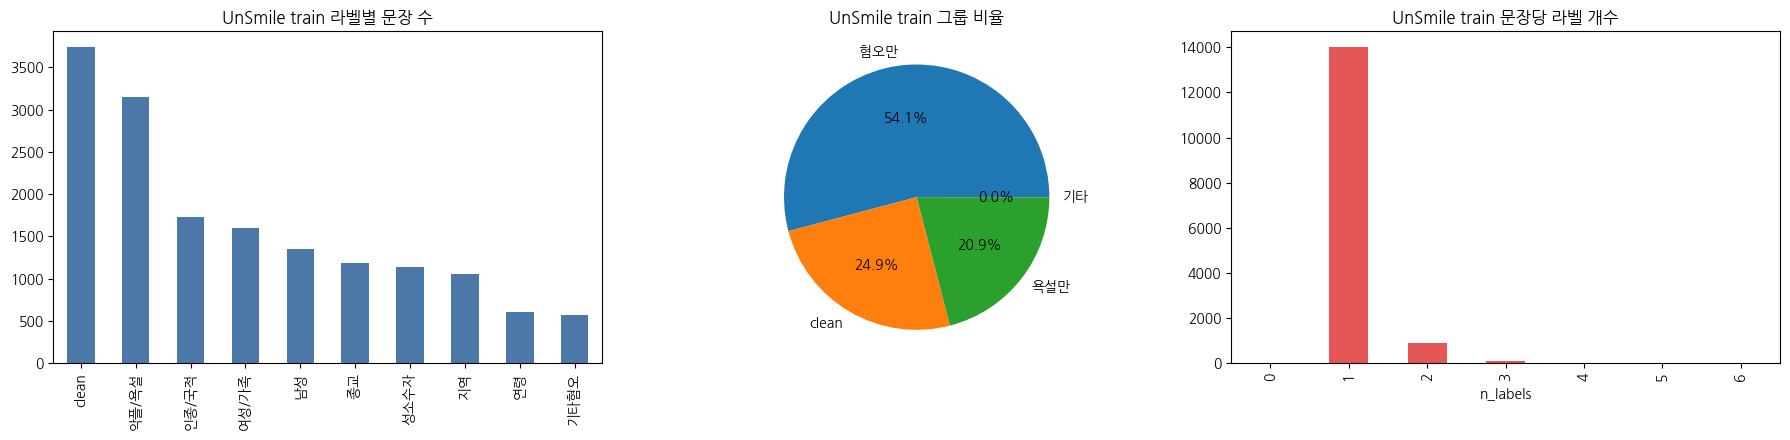


===== [UnSmile valid] 라벨 분포 =====
        개수  비율(%)
clean  935  25.02
악플/욕설  786  21.03
인종/국적  426  11.40
여성/가족  394  10.54
남성     334   8.94
종교     290   7.76
성소수자   280   7.49
지역     260   6.96
연령     146   3.91
기타혐오   134   3.59


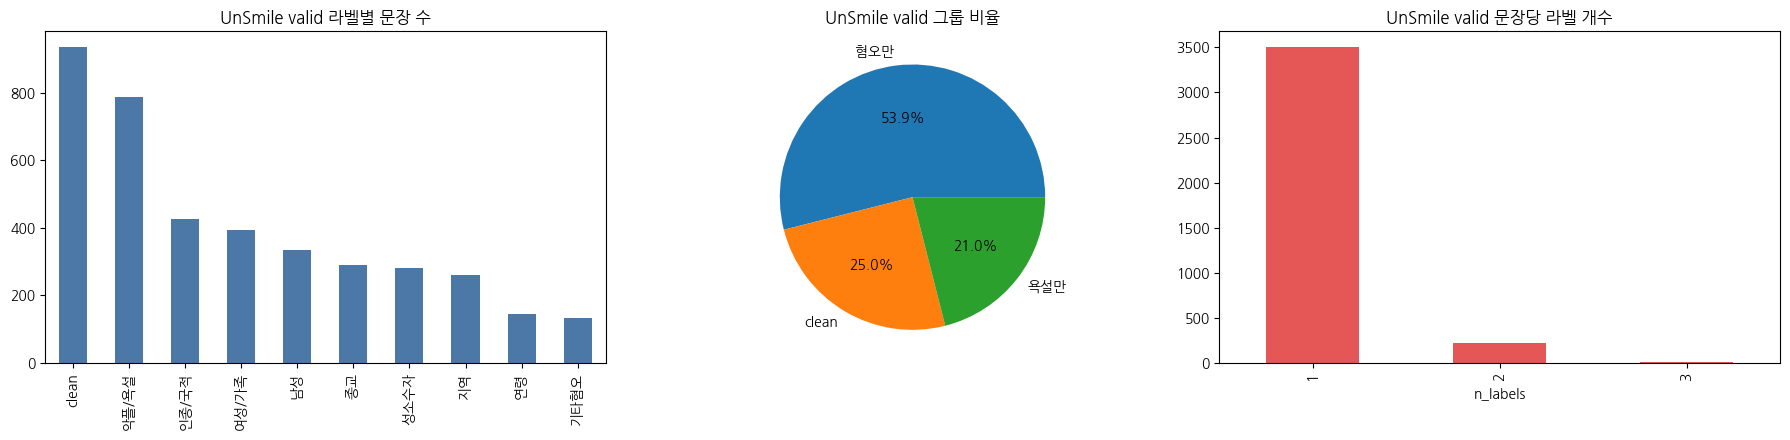

In [12]:
# 라벨 분포 (다중 라벨)
eda_multilabel(us_train, "UnSmile train")
eda_multilabel(us_valid, "UnSmile valid")


===== [UnSmile train] 길이 분포 =====
char_len: 평균 39.8 | 중앙 31 | 90% 82 | 95% 101 | 99% 137 | 최대 155
tok_len: 평균 18.2 | 중앙 14 | 90% 37 | 95% 45 | 99% 61 | 최대 113


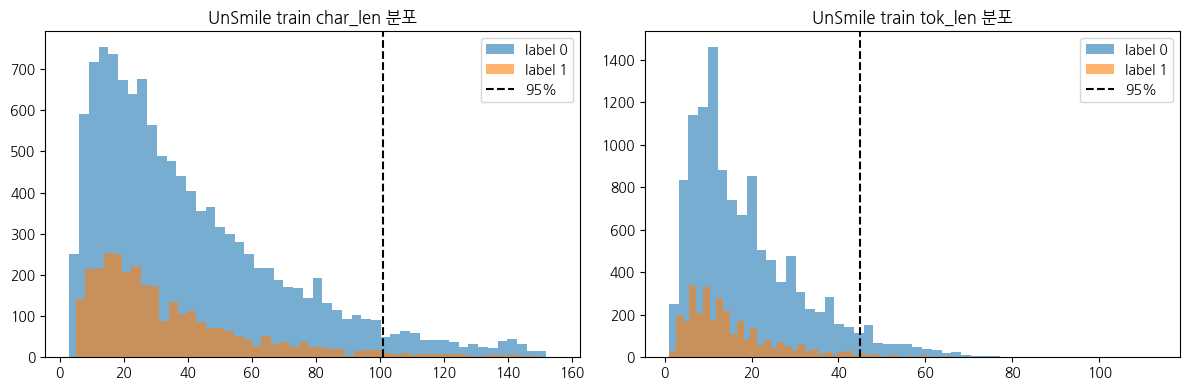

In [13]:
# 길이 분포 (욕설 여부로 나눠서)
us_train["is_curse"] = us_train["악플/욕설"]
_ = eda_length(us_train, "UnSmile train", text_col="문장", label_col="is_curse", tokenizer=tok)

## 3. 베이스라인 평가 (E1)
UnSmile을 **그대로** 썼을 때의 점수임. 학습 후(E2, E3)에 같은 세트로 다시 재서 비교할 것임.

In [14]:
# UnSmile valid: 정규화 방식별 비교 (정답 = 악플/욕설)
valid_eval = us_valid.rename(columns={"문장": "text"}).assign(label=us_valid["악플/욕설"])
res_unsmile = run_eval(valid_eval, "UnSmile valid", norms=("none", "light", "strict", "strict_hy"))

          set      norm score    n  precision  recall     f1    fpr  pr_auc
UnSmile valid      none curse 3737     0.7602  0.5929 0.6662 0.0498  0.7444
UnSmile valid     light curse 3737     0.7728  0.5929 0.6710 0.0464  0.7507
UnSmile valid    strict curse 3737     0.7681  0.5941 0.6700 0.0478  0.7511
UnSmile valid strict_hy curse 3737     0.7685  0.5954 0.6710 0.0478  0.7513


In [15]:
# 문장 바로 넣어 보기: 우회 욕 / 정상 / 오탐 함정
demo(["시1발 진짜", "ㅅㅣ발 놈아", "씨이이발", "시 발 놈 아", "tlqkf",
      "오늘 날씨 좋네", "시발점부터 보자", "수박 씨 발라 먹자"], norm="strict_hy")

'시1발 진짜'                     → '시발 진짜'                  욕설 0.91 | 혐오(1-clean) 0.95
'ㅅㅣ발 놈아'                     → '시발 놈아'                  욕설 0.91 | 혐오(1-clean) 0.94
'씨이이발'                       → '씨발'                     욕설 0.92 | 혐오(1-clean) 0.95
'시 발 놈 아'                    → '시발놈아'                   욕설 0.92 | 혐오(1-clean) 0.95
'tlqkf'                      → '시발'                     욕설 0.90 | 혐오(1-clean) 0.94
'오늘 날씨 좋네'                   → '오늘 날씨 좋네'               욕설 0.06 | 혐오(1-clean) 0.08
'시발점부터 보자'                   → '시발점부터 보자'               욕설 0.90 | 혐오(1-clean) 0.95
'수박 씨 발라 먹자'                 → '수박 씨 발라 먹자'             욕설 0.53 | 혐오(1-clean) 0.75


In [16]:
# 프로브: 유형별로 직접 만든 확인용 문장 (강조 비속어는 욕이 아니라고 판단해 제외)
probe = pd.DataFrame([
    # A. 정규화로 풀리는 우회 (욕)
    ("시1발 진짜", 1, "A_정규화"), ("ㅅㅣ발 놈아", 1, "A_정규화"), ("시 발 놈 아", 1, "A_정규화"),
    ("병1신같네", 1, "A_정규화"), ("씨이이발", 1, "A_정규화"),
    # B. 초성만 (욕)
    ("ㅅㅂ 짜증나", 1, "B_초성"), ("ㅆㅂ 뭐하냐", 1, "B_초성"), ("ㅂㅅ아", 1, "B_초성"),
    ("ㅁㅊㄴ", 1, "B_초성"), ("ㅈㄴ 못하네", 1, "B_초성"),
    # C. 된소리·모음 비틀기 (욕)
    ("씨빨 진짜", 1, "C_비틀기"), ("쉬바 뭐냐", 1, "C_비틀기"), ("시바 꺼져", 1, "C_비틀기"),
    ("십알놈", 1, "C_비틀기"), ("븅신아", 1, "C_비틀기"), ("빙신같은게", 1, "C_비틀기"),
    ("미틴놈", 1, "C_비틀기"), ("닭쳐라", 1, "C_비틀기"), ("개새기", 1, "C_비틀기"), ("개쉐이", 1, "C_비틀기"),
    # D. 한영 변환 (욕)
    ("tlqkf", 1, "D_한영"), ("qudtls", 1, "D_한영"), ("c8 진짜", 1, "D_한영"), ("sibal", 1, "D_한영"),
    # E. 단어 바꿔치기·은어 (욕)
    ("느금마", 1, "E_은어"), ("니애미", 1, "E_은어"), ("몽뭉이 같은 놈", 1, "E_은어"), ("엠창", 1, "E_은어"),
    # F. 오탐 함정 (정상)
    ("시발점부터 보자", 0, "G_함정"), ("다음 역이 시발역이야", 0, "G_함정"), ("수박 씨 발라 먹자", 0, "G_함정"),
    ("내 십팔번은 이 노래", 0, "G_함정"), ("병신년은 2016년이다", 0, "G_함정"), ("새끼 고양이 귀여워", 0, "G_함정"),
    ("다음 주 개강이야", 0, "G_함정"), ("18세 이상 관람가", 0, "G_함정"), ("채팅에서 욕하지 마세요", 0, "G_함정"),
    ("닥쳐올 미래가 걱정이다", 0, "G_함정"), ("ㅎㅏㅇ상 고마워", 0, "G_함정"), ("우리 집 개 산책 시켜야 해", 0, "G_함정"),
], columns=["text", "label", "type"])

In [17]:
# 프로브 평가: 유형별 정답률 (정규화 방식별)
NORMS = ("none", "strict", "strict_hy")
for nm in NORMS:
    s = score_texts(probe["text"], nm, "curse")
    probe[f"score_{nm}"] = s.round(2)
    probe[f"ok_{nm}"] = (s >= 0.5).astype(int) == probe["label"]

print(probe.groupby("type")[[f"ok_{nm}" for nm in NORMS]].mean().round(2))

# 틀린 문장만 (가장 강한 정규화 기준)
display(probe.loc[~probe["ok_strict_hy"], ["type", "text", "label"] + [f"score_{nm}" for nm in NORMS]])

       ok_none  ok_strict  ok_strict_hy
type                                   
A_정규화     1.00       1.00          1.00
B_초성      1.00       1.00          1.00
C_비틀기     0.90       0.90          0.90
D_한영      0.50       0.50          1.00
E_은어      0.50       0.50          0.50
G_함정      0.75       0.75          0.75


,type,text,label,score_none,score_strict,score_strict_hy
17,C_비틀기,닭쳐라,1,0.37,0.37,0.37
24,E_은어,느금마,1,0.11,0.11,0.11
25,E_은어,니애미,1,0.28,0.28,0.28
28,G_함정,시발점부터 보자,0,0.90,0.90,0.90
30,G_함정,수박 씨 발라 먹자,0,0.53,0.53,0.53
32,G_함정,병신년은 2016년이다,0,0.75,0.75,0.75


In [18]:
# KOTOX test (난이도별, 비틀어 쓴 욕 평가)
res_kotox = run_kotox(norms=NORMS)

       set      norm score   n  precision  recall     f1    fpr  pr_auc
KOTOX-easy      none curse 460     0.8151  0.4217 0.5559 0.0957  0.7615
KOTOX-easy    strict curse 460     0.8304  0.4043 0.5439 0.0826  0.7687
KOTOX-easy strict_hy curse 460     0.8304  0.4043 0.5439 0.0826  0.7683
         set      norm score   n  precision  recall     f1   fpr  pr_auc
KOTOX-normal      none curse 460     0.7869  0.4174 0.5455 0.113  0.7378
KOTOX-normal    strict curse 460     0.7797  0.4000 0.5287 0.113  0.7319
KOTOX-normal strict_hy curse 460     0.7797  0.4000 0.5287 0.113  0.7321
       set      norm score   n  precision  recall     f1    fpr  pr_auc
KOTOX-hard      none curse 460     0.7083  0.3696 0.4857 0.1522  0.6605
KOTOX-hard    strict curse 460     0.6972  0.3304 0.4484 0.1435  0.6527
KOTOX-hard strict_hy curse 460     0.6972  0.3304 0.4484 0.1435  0.6538
        set      norm score    n  precision  recall     f1    fpr  pr_auc
KOTOX-total      none curse 1380     0.7701  0.4029 0.5290

In [19]:
# 속도: 한 문장 처리 시간 (정규화 + 모델)
_ = latency(norm="strict_hy")

[Tesla T4] p50 10.4ms | p95 11.2ms | p99 12.7ms


## 4. AI Hub 유해표현 데이터
- stage1: 유해 여부 (content, label)
- stage2: 유형 11개 + 정상 (값 0~3 = 강도)

**라벨 방침:** 욕설·모욕 > 0 → 1 / 정상만 → 0 / 다른 혐오만 → 따로 보관 (학습에 0으로 넣을지는 학습 단계에서 결정)

In [20]:
# 불러오기
s1 = pd.read_csv(f"{BASE}/1. 유해표현 검출/stage1_data.csv")
s2 = pd.read_csv(f"{BASE}/2. 유해 카테고리 분류/stage2_data.csv")
print("stage1", s1.shape, "| stage2", s2.shape)
display(s1.head(3)); display(s2.head(3))

stage1 (200000, 2) | stage2 (200000, 13)


,content,label
0,"""예수쟁이들은 모하냐?저 주둥이를 안 틀어막고?같은 것들이냐?""",1
1,저 #@이름# 때문에 이''꼴'''났디 빨리 ''처'''내려와라 ''신물'''난다,1
2,''쪽팔려'''서 외국에서 얼굴을 못들겠다. ''Fuxx''' MBC너넨 영원히 ''거른'''다.,1


,문장,모욕,욕설,외설,폭력위협/범죄조장,성혐오,연령,인종/지역,장애,종교,정치성향,직업,정상
0,독점은 당연히 막아야지. 이건 사장경제는 경쟁으로 가야 정상순환되는데 독점이 되면 기업이 공산국가처럼 독재하는건데,0,0,0,0,0,0,0,0,0,1,0,0
1,눈 작다고 한 마디 한 걸로 퇴출시키는 그리스가 훨씬 선진국이네 ㅋㅋㅋ MBC는 사과문 ''끄적'''이고 ''버로우 타'''고 있는데,2,0,0,0,0,0,0,0,0,0,0,0
2,''도쿄만 똥물'''도 문제지만 해안에 모래는 후쿠시마 흙으로 채웠는데 이선수들 피폭이 걱정된다,2,0,0,0,0,0,2,0,0,0,0,0


In [21]:
# 분포와 문제 확인
CATS = list(s2.columns[1:])                     # 문장 다음 열부터 유형
for c in CATS:
    print(f"{c:12}", s2[c].value_counts().sort_index().to_dict())

print("\nstage1 라벨:", s1.label.value_counts().to_dict())
print("두 파일 겹치는 문장:", len(set(s1.content) & set(s2["문장"])), "→ stage2만 사용")
print("'' 유해 구간 표시 비율  s1:", s1.content.str.contains("''").mean().round(3),
      "| s2:", s2["문장"].str.contains("''").mean().round(3))
print("#@ 비식별 태그 비율 s1:", s1.content.str.contains("#@").mean().round(3))

모욕           {0: 154231, 2: 43387, 3: 2382}
욕설           {0: 169672, 1: 18073, 2: 10007, 3: 2248}
외설           {0: 197602, 1: 1333, 2: 872, 3: 193}
폭력위협/범죄조장    {0: 193441, 1: 2715, 2: 2983, 3: 861}
성혐오          {0: 195354, 1: 2429, 2: 1845, 3: 372}
연령           {0: 197865, 1: 1175, 2: 844, 3: 116}
인종/지역        {0: 181629, 1: 10155, 2: 6997, 3: 1219}
장애           {0: 198208, 1: 1606, 2: 158, 3: 28}
종교           {0: 198823, 1: 629, 2: 431, 3: 117}
정치성향         {0: 164515, 1: 16330, 2: 16299, 3: 2856}
직업           {0: 191985, 1: 4058, 2: 3566, 3: 391}
정상           {0: 100000, 1: 100000}

stage1 라벨: {1: 100000, 0: 100000}
두 파일 겹치는 문장: 170091 → stage2만 사용
'' 유해 구간 표시 비율  s1: 0.301 | s2: 0.43
#@ 비식별 태그 비율 s1: 0.108


In [22]:
# 라벨 변환
OTHER = [c for c in CATS if c not in ("모욕", "욕설", "정상")]   # 욕설·모욕 외 혐오 유형

def clean(t):
    t = re.sub(r"'{2,}", "", str(t))            # 유해 구간 표시 '' ''' 제거 (지름길 학습 방지)
    t = re.sub(r"#@[^#]*#", "OO", t)            # #@이름# 같은 비식별 태그 → OO
    t = t.replace("\\", "").strip('"')
    return re.sub(r"\s+", " ", t).strip()

ah = s2.rename(columns={"문장": "raw"})
pos   = (ah["욕설"] > 0)                        # 욕설 → 1
neg   = (ah["정상"] == 1) & (ah[OTHER].sum(axis=1) == 0) & ~pos     # 정상만 → 0
other = ~pos & (ah["정상"] == 0)                                     # 다른 혐오만
ah["label"] = np.select([pos, neg], [1, 0], default=-1)              # -1 = 학습 라벨에서 제외
print("변환:", ah["label"].value_counts().to_dict(), "| 다른 혐오만:", other.sum())

# 유해 구간 표시가 욕 쪽에만 몰려 있는지 (몰려 있으면 지우는 게 맞다는 근거)
print("'' 표시 비율 (라벨별):", ah.groupby("label")["raw"].apply(lambda s: s.str.contains("''").mean().round(3)).to_dict())
print("\n욕설 강도 1 샘플:"); print(ah.loc[ah["욕설"] == 1, "raw"].sample(8, random_state=0).to_string())

변환: {0: 100000, -1: 69672, 1: 30328} | 다른 혐오만: 69672
'' 표시 비율 (라벨별): {-1: 0.806, 0: 0.0, 1: 0.983}

욕설 강도 1 샘플:
60956                     요노마도 대통령 까부쳐서 ''국짐당'''한테 잘보여서 담에도 부시장 해''쳐''' 묵을라꼬 ''지랄터네'''\n
11567                                                         대한민국 청와대는 뻥이나 ''쳐'''대고 ?\n
15141                                  한겨레 답다정치꾼들 털어서 먼지 안날''놈'''있으면 말해봐라다 ''도적'''''놈'''
17920                                           이''놈''' 뒤에 #@이름#가 있었네 #@이름#부터 잡아넣고 조사해라ㆍ
25699          ''뻔뻔'''함 ''무능''' ''무식''' ''지랄''' ....''좌파'''들은 부끄러운 줄 모르고 오히려 물려고 하는게 문제다
66015    인간도 아녀 민주노총 이나라 떠나라 양심도 없는 ''놈'''들 니들대문에 확산됐지. 온국민만 또 힘들어지고 중소 상인들이 힘들어지는데 니...
32647    역시  ''빨..걍이'''들은  세월호 가짜선동으로  청와대 붛법점거하더디  4년만에 나라 ''말아먹'''고... 하는짓이 고작  저런거...
95754    \n#@이름#은 이중대 같은 ''놈'''임. #@이름#등 대선 주자는 온갖 비방과 억지로 지지율 떨어 트리고 이 엄청난 #@이름# 캠프 ...


정제 후: 130321 {0: 99999, 1: 30322} | 다른 혐오: 69642

===== [AI Hub 정제 후] 라벨 분포 =====
          개수  비율(%)
label              
0      99999  76.73
1      30322  23.27


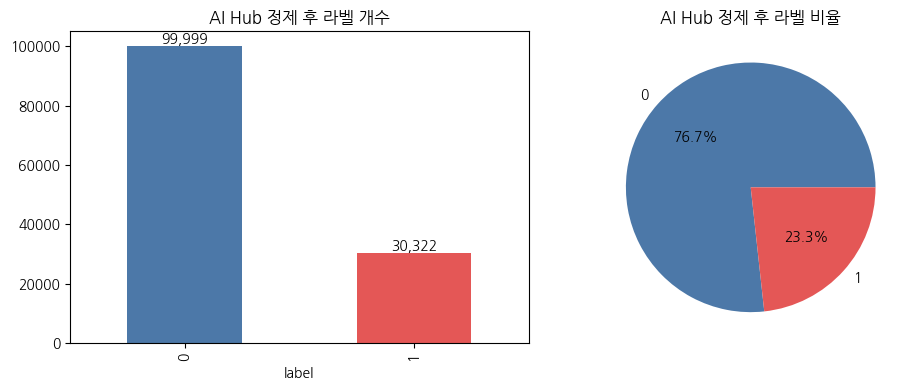

In [23]:
# 정제: 표시·태그 제거 → 짧은 문장 제거 → 라벨 충돌 제거 → 중복 제거 → 평가 세트와 겹치는 문장 제거
def tidy(d):
    d = d.assign(text=d["raw"].map(clean))
    d = d[d["text"].str.len() >= 2]
    conflict = d.groupby("text")["label"].nunique().loc[lambda s: s > 1].index
    return d[~d["text"].isin(conflict)].drop_duplicates("text")[["text", "label"]]

# 평가에 쓰는 문장 (학습에 들어가면 점수가 부풀려짐)
EVAL_TEXTS = set(valid_eval["text"]) | set(load_kotox("total", "test")["text"]) | set(probe["text"])

df  = tidy(ah[ah["label"] >= 0])
oth = tidy(ah[other].assign(label=0))
df  = df[~df["text"].isin(EVAL_TEXTS)]
oth = oth[~oth["text"].isin(EVAL_TEXTS | set(df["text"]))]
print("정제 후:", len(df), df["label"].value_counts().to_dict(), "| 다른 혐오:", len(oth))
eda_labels(df, "AI Hub 정제 후")

In [24]:
# 토큰 길이: MAX_LEN 64로 충분한지 (5,000개 샘플)
tl = df["text"].sample(5000, random_state=0).map(lambda t: len(tok(t)["input_ids"]))
print(tl.describe(percentiles=[.5, .9, .95, .99]).round(1).to_dict())
print("64 초과 비율:", (tl > 64).mean().round(3))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (313 > 300). Running this sequence through the model will result in indexing errors


{'count': 5000.0, 'mean': 28.8, 'std': 21.0, 'min': 3.0, '50%': 22.0, '90%': 51.0, '95%': 65.0, '99%': 113.0, 'max': 313.0}
64 초과 비율: 0.053


In [25]:
# 분할 8:1:1 (중복을 먼저 지웠으므로 같은 문장이 train과 test에 함께 들어가지 않음) → 드라이브 저장
def split_save(d, prefix, stratify=True):
    st = d["label"] if stratify else None
    tr, tmp = train_test_split(d, test_size=0.2, stratify=st, random_state=42)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["label"] if stratify else None, random_state=42)
    for name, part in [("train", tr), ("valid", va), ("test", te)]:
        part.to_csv(f"{OUT}/{prefix}_{name}.csv", index=False)
    print(f"{prefix}: train {len(tr)} / valid {len(va)} / test {len(te)} | 1 비율 {tr['label'].mean():.3f}")
    return tr, va, te

tr, va, te = split_save(df, "aihub")                          # 욕설vs 정상

aihub: train 104256 / valid 13032 / test 13033 | 1 비율 0.233


In [26]:
# 베이스라인을 AI Hub test에서 측정
res_aihub = run_eval(te, "AIHub-test", norms=("none", "strict"), score_types=("curse", "any_hate"))

       set   norm    score     n  precision  recall     f1    fpr  pr_auc
AIHub-test   none    curse 13033     0.8993  0.5621 0.6918 0.0191  0.7866
AIHub-test   none any_hate 13033     0.8426  0.9674 0.9007 0.0548  0.9722
AIHub-test strict    curse 13033     0.9020  0.5612 0.6919 0.0185  0.7845
AIHub-test strict any_hate 13033     0.8463  0.9657 0.9021 0.0532  0.9719


## 5. KOTOX EDA
KOTOX는 비틀어 쓴 욕 데이터 (난이도 easy / normal / hard). **라벨은 바꾸지 않음**: 욕 라벨 샘플을 보니 약 80%가 우리 기준과 맞았음.
그래서 강조 비속어처럼 우리 기준과 다른 문장이 일부 섞여 있음 (아래 라벨 확인용 파일로 팀에서 다시 확인).

순서: 샘플 보기 → `[UNK]` 분석 (→ 정규화 `max`를 만든 근거) → 구조·결측·중복 → 누수 → 난이도별 분포 → 정제 후 저장

In [27]:
kx_tr = load_kotox("total", "train")
print(len(kx_tr), kx_tr.label.value_counts().to_dict())
display(kx_tr[kx_tr.label == 1].sample(15, random_state=0))   # 욕 없는 혐오가 많은지 확인

11010 {0: 5505, 1: 5505}


,text,label
7246,어ㅓ ✪ 강아지 이…름 ✪ 빠．안네 ㅋㅋ ✧ ♥ 하는 ◯☆◯ ●짇또1● 그켜미야 ≥ㅇ≤ ★ 《꼴통같은》 개야 ≥ㅅ≤,1
9821,울린는 메묘뤼열횰꽈쥐 1간식 30뷴윈냐 쾃테 결려셔 존나 늦음었 쒯.,1
10787,아 그럵우ㅓㄱ애뜨 말씀머로 배워서 나쁠 건 없네겠.,1
7061,차 빨리 각꼬 시픈대 못나오면 열받겠네.. 개자식뜰 차 빨리 네노으라지,1
5647,"쥬귀젹º¹료 받아주는 걸로 만족해라, 결레야.",1
10389,"오캐이, ㅓコ 걑위 관종 쥣 굳잡하자.",1
10744,데스코 멋진 통꿀토 있따는태 거기도 家子 찐따루저새끼야,1
5520,응. 냄져테한들도 좋을 줈은 몴랗늖데,1
9804,◯‥코로나◯ 【♡】 《때묺에》 ✦ ●미꾹● ♧ ✪ ◉애틀◉ ≥ㅇ≤ 똛뽜춡 ◎사랆◎ 없º니까 ○♧○ 거리에 ♥ 버려지겠비. ★ ≥ㅂ≤ ♥ ∥✩∥,1
10499,위제 지잡머 찌찔二틀처럼 샬쥐 말ㅍ 인생 체때료 쌀아야껬多,1


In [28]:
# KOTOX 문장 분포 및 UNK 확인
kx = kx_tr.copy()                 # 위 셀에서 이미 불러옴
kx["norm"] = kx["text"].astype(str).map(lambda t: normalize(t, "strict_hy"))

def tok_stats(t):
    ids = tok(t)["input_ids"]
    return len(ids), sum(i == tok.unk_token_id for i in ids)

kx[["n_tok", "n_unk"]] = kx["norm"].apply(lambda t: pd.Series(tok_stats(t)))
kx["unk_rate"] = kx["n_unk"] / kx["n_tok"]

# 라벨별: 길이, 64 초과, [UNK] 비율, [UNK]가 있는 문장 비율
display(kx.groupby("label").agg(
    문장수=("text", "size"), 평균토큰=("n_tok", "mean"),
    초과64=("n_tok", lambda s: (s > 64).mean()),
    UNK비율=("unk_rate", "mean"), UNK문장=("n_unk", lambda s: (s > 0).mean())).round(3))

# 모르는 글자가 많은 문장 예시
display(kx.sort_values("unk_rate", ascending=False)[["text", "norm", "label", "unk_rate"]].head(8))

,문장수,평균토큰,초과64,UNK비율,UNK문장
label,,,,,
0,5505,15.498,0.000,0.150,0.765
1,5505,21.088,0.003,0.146,0.798


,text,norm,label,unk_rate
4787,난 《✩。》 ♧ ✧ 《4000원짜ㅣㄹ》 〃♤!〃 《◈미실용에◈》 ♡ ◎㈐녀◎ ♧,난 《✩。》 ♧ ✧ 《400원짜ㅣㄹ》 〃♤!〃 《◈미실용에◈》 ♡ ◎㈐녀◎ ♧,0,0.818182
2311,┃ 《◯나도◯》 … 【☆】 ♧ ∥홍콩∥ ☆ ∥여앵∥ ★ ㉮、보ㅍ ∥…십따∥ 【ㅋㅋ】 ♤ º┃,┃ 《◯나도◯》 … 【☆】 ♧ ∥홍콩∥ ☆ ∥여앵∥ ★ ㉮、보ㅍ ∥…십따∥ 【ㅋㅋ】 ♤ º┃,0,0.814815
9869,헕 10ㅏNㅣㅒ만 〃처먻읋〃 ✩ 쑤 잇굱 【♧】 ★ ≥ㅃ≤ ◯✧◯ ≥ㅂ≤ 친。짜˚ KㅓK같네,헕 10ㅏㅣㅒ만 〃처먻읋〃 ✩ 쑤 잇굱 【♧】 ★ ≥ㅃ≤ ◯✧◯ ≥ㅂ≤ 친。짜˚ Kㅓ같네,1,0.809524
3134,「◈응◈」 ‥ 「✪」 나도 ○궁금해서○ ★ ≥ㅁ≤ 《한번》 ✩ 봫는데 영상처ㅣㄹㅓㄴ 『그럳게』 ◯✪¿◯ ≥ㅂ≤ ✦ 멌지지¨ 않더ㅓㄹ1亡,「◈응◈」 ‥ 「✪」 나도 ○궁금해서○ ★ ≥ㅁ≤ 《한번》 ✩ 봫는데 영상처ㅣ런 『그럳게』 ◯✪¿◯ ≥ㅂ≤ ✦ 멌지지¨ 않더ㅓㄹ1亡,0,0.806452
5489,◉쌍땀◉ ✧ ε♥з 받º면 한 ♡ 펀 ★ 받ㅓㅇ봐ㅓㄹ ♡ 《★》,◉쌍땀◉ ✧ ε♥з 받º면한 ♡ 펀 ★ 받ㅓㅇ봐ㅓㄹ ♡ 《★》,0,0.785714
4594,┫ 「、ㅋㅋ」 …¨ ✪ ◊곧◊ 핤 〃옏정인닉까〃 촡뎅헸줌 ┫,┫ 「、ㅋㅋ」 …¨ ✪ ◊곧◊ 핤 〃옏정인닉까〃 촡뎅헸줌 ┫,0,0.764706
10775,평ㅏ>에도찌찔이뜰이처치르는캐깥은짓들엄청많은테꼬봉들二多덮ㅏㅇ주니까흐지父지넘ㅏㅇㅓㄴ는커찌,평ㅏ에도찌찔이뜰이처치르는캐깥은짓들엄청많은테꼬봉들二多덮ㅏㅇ주니까흐지父지넘ㅏ언는커찌,1,0.750000
3002,ㅋㅋ ✦ ◈…✩◈ ♡ ≥ㅁ≤ ●✧● ☆ ˆ《치마토》 ♡ ˛입기 ☆ 싩!어1,ㅋㅋ ✦ ◈…✩◈ ♡ ≥ㅁ≤ ●✧● ☆ ˆ《치마토》 ♡ ˛입기 ☆ 싩어1,0,0.750000


In [29]:
# KOTOX 정규화
from collections import Counter

unk_chars = Counter()
for t in kx["norm"]:
    for ch in set(t):
        if not ch.isspace() and tok.unk_token_id in tok(ch, add_special_tokens=False)["input_ids"]:
            unk_chars[ch] += 1

top = pd.DataFrame(unk_chars.most_common(40), columns=["글자", "문장수"])
top["종류"] = top["글자"].map(lambda c: "한글" if "가" <= c <= "힣" else
                              "한자" if "\u4e00" <= c <= "\u9fff" else
                              "자모" if "ㄱ" <= c <= "ㅣ" else "기호/기타")
display(top)
print(top.groupby("종류")["문장수"].sum())

,글자,문장수,종류
0,ㅓ,1834,자모
1,ㅣ,613,자모
2,≥,595,기호/기타
3,≤,590,기호/기타
4,ㅏ,579,자모
5,♡,566,기호/기타
6,二,516,한자
7,♤,502,기호/기타
8,ㅠ,482,자모
9,♧,480,기호/기타


종류
기호/기타    10825
자모        3508
한자        1908
Name: 문장수, dtype: int64


In [30]:
# KOTOX 전체 불러오기: 난이도(easy/normal/hard) × 분할(train/valid/test)
LEVELS, SPLITS = ["easy", "normal", "hard"], ["train", "valid", "test"]
kx_all = pd.concat([load_kotox(lv, sp).assign(level=lv, split=sp) for lv in LEVELS for sp in SPLITS],
                   ignore_index=True)
kx_total = {sp: load_kotox("total", sp) for sp in SPLITS}       # 학습과 평가에 쓰는 것은 total

print("난이도별 합:", kx_all.groupby("split").size().to_dict(),
      "| total:", {sp: len(d) for sp, d in kx_total.items()})
eda_structure(kx_total["train"], "KOTOX total train")

난이도별 합: {'test': 1380, 'train': 11010, 'valid': 1374} | total: {'train': 11010, 'valid': 1374, 'test': 1380}
===== [KOTOX total train] 구조 =====
행 11,010개 / 열 2개
text     object
label     int64


,text,label
0,ユ냥 셍활비가 식비야 ㅋㅋ,0
1,근닉까 그 롱롱 섣절리 한 병원은 묵묵부답이래.,0
2,多른 거 ㅋㅋ 죻야햐쟎야?,0
3,五 ㅋㅋ 익스펜시브 거 사 먹었네,0
4,난 nuna 두명이 있는데 ㈔i㈎ 진짜 gㅔ 좋아,0


In [31]:
# 결측, 빈 문장, 중복, 같은 문장인데 라벨이 다른 경우
for sp, d in kx_total.items():
    eda_missing(d, f"KOTOX {sp}")
    eda_duplicates(d, f"KOTOX {sp}")


===== [KOTOX train] 결측치 =====
       결측 개수  비율(%)
text       0    0.0
label      0    0.0
빈 문자열 문장: 0개

===== [KOTOX train] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 0개
같은 문장인데 라벨이 다름: 0개

===== [KOTOX valid] 결측치 =====
       결측 개수  비율(%)
text       0    0.0
label      0    0.0
빈 문자열 문장: 0개

===== [KOTOX valid] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 0개
같은 문장인데 라벨이 다름: 0개

===== [KOTOX test] 결측치 =====
       결측 개수  비율(%)
text       0    0.0
label      0    0.0
빈 문자열 문장: 0개

===== [KOTOX test] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 0개
같은 문장인데 라벨이 다름: 0개


In [32]:
# 누수: 같은 문장이 학습과 평가 양쪽에 있으면 점수가 부풀려짐
ah_train_csv = pd.read_csv(f"{OUT}/aihub_train.csv")
ah_test_csv  = pd.read_csv(f"{OUT}/aihub_test.csv")

print("--- KOTOX 안 ---")
check_overlap(kx_total["train"], kx_total["valid"], "KOTOX train", "KOTOX valid")
check_overlap(kx_total["train"], kx_total["test"],  "KOTOX train", "KOTOX test")
check_overlap(kx_total["valid"], kx_total["test"],  "KOTOX valid", "KOTOX test")

print("\n--- 다른 데이터와 (같이 섞어서 학습하므로) ---")
check_overlap(kx_total["train"], ah_test_csv, "KOTOX train", "AI Hub test")
check_overlap(ah_train_csv, kx_total["test"], "AI Hub train", "KOTOX test")
check_overlap(kx_total["train"], valid_eval, "KOTOX train", "UnSmile valid")
check_overlap(kx_total["train"], probe, "KOTOX train", "프로브")

# 정규화 후 같아지는 문장 (같은 원문을 다르게 비튼 문장이 train과 test에 나뉘었는지)
nkey = lambda s: re.sub(r"[\W_]", "", normalize(str(s), "max"))
tr_k = set(kx_total["train"]["text"].map(nkey)); te_k = set(kx_total["test"]["text"].map(nkey))
print(f"\n[정규화 후 비교] KOTOX train ∩ test: {len(tr_k & te_k):,}개")

--- KOTOX 안 ---
[누수 확인] KOTOX train ∩ KOTOX valid 같은 문장: 0개
[누수 확인] KOTOX train ∩ KOTOX test 같은 문장: 0개
[누수 확인] KOTOX valid ∩ KOTOX test 같은 문장: 0개

--- 다른 데이터와 (같이 섞어서 학습하므로) ---
[누수 확인] KOTOX train ∩ AI Hub test 같은 문장: 0개
[누수 확인] AI Hub train ∩ KOTOX test 같은 문장: 0개
[누수 확인] KOTOX train ∩ UnSmile valid 같은 문장: 0개
[누수 확인] KOTOX train ∩ 프로브 같은 문장: 0개

[정규화 후 비교] KOTOX train ∩ test: 0개


,문장수,욕비율,평균글자,UNK_원문,UNK_정규화후
level,,,,,
easy,3670,0.5,30.567,0.106,0.022
normal,3670,0.5,32.044,0.147,0.034
hard,3670,0.5,32.910,0.184,0.050



===== [KOTOX total train] 라벨 분포 =====
         개수  비율(%)
label             
0      5505   50.0
1      5505   50.0


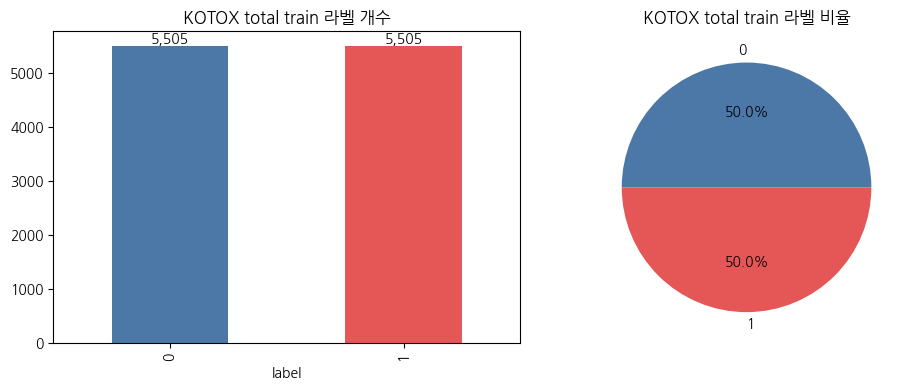


===== [KOTOX easy train] 길이 분포 =====
char_len: 평균 30.6 | 중앙 28 | 90% 48 | 95% 57 | 99% 81 | 최대 122
tok_len: 평균 15.8 | 중앙 14 | 90% 25 | 95% 30 | 99% 41 | 최대 67


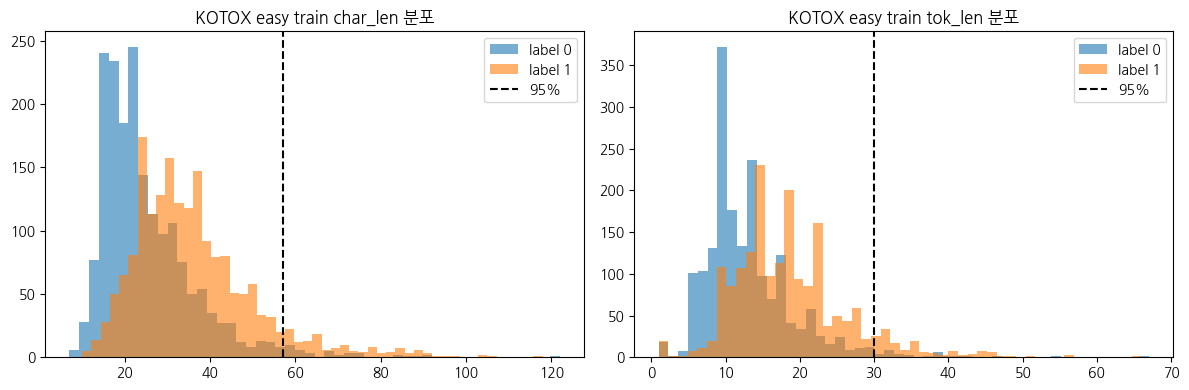


===== [KOTOX normal train] 길이 분포 =====
char_len: 평균 32.0 | 중앙 29 | 90% 51 | 95% 61 | 99% 87 | 최대 152
tok_len: 평균 17.0 | 중앙 15 | 90% 28 | 95% 33 | 99% 45 | 최대 75


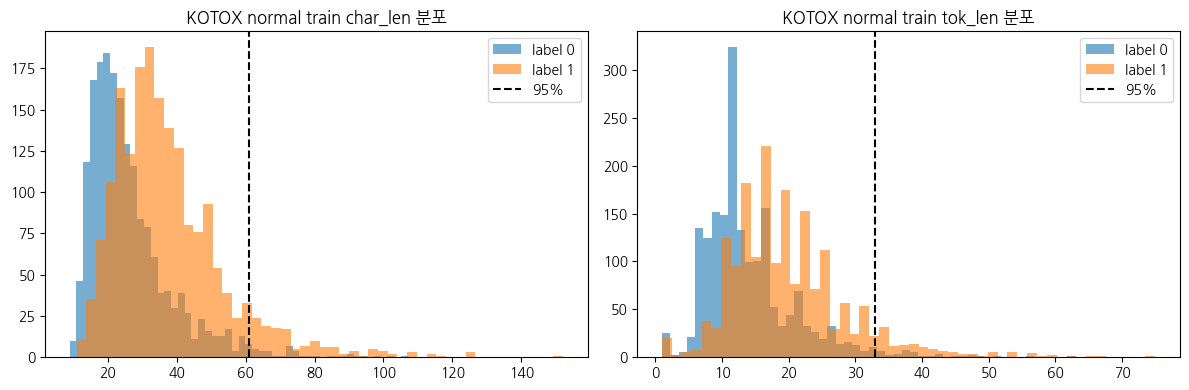


===== [KOTOX hard train] 길이 분포 =====
char_len: 평균 32.9 | 중앙 29 | 90% 54 | 95% 65 | 99% 92 | 최대 170
tok_len: 평균 17.4 | 중앙 16 | 90% 30 | 95% 35 | 99% 50 | 최대 94


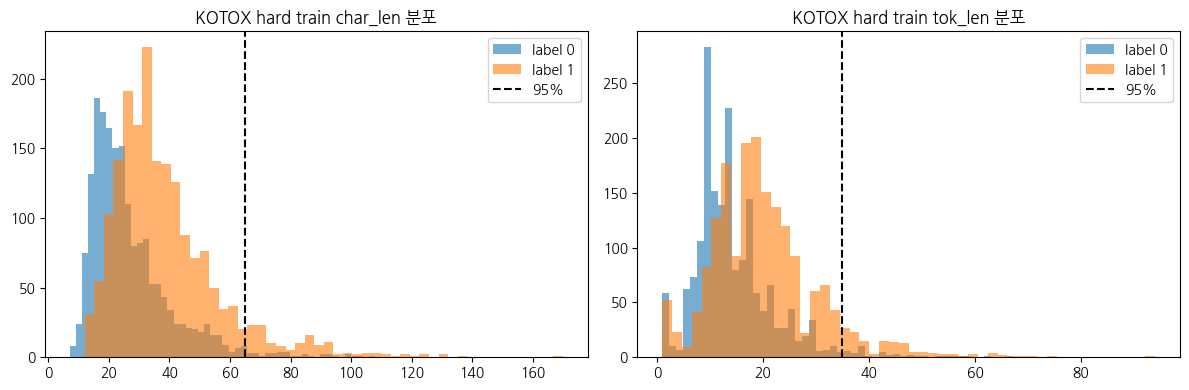

In [33]:
# 난이도별: 문장 수, 욕 비율, 길이, [UNK] 비율 (원문 vs 정규화 max)
def unk_rate(t):
    ids = tok(t)["input_ids"]
    return sum(i == tok.unk_token_id for i in ids) / len(ids)

tr_lv = kx_all[kx_all["split"] == "train"].copy()
tr_lv["text"] = tr_lv["text"].astype(str)
tr_lv["char_len"] = tr_lv["text"].str.len()
tr_lv["unk_원문"] = tr_lv["text"].map(unk_rate)
tr_lv["unk_max"] = tr_lv["text"].map(lambda t: unk_rate(normalize(t, "max")))

display(tr_lv.groupby("level").agg(
    문장수=("text", "size"), 욕비율=("label", "mean"), 평균글자=("char_len", "mean"),
    UNK_원문=("unk_원문", "mean"), UNK_정규화후=("unk_max", "mean")).reindex(LEVELS).round(3))

eda_labels(kx_total["train"], "KOTOX total train")
for lv in LEVELS:
    _ = eda_length(tr_lv[tr_lv["level"] == lv], f"KOTOX {lv} train", tokenizer=tok)

In [34]:
# 라벨 일치율 확인용: 욕 라벨 100개를 뽑아 드라이브에 저장 → 팀이 our_label 열에 0/1을 채움
# (앞의 15개 샘플로 본 "약 80% 일치"를 더 큰 표본으로 확인하기 위함)
chk_path = f"{OUT}/kotox_label_check.csv"
if not os.path.exists(chk_path):                     # 이미 채운 파일을 덮어쓰지 않음
    (kx_total["train"].query("label == 1").sample(100, random_state=42)[["text", "label"]]
        .assign(our_label="").to_csv(chk_path, index=False, encoding="utf-8-sig"))
    print("저장:", chk_path, "→ our_label 열을 채운 뒤 다시 실행하면 일치율이 나옴")
else:
    chk = pd.read_csv(chk_path)
    done = chk["our_label"].notna() & (chk["our_label"].astype(str).str.strip() != "")
    if done.any():
        agree = (chk.loc[done, "our_label"].astype(int) == chk.loc[done, "label"]).mean()
        print(f"라벨 일치율: {agree:.2%} ({done.sum()}개 확인)")
    else:
        print("아직 our_label이 비어 있음:", chk_path)

아직 our_label이 비어 있음: /content/drive/MyDrive/Nyung/data/processed/kotox_label_check.csv


In [35]:
# 정제: 결측·빈 문장 제거 → 라벨 충돌 제거 → 중복 제거 → 평가 문장과 겹치는 문장 제거 → 저장
# test는 E1·E2와 같은 시험지를 유지하려고 손대지 않음 (위에서 확인만 함)
def tidy_kotox(d, drop_texts=frozenset()):
    d = d.dropna(subset=["text", "label"]).copy()
    d["text"] = d["text"].astype(str).str.strip()
    d = d[d["text"] != ""]
    conflict = d.groupby("text")["label"].nunique().loc[lambda s: s > 1].index
    d = d[~d["text"].isin(conflict)].drop_duplicates("text")
    d = d[~d["text"].isin(drop_texts)]
    return d.assign(label=d["label"].astype(int))[["text", "label"]]

EVAL_ALL = (set(kx_total["test"]["text"]) | set(valid_eval["text"]) | set(probe["text"])
            | set(ah_test_csv["text"]))
kx_va_c = tidy_kotox(kx_total["valid"], EVAL_ALL)
kx_tr_c = tidy_kotox(kx_total["train"], EVAL_ALL | set(kx_va_c["text"]))

for name, before, after in [("train", kx_total["train"], kx_tr_c), ("valid", kx_total["valid"], kx_va_c)]:
    after.to_csv(f"{OUT}/kotox_{name}.csv", index=False)
    print(f"KOTOX {name}: {len(before):,} → {len(after):,} (제거 {len(before) - len(after)}) "
          f"| 욕 비율 {after['label'].mean():.3f} → {OUT}/kotox_{name}.csv")

KOTOX train: 11,010 → 11,010 (제거 0) | 욕 비율 0.500 → /content/drive/MyDrive/Nyung/data/processed/kotox_train.csv
KOTOX valid: 1,374 → 1,374 (제거 0) | 욕 비율 0.500 → /content/drive/MyDrive/Nyung/data/processed/kotox_valid.csv


## 6. 말장난형 우회 욕
수박씨 발라먹을 놈, 조카 18색 크레파스 같은 표현. 정규화로는 풀 수 없고(띄어쓰기를 지우면 정상 문장도 걸림), 학습으로 문맥을 가르쳐야 함.

In [36]:
# 기존 데이터에 말장난 표현이 얼마나 있는지 (AI Hub + KOTOX)
PUN_WORDS = ["수박씨", "조카크레파스", "조까", "십장생", "시베리아", "신발끈", "개나리", "18색", "씨발라"]

kotox = pd.concat([load_kotox("total", sp) for sp in ("train", "valid", "test")])
ah_flat = df["text"].str.replace(" ", "")
kx_norm = kotox["text"].astype(str).map(lambda t: normalize(t, "strict_hy").replace(" ", ""))

rows = []
for w in PUN_WORDS:
    a, k = df[ah_flat.str.contains(w)], kotox[kx_norm.str.contains(w)]
    rows.append({"표현": w, "AI Hub": len(a), "AI Hub 욕 비율": round(a.label.mean(), 2) if len(a) else None,
                 "KOTOX": len(k)})
display(pd.DataFrame(rows))

,표현,AI Hub,AI Hub 욕 비율,KOTOX
0,수박씨,1,1.0,0
1,조카크레파스,0,NaN,0
2,조까,10,1.0,0
3,십장생,4,1.0,0
4,시베리아,4,0.0,1
5,신발끈,5,0.8,0
6,개나리,3,1.0,1
7,18색,0,NaN,0
8,씨발라,1,1.0,0


In [37]:
# 말장난 대조쌍 생성: (욕으로 쓰는 형태들, 원래 뜻의 정상 문장들)
PUNS = {
    "수박씨":      (["수박씨 발라먹을", "수박씨 발라버릴"],
                    ["수박씨 발라 먹자", "수박씨는 발라내고 줘", "수박씨 뱉지 말고 버려"]),
    "시베리아":    (["시베리아", "시베리아 벌판에서 귤이나 깔"],
                    ["시베리아는 정말 춥대", "시베리아 횡단열차 타보고 싶다"]),
    "십장생":      (["십장생", "십장생 같은"],
                    ["십장생은 장수를 상징하는 열 가지야", "민화에 십장생이 그려져 있어"]),
    "신발끈":      (["신발끈", "신발끈 같은"],
                    ["신발끈이 풀렸어", "신발끈 좀 묶고 갈게"]),
    "조카크레파스": (["조카크레파스", "조카 18색 크레파스", "조카신발"],
                    ["조카 크레파스 사줬어", "조카가 18색 크레파스로 그림 그렸어"]),
    "개나리":      (["개나리", "개나리 같은"],
                    ["개나리가 활짝 폈다", "봄이라 개나리 보러 가자"]),
    "시바":        (["시바", "시바 같은"],
                    ["시바견 너무 귀엽다", "우리 집 시바 산책 시켜야 해"]),
}

# 문장 틀: 학습용과 평가용을 겹치지 않게 나눔
TRAIN_T     = ["{} 놈", "이런 {} 같은 새끼", "{} 진짜 왜 저래", "너 진짜 {}이다", "아 {} 짜증나 죽겠네", "{} 새끼야 꺼져"]
EVAL_T      = ["저 {} 같은 놈 또 왔네", "{} 놈아 입 닥쳐", "야 이 {}아"]          # 모욕어 포함
EVAL_T_HARD = ["아 {}", "{}!! 진짜", "{}이네 ㅋㅋ", "{} 하고 앉아있네"]          # 표현만 (말장난을 진짜 읽는지)

# 정상 문장: 표현마다 마지막 하나는 평가용으로 남김
NEG_TR = [s for _, normals in PUNS.values() for s in normals[:-1]]
NEG_EV = [normals[-1] for _, normals in PUNS.values()]

def build(templates, normals):
    """욕 형태 × 문장 틀 = 1, 원래 뜻 문장 = 0"""
    pos = [t.format(f) for forms, _ in PUNS.values() for f in forms for t in templates]
    return pd.DataFrame({"text": pos + normals, "label": [1] * len(pos) + [0] * len(normals)})

pun_sets = {"pun_train": build(TRAIN_T, NEG_TR),
            "pun_eval": build(EVAL_T, NEG_EV),
            "pun_eval_hard": build(EVAL_T_HARD, NEG_EV)}
for name, d in pun_sets.items():
    d.to_csv(f"{OUT}/{name}.csv", index=False)
    print(f"{name:14}", d["label"].value_counts().to_dict())

pun_train      {1: 90, 0: 8}
pun_eval       {1: 45, 0: 7}
pun_eval_hard  {1: 60, 0: 7}


In [38]:
# 베이스라인을 말장난 평가 세트에서 측정
res_pun = pd.concat([run_eval(pun_sets["pun_eval"], "Pun-eval", norms=("strict",)),
                     run_eval(pun_sets["pun_eval_hard"], "Pun-hard", norms=("strict",))])

     set   norm score  n  precision  recall     f1    fpr  pr_auc
Pun-eval strict curse 52     0.9535  0.9111 0.9318 0.2857  0.9913
     set   norm score  n  precision  recall     f1    fpr  pr_auc
Pun-hard strict curse 67     0.9608  0.8167 0.8829 0.2857  0.9819


In [39]:
# 모델이 말장난을 읽는지, "놈" 같은 단어만 보는지 확인
demo(["저 수박씨 발라먹을 같은 놈 또 왔네", "저 철수 같은 놈 또 왔네",      # 표현 있음 vs 없음
      "수박씨 발라먹을", "조카 18색 크레파스", "십장생", "시베리아 벌판에서 귤이나 깔"])   # 모욕어 없이 표현만
_ = show_errors(pun_sets["pun_eval"], norm="strict")

'저 수박씨 발라먹을 같은 놈 또 왔네'       → '저 수박씨 발라먹을 같은 놈또 왔네'    욕설 0.87 | 혐오(1-clean) 0.94
'저 철수 같은 놈 또 왔네'             → '저 철수 같은 놈또 왔네'          욕설 0.68 | 혐오(1-clean) 0.93
'수박씨 발라먹을'                   → '수박씨 발라먹을'               욕설 0.50 | 혐오(1-clean) 0.66
'조카 18색 크레파스'                → '조카 18색 크레파스'            욕설 0.80 | 혐오(1-clean) 0.87
'십장생'                        → '십장생'                    욕설 0.86 | 혐오(1-clean) 0.93
'시베리아 벌판에서 귤이나 깔'            → '시베리아 벌판에서 귤이나 깔'        욕설 0.11 | 혐오(1-clean) 0.16
--- 놓친 욕 (FN) 4개 중 4개 ---
                text          normalized    score
야 이 시베리아 벌판에서 귤이나 깔아 야이 시베리아 벌판에서 귤이나 깔아 0.169956
           야 이 시베리아아             야이 시베리아 0.375706
         야 이 조카크레파스아          야이 조카크레파스아 0.377770
        시베리아 놈아 입 닥쳐        시베리아 놈아 입 닥쳐 0.389837

--- 잘못 막은 정상 (FP) 2개 중 2개 ---
                text           normalized    score
조카가 18색 크레파스로 그림 그렸어 조카가 18색 크레파스로 그림 그렸어 0.646683
     민화에 십장생이 그려져 있어      민화에 십장생이 그려져 있어 0.508643


## 7. E1 최종: 범위 확정 후 다시 잰 베이스라인
모욕을 범위에서 빼고 라벨을 다시 정한 뒤, 이후 E1.5·E2와 **같은 시험지**로 잰 UnSmile 원본 점수 (정규화 없음, 임계값 0.5).

In [40]:
# basemodel -모욕 label 빠진 거 다시 계산
res_e1 = pd.concat([run_eval(d, n, norms=("none",)) for d, n in
                       [(probe, "프로브"), (load_kotox("total", "test"), "KOTOX-test"),
                        (pun_sets["pun_eval_hard"], "Pun-hard"), (te.sample(3000, random_state=0), "AIHub-test(3천)")]])

set norm score  n  precision  recall     f1  fpr  pr_auc
프로브 none curse 40     0.8846  0.8214 0.8519 0.25  0.9429
       set norm score    n  precision  recall    f1    fpr  pr_auc
KOTOX-test none curse 1380     0.7701  0.4029 0.529 0.1203  0.7221
     set norm score  n  precision  recall     f1    fpr  pr_auc
Pun-hard none curse 67     0.9608  0.8167 0.8829 0.2857  0.9819
           set norm score    n  precision  recall     f1    fpr  pr_auc
AIHub-test(3천) none curse 3000     0.9007  0.5556 0.6872 0.0187  0.7742


## 8. E1.5: 정규화 + 규칙 (학습 없음)
은어 사전(걸리면 차단), 예외 단어(시발점 등은 지우고 채점), 느슨한 비교(소리가 비슷하면 검토).

In [41]:
# ===== 규칙: 은어 사전 (정확히 걸리면 차단) + 느슨한 비교 (걸리면 검토) =====
from normalize import CHO, JUNG

# 1) 은어 사전: 거의 항상 욕으로 쓰이는 표현만 (팀에서 추가)
SLANG = ["느금", "니애미", "니애비", "엠창", "앰창", "니미럴", "썅", "염병",
         "지랄", "좆", "고아새끼", "애미뒤진", "애비뒤진",
         "존나", "애미충", "애비충", "재섭", "재수없어",
         "한남", "남충", "김치녀", "김치남", "된장녀", "보슬아치", "냄져",      # 성별 비하어
         "자댕이", "흉자", "웜퇘지", "유부충"]

# 정상 예외: 욕처럼 보이지만 정상인 단어 (먼저 지우고 검사)
ALLOW = ["시발점", "시발역", "병신년", "십팔번", "시바견", "결례",
         "한남동", "한남대교", "한남역", "한남오거리", "한남대"]

def _strip_allow(t):
    for a in ALLOW:
        t = t.replace(a, "")
    return t

def rule_hit(text, norm="strict_hy"):
    """은어 사전에 걸리면 True → 차단"""
    t = _strip_allow(normalize(text, norm).replace(" ", ""))
    return any(w in t for w in SLANG)

# 2) 느슨한 비교: 비슷한 모음·된소리를 하나로, 받침은 무시 (결레 = 걸레, 멍청읻 = 멍청이)
CHO_MAP  = {"ㄲ": "ㄱ", "ㄸ": "ㄷ", "ㅃ": "ㅂ", "ㅆ": "ㅅ", "ㅉ": "ㅈ"}
JUNG_MAP = {"ㅕ": "ㅓ", "ㅑ": "ㅏ", "ㅛ": "ㅗ", "ㅠ": "ㅜ", "ㅐ": "ㅔ", "ㅒ": "ㅔ", "ㅖ": "ㅔ", "ㅢ": "ㅣ"}

def sound_key(text):
    out = []
    for ch in text.replace(" ", ""):
        code = ord(ch) - 0xAC00
        if 0 <= code < 11172:
            c, v = CHO[code // 588], JUNG[(code % 588) // 28]
            out.append(CHO_MAP.get(c, c) + JUNG_MAP.get(v, v))
        else:
            out.append(ch)
    return "".join(out)

CURSE_WORDS = ["시발", "씨발", "병신", "개새끼", "걸레", "지랄", "미친놈", "멍청이", "찐따"]   # 팀 기준에 맞게 조정
CURSE_KEYS  = {sound_key(w): w for w in CURSE_WORDS}

def fuzzy_hit(text, norm="strict_hy"):
    """느슨하게 비교해 걸린 욕 목록 반환 → 하나라도 있으면 검토"""
    k = sound_key(_strip_allow(normalize(text, norm).replace(" ", "")))
    return [w for key, w in CURSE_KEYS.items() if key in k]

# 동작 확인
for t in ["느금마", "니애미 뭐함", "결레야", "벼엉신", "시발점부터 보자", "결례를 범했습니다", "수박 씨 발라 먹자"]:
    print(f"{t:12} rule={rule_hit(t)!s:5} fuzzy={fuzzy_hit(t)}")

느금마          rule=True  fuzzy=[]
니애미 뭐함       rule=True  fuzzy=[]
결레야          rule=False fuzzy=['걸레']
벼엉신          rule=False fuzzy=[]
시발점부터 보자     rule=False fuzzy=[]
결례를 범했습니다    rule=False fuzzy=[]
수박 씨 발라 먹자   rule=False fuzzy=['씨발']


### E1.5 유형별 예시문 테스트 (예외 단어(시발점 등)를 지우고 채점)

In [42]:
# E1.5 유형별 예시문 테스트
# 유형별 예시문 (label: 1 = 욕, 0 = 정상)
NORM = "max"
cases = pd.DataFrame([
    ("평범한 욕", "씨발 진짜 짜증나", 1), ("평범한 욕", "병신같은 새끼", 1),
    ("단순 비틀기", "시1발 진짜", 1), ("단순 비틀기", "ㅅㅣ발", 1), ("단순 비틀기", "씨이이발", 1),
    ("한영", "tlqkf", 1), ("한영", "qudtls아", 1),
    ("기호·한자", "★병★신★ 같네", 1), ("기호·한자", "男충들 설치네", 1),
    ("모음 비틀기", "결레야", 1), ("모음 비틀기", "멍청읻철럼", 1), ("모음 비틀기", "벼엉신", 1),
    ("은어", "느금마", 1), ("은어", "니애미 뭐함", 1), ("은어", "엠창", 1),
    ("말장난", "수박씨 발라먹을 놈", 1), ("말장난", "조카 18색 크레파스 같네", 1),
    ("말장난", "시베리아 벌판에서 귤이나 까라", 1),
    ("정상 함정", "시발점부터 보자", 0), ("정상 함정", "수박 씨 발라 먹자", 0),
    ("정상 함정", "결례를 범했습니다", 0), ("정상 함정", "조카 크레파스 사줬어", 0),
    ("정상 함정", "병신년은 2016년이다", 0), ("정상 함정", "개나리 활짝 폈다", 0),
    ("정상", "오늘 날씨 좋네", 0), ("정상", "ㅠㅠ 너무 슬퍼", 0),
], columns=["type", "text", "label"])


BLOCK_T, REVIEW_T = 0.7, 0.4          # 임시 기준: 0.7 이상 차단, 0.4~0.7 검토

cases["normalized"] = [normalize(t, NORM) for t in cases.text]
# 예외 단어가 든 문장은, 예외 단어를 지운 문장으로 모델 점수를 다시 매김
has_allow = cases.text.map(lambda t: any(a in t.replace(" ", "") for a in ALLOW))
masked = [_strip_allow(t.replace(" ", "")) if h else t for t, h in zip(cases.text, has_allow)]
cases["model"] = score_texts(masked, NORM, "curse").round(2)
cases["rule"]  = [rule_hit(t) if "rule_hit" in globals() else False for t in cases.text]
cases["fuzzy"] = [bool(fuzzy_hit(t)) if "fuzzy_hit" in globals() else False for t in cases.text]

def decide(r):
    if r.model >= BLOCK_T or r.rule:            return "차단"
    if r.model >= REVIEW_T or r.fuzzy:          return "검토"
    return "통과"

cases["model_only"] = np.where(cases.model >= 0.5, "차단", "통과")
cases["final"] = cases.apply(decide, axis=1)

# 정답 여부: 욕은 차단 또는 검토면 맞음, 정상은 통과만 맞음
ok = lambda pred, y: (pred != "통과") if y == 1 else (pred == "통과")
cases["ok_model"] = [ok(p, y) for p, y in zip(cases.model_only, cases.label)]
cases["ok_final"] = [ok(p, y) for p, y in zip(cases.final, cases.label)]

display(cases[["type", "text", "normalized", "label", "model", "rule", "fuzzy", "model_only", "final"]])
print(cases.groupby("type", sort=False)[["ok_model", "ok_final"]].mean().round(2))
print("\n전체 정답률  모델만:", cases.ok_model.mean().round(2), "| 모델+규칙:", cases.ok_final.mean().round(2))

,type,text,normalized,label,model,rule,fuzzy,model_only,final
0,평범한 욕,씨발 진짜 짜증나,씨발 진짜 짜증나,1,0.92,False,True,차단,차단
1,평범한 욕,병신같은 새끼,병신같은 새끼,1,0.92,False,True,차단,차단
2,단순 비틀기,시1발 진짜,시발 진짜,1,0.91,False,True,차단,차단
3,단순 비틀기,ㅅㅣ발,시발,1,0.90,False,True,차단,차단
4,단순 비틀기,씨이이발,씨발,1,0.92,False,True,차단,차단
5,한영,tlqkf,시발,1,0.90,False,True,차단,차단
6,한영,qudtls아,병신아,1,0.89,False,True,차단,차단
7,기호·한자,★병★신★ 같네,병신 같네,1,0.90,False,False,차단,차단
8,기호·한자,男충들 설치네,남충들 설치네,1,0.10,False,False,통과,통과
9,모음 비틀기,결레야,결레야,1,0.05,False,True,통과,검토


        ok_model  ok_final
type                      
평범한 욕       1.00      1.00
단순 비틀기      1.00      1.00
한영          1.00      1.00
기호·한자       0.50      0.50
모음 비틀기      0.67      1.00
은어          0.33      1.00
말장난         0.67      1.00
정상 함정       0.83      0.67
정상          1.00      1.00

전체 정답률  모델만: 0.77 | 모델+규칙: 0.88


###### 욕을 잡는 쪽은 규칙으로 많이 보강됐고, 정상을 잘못 막는 쪽이 남음.

### 판정 함수 (자음 뒤 1·! 를 'ㅣ'로 읽은 것과 지운 것 중 높은 점수 사용) → 변형 39개 테스트

In [43]:
# ===== 판정 함수: 정규화 → 예외 처리 → 모델 → 규칙 → 차단 / 검토 / 통과 =====
BLOCK_T, REVIEW_T = 0.7, 0.4          # 0.7 이상 차단, 0.4~0.7 검토 (임시 기준)

def judge(texts, norm="max"):
    texts = [str(t) for t in texts]
    # 예외 단어(시발점 등)가 든 문장은 그 단어를 지운 문장으로 모델 점수 계산
    masked = [_strip_allow(t.replace(" ", "")) if any(a in t.replace(" ", "") for a in ALLOW) else t
             for t in texts]
    d = pd.DataFrame({"text": texts, "normalized": [normalize(t, norm) for t in texts]})
    # 자음 뒤 1·!·l 을 'ㅣ'로 읽은 것과 '기호로 보고 지운 것' 중 높은 점수 사용 (ㅅ1발 vs ㅂ1신)
    alt = [re.sub(r"(?<=[ㄱ-ㅎ])[1!|lI]", "", t) for t in masked]
    d["model"] = np.maximum(score_texts(masked, norm, "curse"),
                            score_texts(alt, norm, "curse")).round(2)
    d["rule"]  = [rule_hit(t, norm) for t in texts]                 # 은어 사전 → 차단
    d["fuzzy"] = [", ".join(fuzzy_hit(t, norm)) for t in texts]     # 느슨한 비교 → 검토
    d["final"] = np.select(
        [(d.model >= BLOCK_T) | d.rule, (d.model >= REVIEW_T) | (d.fuzzy != "")],
        ["차단", "검토"], default="통과")
    return d

display(judge(["★병★신★ 같네", "시발점부터 보자", "느금마"]))   # 동작 확인


,text,normalized,model,rule,fuzzy,final
0,★병★신★ 같네,병신 같네,0.90,False,병신,차단
1,시발점부터 보자,시발점부터 보자,0.13,False,,통과
2,느금마,느금마,0.11,True,,차단


In [44]:
variants = ["시1발", "씨8", "ㅆ1발", "ㅆ1ㅂ", "병1신", "ㅂ1신", "좃1같다", "ㅈ1같다", "개새1끼", "ㄱㅅㄲ",
            "지1랄", "ㅈ1랄", "씨!발", "씨@발", "씨#발", "ㅆ!발", "병@신", "ㅂ!신", "개!새끼", "지@랄",
            "좆!같다", "ㅈ@같다", "ㅆㅂ", "ㅆ.ㅂ", "ㅆ-ㅂ", "ㅂㅅ", "ㅂ.ㅅ", "ㄱ.ㅅ.ㄲ", "ㅈㄹ", "ㅈ.ㄹ",
            "ㄲㅈ", "씨 발", "ㅆ 발", "개 새끼", "개 새 끼", "병 신", "지 랄", "좆 같네", "ㄱ ㅅ ㄲ"]
r = judge(variants)
display(r[r.final == "통과"])                      # 놓친 것만
print(f"잡은 비율: {(r.final != '통과').mean():.2f} ({(r.final != '통과').sum()}/{len(r)})")

,text,normalized,model,rule,fuzzy,final
30,ㄲㅈ,ㄲㅈ,0.2,False,,통과


잡은 비율: 0.97 (38/39)


### E1.5 평가 (차단만 / 차단+검토), 그리고 E1과 같은 임계값 0.5로 맞춘 비교

In [45]:
# E1.5 평가: 판정(차단 / 검토 / 통과)을 0·1로 바꿔 채점
from sklearn.metrics import precision_recall_fscore_support

def eval_judge(df, name):
    r = judge(df["text"].tolist())
    y = df["label"].astype(int).values
    rows = []
    for rule_name, pred in [("차단만 1", r.final == "차단"), ("차단+검토 1", r.final != "통과")]:
        p, rc, f, _ = precision_recall_fscore_support(y, pred.astype(int), average="binary", zero_division=0)
        fpr = (pred & (y == 0)).sum() / max((y == 0).sum(), 1)
        rows.append({"set": name, "기준": rule_name, "precision": round(p, 3),
                     "recall": round(rc, 3), "f1": round(f, 3), "fpr": round(fpr, 3)})
    return pd.DataFrame(rows)

res_e15 = pd.concat([
    eval_judge(probe, "프로브"),
    eval_judge(load_kotox("total", "test"), "KOTOX-test"),
    eval_judge(pun_sets["pun_eval_hard"], "Pun-hard"),
    eval_judge(te.sample(3000, random_state=0), "AIHub-test(3천)"),   # 전체는 오래 걸려서 샘플
])
display(res_e15)

,set,기준,precision,recall,f1,fpr
0,프로브,차단만 1,1.000,0.893,0.943,0.000
1,프로브,차단+검토 1,0.964,0.964,0.964,0.083
0,KOTOX-test,차단만 1,0.929,0.283,0.433,0.022
1,KOTOX-test,차단+검토 1,0.842,0.512,0.637,0.096
0,Pun-hard,차단만 1,1.000,0.683,0.812,0.000
1,Pun-hard,차단+검토 1,0.926,0.833,0.877,0.571
0,AIHub-test(3천),차단만 1,0.928,0.423,0.581,0.010
1,AIHub-test(3천),차단+검토 1,0.771,0.640,0.699,0.058


In [46]:
BLOCK_T, REVIEW_T = 0.5, 0.5          # E1과 같은 기준 (검토 구간 없음)
res_e15_fair = pd.concat([
    eval_judge(probe, "프로브"), eval_judge(load_kotox("total", "test"), "KOTOX-test"),
    eval_judge(pun_sets["pun_eval_hard"], "Pun-hard"), eval_judge(te.sample(3000, random_state=0), "AIHub-test(3천)"),
])
display(res_e15_fair[res_e15_fair["기준"] == "차단만 1"])
BLOCK_T, REVIEW_T = 0.7, 0.4          # 원래대로 되돌리기

,set,기준,precision,recall,f1,fpr
0,프로브,차단만 1,0.964,0.964,0.964,0.083
0,KOTOX-test,차단만 1,0.872,0.414,0.562,0.061
0,Pun-hard,차단만 1,0.961,0.817,0.883,0.286
0,AIHub-test(3천),차단만 1,0.904,0.563,0.694,0.018


### 직접 입력해서 확인

In [47]:
# ===== 직접 입력해서 욕 감지 확인하기 =====
# 서비스 기준: 0.7 이상 차단, 0.4~0.7 검토 (평가 때 0.5로 바꿨다면 여기서 되돌림)
BLOCK_T, REVIEW_T = 0.7, 0.4

ICON = {"차단": "🚫 차단", "검토": "⚠️ 검토", "통과": "✅ 통과"}

def explain(text):
    """한 문장을 판정하고 이유까지 보여 줌"""
    r = judge([text]).iloc[0]
    reasons = []
    if r["rule"]:
        reasons.append("은어 사전에 걸림")
    if r["fuzzy"]:
        reasons.append(f"비슷한 욕과 겹침({r['fuzzy']})")
    if r["model"] >= BLOCK_T:
        reasons.append(f"모델 점수 높음({r['model']:.2f})")
    elif r["model"] >= REVIEW_T:
        reasons.append(f"모델 점수 애매함({r['model']:.2f})")
    if any(a in text.replace(" ", "") for a in ALLOW):
        reasons.append("예외 단어 포함 → 그 단어를 빼고 채점")

    print(f"입력   : {text}")
    print(f"정규화 : {r['normalized']}")
    print(f"점수   : {r['model']:.2f}")
    print(f"판정   : {ICON[r['final']]}" + (f"  ({', '.join(reasons)})" if reasons else ""))
    print("-" * 50)

print("문장을 입력하세요. 끝내려면 빈 칸으로 Enter 또는 q 입력\n")
while True:
    text = input("> ").strip()
    if text in ("", "q", "Q"):
        print("종료")
        break
    explain(text)

문장을 입력하세요. 끝내려면 빈 칸으로 Enter 또는 q 입력

> 지롤
입력   : 지롤
정규화 : 지롤
점수   : 0.44
판정   : ⚠️ 검토  (모델 점수 애매함(0.44))
--------------------------------------------------
> 꺼져
입력   : 꺼져
정규화 : 꺼져
점수   : 0.83
판정   : 🚫 차단  (모델 점수 높음(0.83))
--------------------------------------------------
> 쨔응
입력   : 쨔응
정규화 : 쨔응
점수   : 0.22
판정   : ✅ 통과
--------------------------------------------------
> 캬캬
입력   : 캬캬
정규화 : 캬캬
점수   : 0.08
판정   : ✅ 통과
--------------------------------------------------
> 어머니는 자장면이 싫다고 하셨어
입력   : 어머니는 자장면이 싫다고 하셨어
정규화 : 어머니는 자장면이 싫다고 하셨어
점수   : 0.11
판정   : ✅ 통과
--------------------------------------------------
> 야이야이야이
입력   : 야이야이야이
정규화 : 야이야이야이
점수   : 0.15
판정   : ✅ 통과
--------------------------------------------------
> 18181818
입력   : 18181818
정규화 : 18181818
점수   : 0.87
판정   : 🚫 차단  (모델 점수 높음(0.87))
--------------------------------------------------
> 
종료


## 9. 학습 데이터 최종 점검
학습에 넣는 데이터(AI Hub, KOTOX, 말장난)를 한 번에 확인: 결측, 빈 문장, `nan` 문자열, 중복, 평가 세트와 겹치는 문장.

In [48]:
train_parts = {
    "AI Hub train":  pd.read_csv(f"{OUT}/aihub_train.csv"),
    "KOTOX train":   pd.read_csv(f"{OUT}/kotox_train.csv"),       # 5장에서 정제한 파일
    "말장난 train":   pd.read_csv(f"{OUT}/pun_train.csv"),
}
eval_parts = {
    "AI Hub test": pd.read_csv(f"{OUT}/aihub_test.csv"),
    "KOTOX test": load_kotox("total", "test"),
    "UnSmile valid": valid_eval,
    "Pun-hard": pd.read_csv(f"{OUT}/pun_eval_hard.csv"),
    "프로브": probe,
}

rows = []
for n, d in train_parts.items():
    t = d["text"].astype(str)
    rows.append({"데이터": n, "행": len(d),
                 "결측": int(d[["text", "label"]].isna().any(axis=1).sum()),
                 "빈 문장": int(t.str.strip().eq("").sum()),
                 "'nan' 문장": int(t.eq("nan").sum()),
                 "중복 문장": int(d.duplicated("text").sum()),
                 "욕 비율": round(d["label"].mean(), 3),
                 **{f"∩ {e}": len(set(t) & set(ed["text"].astype(str))) for e, ed in eval_parts.items()}})
display(pd.DataFrame(rows).set_index("데이터"))
print("말장난 train은 수가 적어 일부러 같은 문장이 반복되지 않는지만 보면 됨 (학습 때 3배로 늘림)")

,행,결측,빈 문장,'nan' 문장,중복 문장,욕 비율,∩ AI Hub test,∩ KOTOX test,∩ UnSmile valid,∩ Pun-hard,∩ 프로브
데이터,,,,,,,,,,,
AI Hub train,104256,0,0,0,0,0.233,0,0,0,0,0
KOTOX train,11010,0,0,0,0,0.500,0,0,0,0,0
말장난 train,98,0,0,0,0,0.918,0,0,0,0,0


말장난 train은 수가 적어 일부러 같은 문장이 반복되지 않는지만 보면 됨 (학습 때 3배로 늘림)


## 10. E2: 본체 고정 + 출력층만 학습 (head-only)
UnSmile 본체(BERT)는 그대로 두고, 그 위에 우리 라벨(욕 1 / 정상 0)용 출력층을 새로 학습함.
학습: AI Hub train 3만 + KOTOX train + 말장난 train×3 / 평가: 학습에 안 쓴 test 쪽, E1과 같은 시험지.

> 아래 결과는 KOTOX를 `load_kotox`로 바로 불러 학습한 것. 9장 점검에서 KOTOX 제거 수가 0이면 정제한 파일과 같은 데이터이고,
> 0이 아니면 E3부터는 `kotox_train.csv`를 씀 (E2를 다시 돌리면 결과가 조금 달라질 수 있음).

In [49]:
# ===== [E2-1] 학습 데이터 준비 =====
import time, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_recall_curve, precision_recall_fscore_support,
                             average_precision_score)

SEED = 42
PROC = "/content/drive/MyDrive/Nyung/data/processed"    # 어제 AI Hub·말장난 세트를 저장한 폴더
NORM_E2 = "max"                                         # 학습과 서비스에 같은 정규화 적용
N_AIHUB = 30000                                         # AI Hub train에서 쓸 문장 수 (시간 절약용)

ah_tr = pd.read_csv(f"{PROC}/aihub_train.csv")
ah_va = pd.read_csv(f"{PROC}/aihub_valid.csv")
kx_tr = load_kotox("total", "train")
kx_va = load_kotox("total", "valid")
pun_tr = pd.read_csv(f"{PROC}/pun_train.csv")

train_df = pd.concat([
    ah_tr.sample(min(N_AIHUB, len(ah_tr)), random_state=SEED)[["text", "label"]].assign(src="AIHub"),
    kx_tr[["text", "label"]].assign(src="KOTOX"),
    pd.concat([pun_tr[["text", "label"]]] * 3).assign(src="말장난"),     # 수가 적어서 3배로
], ignore_index=True)
valid_df = pd.concat([
    ah_va.sample(min(3000, len(ah_va)), random_state=SEED)[["text", "label"]].assign(src="AIHub"),
    kx_va[["text", "label"]].assign(src="KOTOX"),
], ignore_index=True)
for d in (train_df, valid_df):
    d["label"] = d["label"].astype(int)

print("train:", len(train_df), train_df.groupby("src")["label"].agg(["size", "mean"]).round(3).to_dict("index"))
print("valid:", len(valid_df), valid_df.groupby("src")["label"].agg(["size", "mean"]).round(3).to_dict("index"))

train: 41304 {'AIHub': {'size': 30000, 'mean': 0.232}, 'KOTOX': {'size': 11010, 'mean': 0.5}, '말장난': {'size': 294, 'mean': 0.918}}
valid: 4374 {'AIHub': {'size': 3000, 'mean': 0.23}, 'KOTOX': {'size': 1374, 'mean': 0.5}}


In [50]:
# ===== [E2-2] 본체(고정)로 문장 표현 추출 =====
@torch.inference_mode()
def embed(texts, norm=NORM_E2, bs=128):
    """정규화 → UnSmile 본체(BERT) → 문장 표현(768차원). 본체는 학습하지 않음"""
    texts = [normalize(str(t), norm) for t in texts]
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            h = model.bert(**enc).pooler_output        # UnSmile 원래 출력층이 받던 것과 같은 표현
        out.append(h.float().cpu().numpy())
    return np.concatenate(out)

t0 = time.time()
X_tr = embed(train_df["text"])
X_va = embed(valid_df["text"])
print(f"문장 표현 추출 완료: train {X_tr.shape}, valid {X_va.shape}, {time.time() - t0:.0f}초")

문장 표현 추출 완료: train (41304, 768), valid (4374, 768), 44초


In [51]:
# ===== [E2-3] 새 출력층 학습 + valid로 설정 선택 =====
best = None
for C in [0.1, 1.0, 10.0]:                              # 규제 강도 (작을수록 단순한 출력층)
    clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced")
    clf.fit(X_tr, train_df["label"])
    f1 = f1_score(valid_df["label"], clf.predict(X_va))
    print(f"C={C:<5} valid F1 {f1:.4f}")
    if best is None or f1 > best[0]:
        best = (f1, C, clf)
head = best[2]
print("선택:", f"C={best[1]}")

# 임계값도 valid에서 정함 (test를 보고 정하지 않음)
p_va = head.predict_proba(X_va)[:, 1]
pr, rc, th = precision_recall_curve(valid_df["label"], p_va)
f1s = 2 * pr * rc / (pr + rc + 1e-9)
THR_E2 = float(th[np.argmax(f1s[:-1])])
print(f"valid 기준 최적 임계값 {THR_E2:.3f} (F1 {f1s[:-1].max():.4f})")

def score_e2(texts, norm=NORM_E2):
    """E2 점수: 정규화 → 본체 → 새 출력층 → 욕일 확률"""
    return head.predict_proba(embed(list(texts), norm))[:, 1]

# 저장 (드라이브)
joblib.dump({"head": head, "thr": THR_E2, "norm": NORM_E2}, f"{PROC}/e2_head.joblib")
print("저장:", f"{PROC}/e2_head.joblib")

C=0.1   valid F1 0.8730
C=1.0   valid F1 0.8777
C=10.0  valid F1 0.8799
선택: C=10.0
valid 기준 최적 임계값 0.622 (F1 0.8852)
저장: /content/drive/MyDrive/Nyung/data/processed/e2_head.joblib


In [52]:
# ===== [E2-4] E1과 같은 시험지로 비교 =====
def metrics(y, s, thr):
    y = np.asarray(y).astype(int); p = (np.asarray(s) >= thr).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    fpr = ((p == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)
    ap = average_precision_score(y, s) if len(set(y)) == 2 else np.nan
    return dict(precision=round(prec, 3), recall=round(rec, 3), f1=round(f1, 3),
                fpr=round(fpr, 3), pr_auc=round(ap, 3))

score_e1 = lambda texts: score_texts(texts, "none")          # UnSmile 원본, 정규화 없음

test_sets = {
    "AIHub-test(3천)": pd.read_csv(f"{PROC}/aihub_test.csv").sample(3000, random_state=0),
    "KOTOX-test": load_kotox("total", "test"),
    "Pun-hard": pd.read_csv(f"{PROC}/pun_eval_hard.csv"),
}
if "probe" in globals():
    test_sets["프로브"] = probe

rows = []
for name, df in test_sets.items():
    y = df["label"].astype(int).values
    s1, s2 = score_e1(df["text"]), score_e2(df["text"])
    rows.append({"set": name, "실험": "E1 원본 (0.5)", **metrics(y, s1, 0.5)})
    rows.append({"set": name, "실험": "E2 head-only (0.5)", **metrics(y, s2, 0.5)})
    rows.append({"set": name, "실험": f"E2 head-only ({THR_E2:.2f}, valid 기준)", **metrics(y, s2, THR_E2)})
res_e2 = pd.DataFrame(rows)
display(res_e2)

,set,실험,precision,recall,f1,fpr,pr_auc
0,AIHub-test(3천),E1 원본 (0.5),0.901,0.556,0.687,0.019,0.774
1,AIHub-test(3천),E2 head-only (0.5),0.921,0.977,0.948,0.026,0.989
2,AIHub-test(3천),"E2 head-only (0.62, valid 기준)",0.934,0.969,0.951,0.021,0.989
3,KOTOX-test,E1 원본 (0.5),0.770,0.403,0.529,0.120,0.722
4,KOTOX-test,E2 head-only (0.5),0.788,0.864,0.824,0.232,0.907
5,KOTOX-test,"E2 head-only (0.62, valid 기준)",0.829,0.791,0.809,0.164,0.907
6,Pun-hard,E1 원본 (0.5),0.961,0.817,0.883,0.286,0.982
7,Pun-hard,E2 head-only (0.5),0.962,0.833,0.893,0.286,0.983
8,Pun-hard,"E2 head-only (0.62, valid 기준)",0.980,0.817,0.891,0.143,0.983
9,프로브,E1 원본 (0.5),0.885,0.821,0.852,0.250,0.943


In [53]:
# ===== [E2-5] 속도 (한 문장, 정규화 + 본체 + 새 출력층) =====
times = []
for i in range(200):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    score_e2(["야 이 시1발 놈아"])
    if DEVICE == "cuda": torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) * 1000)
p50, p95, p99 = np.percentile(times[10:], [50, 95, 99])       # 처음 10번은 예열이라 제외
print(f"E2 속도: p50 {p50:.1f}ms | p95 {p95:.1f}ms | p99 {p99:.1f}ms")

E2 속도: p50 11.6ms | p95 13.4ms | p99 15.7ms


In [54]:
# 판정에 쓰는 모델 점수를 E2로 교체 (원래 함수는 보관)
if "score_e1_raw" not in globals():
    score_e1_raw = score_texts

def score_texts(texts, norm="max", *args):
    return score_e2(texts, norm)

explain("야 이 시1발아")
explain("시발점부터 보자")

입력   : 야 이 시1발아
정규화 : 야이 시발아
점수   : 0.99
판정   : 🚫 차단  (비슷한 욕과 겹침(씨발), 모델 점수 높음(0.99))
--------------------------------------------------
입력   : 시발점부터 보자
정규화 : 시발점부터 보자
점수   : 0.22
판정   : ✅ 통과  (예외 단어 포함 → 그 단어를 빼고 채점)
--------------------------------------------------


In [55]:
# ===== E1.5(원본+규칙) vs E2(학습+규칙): 직접 만든 테스트셋 비교 =====
BLOCK_T, REVIEW_T = 0.7, 0.4

SMALL_SETS = {
    "유형별 예시문": [
        ("평범한 욕", "씨발 진짜 짜증나", 1), ("평범한 욕", "병신같은 새끼", 1),
        ("단순 비틀기", "시1발 진짜", 1), ("단순 비틀기", "ㅅㅣ발", 1), ("단순 비틀기", "씨이이발", 1),
        ("한영", "tlqkf", 1), ("한영", "qudtls아", 1),
        ("기호·한자", "★병★신★ 같네", 1), ("기호·한자", "男충들 설치네", 1),
        ("모음 비틀기", "결레야", 1), ("모음 비틀기", "멍청읻철럼", 1), ("모음 비틀기", "벼엉신", 1),
        ("은어", "느금마", 1), ("은어", "니애미 뭐함", 1), ("은어", "엠창", 1),
        ("말장난", "수박씨 발라먹을 놈", 1), ("말장난", "조카 18색 크레파스 같네", 1),
        ("말장난", "시베리아 벌판에서 귤이나 까라", 1),
        ("정상 함정", "시발점부터 보자", 0), ("정상 함정", "수박 씨 발라 먹자", 0),
        ("정상 함정", "결례를 범했습니다", 0), ("정상 함정", "조카 크레파스 사줬어", 0),
        ("정상 함정", "병신년은 2016년이다", 0), ("정상 함정", "개나리 활짝 폈다", 0),
        ("정상 함정", "여기 떡볶이 존맛탱", 0), ("정상 함정", "한남대 어딨노??", 0),
        ("정상", "오늘 날씨 좋네", 0), ("정상", "ㅠㅠ 너무 슬퍼", 0),
    ],
    "변형 39개": [("변형", t, 1) for t in [
        "시1발", "씨8", "ㅆ1발", "ㅆ1ㅂ", "병1신", "ㅂ1신", "좃1같다", "ㅈ1같다", "개새1끼", "ㄱㅅㄲ",
        "지1랄", "ㅈ1랄", "씨!발", "씨@발", "씨#발", "ㅆ!발", "병@신", "ㅂ!신", "개!새끼", "지@랄",
        "좆!같다", "ㅈ@같다", "ㅆㅂ", "ㅆ.ㅂ", "ㅆ-ㅂ", "ㅂㅅ", "ㅂ.ㅅ", "ㄱ.ㅅ.ㄲ", "ㅈㄹ", "ㅈ.ㄹ",
        "ㄲㅈ", "씨 발", "ㅆ 발", "개 새끼", "개 새 끼", "병 신", "지 랄", "좆 같네", "ㄱ ㅅ ㄲ"]],
    "우회 욕 테스트셋": [
        ("자모 쪼개기", "야 이 ㅅㅣ1발롬아", 1), ("자모 쪼개기", "진짜 ㅂㅕㅇㅅㅣㄴ 같네", 1),
        ("자모 쪼개기", "ㅈㅗㅈ까고 있네 진짜", 1), ("자모 쪼개기", "ㅅㅣㅂㅏㄹ 저리 가라", 1),
        ("기호 삽입", "시-발 진짜 짜증나네", 1), ("기호 삽입", "시@발 장난하나", 1),
        ("기호 삽입", "병~신아 꺼져라", 1), ("기호 삽입", "개!새!끼야 나와라", 1),
        ("숫자·한영", "18롬아 조용히 해", 1), ("숫자·한영", "존1나 열받네", 1), ("숫자·한영", "alcls tlqkf", 1),
        ("정상", "이번 프로젝트는 새로운 시발점이 되었다", 0), ("정상", "우리 조카 신발 너무 귀엽다", 0),
    ],
}

def run_with(score_fn, texts):
    """판정 함수가 쓰는 모델 점수를 잠시 바꿔서 실행"""
    global score_texts
    saved = score_texts
    score_texts = score_fn
    try:
        return judge(texts)
    finally:
        score_texts = saved

e15 = lambda texts, norm="max", *a: score_e1_raw(texts, norm)
e2  = lambda texts, norm="max", *a: score_e2(texts, norm)

all_rows, summary = [], []
for set_name, items in SMALL_SETS.items():
    df = pd.DataFrame(items, columns=["type", "text", "label"])
    r15, r2 = run_with(e15, df.text.tolist()), run_with(e2, df.text.tolist())
    df["E1.5 점수"], df["E1.5 판정"] = r15["model"].values, r15["final"].values
    df["E2 점수"], df["E2 판정"] = r2["model"].values, r2["final"].values
    ok = lambda pred, y: (pred != "통과") if y == 1 else (pred == "통과")
    df["E1.5 정답"] = [ok(p, y) for p, y in zip(df["E1.5 판정"], df.label)]
    df["E2 정답"] = [ok(p, y) for p, y in zip(df["E2 판정"], df.label)]
    df.insert(0, "세트", set_name)
    all_rows.append(df)
    summary.append({"세트": set_name, "문장 수": len(df),
                    "E1.5 정답률": round(df["E1.5 정답"].mean(), 2), "E2 정답률": round(df["E2 정답"].mean(), 2)})

small = pd.concat(all_rows, ignore_index=True)
display(pd.DataFrame(summary))
print("\n유형별 (유형별 예시문 + 우회 욕 테스트셋)")
display(small[small["세트"] != "변형 39개"].groupby("type", sort=False)[["E1.5 정답", "E2 정답"]].mean().round(2))
print("\n두 결과가 다른 문장")
display(small.loc[small["E1.5 판정"] != small["E2 판정"],
                  ["세트", "type", "text", "label", "E1.5 점수", "E1.5 판정", "E2 점수", "E2 판정"]])

,세트,문장 수,E1.5 정답률,E2 정답률
0,유형별 예시문,28,0.93,0.93
1,변형 39개,39,0.97,0.97
2,우회 욕 테스트셋,13,0.92,0.92



유형별 (유형별 예시문 + 우회 욕 테스트셋)


,E1.5 정답,E2 정답
type,,
평범한 욕,1.00,1.00
단순 비틀기,1.00,1.00
한영,1.00,1.00
기호·한자,1.00,1.00
모음 비틀기,1.00,1.00
은어,1.00,1.00
말장난,1.00,1.00
정상 함정,0.75,0.75
정상,0.75,0.75



두 결과가 다른 문장


,세트,type,text,label,E1.5 점수,E1.5 판정,E2 점수,E2 판정
16,유형별 예시문,말장난,조카 18색 크레파스 같네,1,0.84,차단,0.62,검토
23,유형별 예시문,정상 함정,개나리 활짝 폈다,0,0.46,검토,0.14,통과
24,유형별 예시문,정상 함정,여기 떡볶이 존맛탱,0,0.08,통과,0.43,검토
56,변형 39개,변형,ㅈㄹ,1,0.45,검토,0.71,차단
57,변형 39개,변형,ㅈ.ㄹ,1,0.45,검토,0.71,차단


### 느슨한 비교 켬 vs 끔 → 오탐만 늘려서 끔

In [56]:
# ===== E2 + 규칙: 느슨한 비교 켬 vs 끔 =====
BLOCK_T, REVIEW_T = 0.7, 0.4

def score_texts(texts, norm="max", *args):          # E2 점수 사용
    return score_e2(texts, norm)

if "_fuzzy_orig" not in globals():                  # 느슨한 비교 스위치
    _fuzzy_orig = fuzzy_hit
def fuzzy_hit(text, norm="max"):
    return _fuzzy_orig(text, norm) if USE_FUZZY else []

# 오늘 찾은 오탐 문장 + 기존 함정 (전부 정상 = 0)
TRAP_SET = pd.DataFrame({"text": [
    "아빠신발", "한남동에 신발 사러 가자", "신발 끈 묶어", "우리 조카 신발 너무 귀엽다",
    "수박씨 발라먹어", "수박 씨 발라 먹자", "포도 씨 발라내고 줘", "시발점부터 보자",
    "결례를 범했습니다", "새끼 고양이가 너무 귀여워", "여기 떡볶이 존맛탱", "한남대 어딨노??",
    "개나리 활짝 폈다", "시바견 너무 귀엽다", "십장생 병풍 샀어", "조카 크레파스 사줬어",
], "label": 0})

sets = {
    "AIHub-test(3천)": pd.read_csv(f"{PROC}/aihub_test.csv").sample(3000, random_state=0),
    "KOTOX-test": load_kotox("total", "test"),
    "Pun-hard": pd.read_csv(f"{PROC}/pun_eval_hard.csv"),
    "함정 세트": TRAP_SET,
}
if "probe" in globals():
    sets["프로브"] = probe

rows = []
for fuzzy in (True, False):
    USE_FUZZY = fuzzy
    for name, df in sets.items():
        r = judge(df["text"].tolist())
        y = df["label"].astype(int).values
        for crit, pred in [("차단만", r["final"].eq("차단")), ("차단+검토", r["final"].ne("통과"))]:
            p = pred.astype(int).values
            prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
            fpr = ((p == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)
            rows.append({"set": name, "느슨한 비교": "켬" if fuzzy else "끔", "기준": crit,
                         "precision": round(prec, 3), "recall": round(rec, 3),
                         "f1": round(f1, 3), "fpr": round(fpr, 3)})

USE_FUZZY = False                                   # 이후에는 끈 상태로 사용
res_fuzzy = pd.DataFrame(rows)
display(res_fuzzy.pivot_table(index=["set", "기준"], columns="느슨한 비교",
                              values=["recall", "fpr", "f1"]).round(3))

# 함정 세트에서 걸린 문장 (끈 상태)
r = judge(TRAP_SET["text"].tolist())
print("\n함정 세트에서 통과하지 못한 문장 (느슨한 비교 끔)")
display(r.loc[r["final"] != "통과", ["text", "model", "rule", "final"]])

f1           fpr        recall       
느슨한 비교                    끔      켬      끔      켬      끔      켬
set            기준                                             
AIHub-test(3천) 차단+검토  0.940  0.902  0.034  0.061  0.984  0.986
               차단만    0.954  0.954  0.019  0.019  0.969  0.969
KOTOX-test     차단+검토  0.814  0.813  0.290  0.299  0.886  0.890
               차단만    0.810  0.810  0.135  0.135  0.772  0.772
Pun-hard       차단+검토  0.877  0.887  0.571  0.571  0.833  0.850
               차단만    0.849  0.849  0.143  0.143  0.750  0.750
프로브            차단+검토  0.982  0.982  0.083  0.083  1.000  1.000
               차단만    0.982  0.982  0.000  0.000  0.964  0.964
함정 세트          차단+검토  0.000  0.000  0.375  0.562  0.000  0.000
               차단만    0.000  0.000  0.188  0.188  0.000  0.000


함정 세트에서 통과하지 못한 문장 (느슨한 비교 끔)


,text,model,rule,final
1,한남동에 신발 사러 가자,0.66,False,검토
2,신발 끈 묶어,0.81,False,차단
5,수박 씨 발라 먹자,0.45,False,검토
6,포도 씨 발라내고 줘,0.87,False,차단
10,여기 떡볶이 존맛탱,0.43,False,검토
14,십장생 병풍 샀어,0.97,False,차단


### 시도 E2-v2: 정상 예문 53개(hard_neg)로 출력층 재학습 → 효과 미미해서 v1 유지

In [57]:
# 정상 뜻으로 쓰인 문장을 따옴표 안에 한 줄씩 작성
# 욕설처럼 보이지만 실제 의미는 정상인 hard negative
hard_neg_texts = [

    # =========================
    # 신발
    # =========================
    "아빠 신발 살 거야.",
    "엄마한테 신발 전해줘.",
    "새 운동화 신발끈이 너무 길다.",
    "오늘 백화점에서 신발을 하나 샀어.",
    "이 신발 정말 편하고 좋다.",
    "비 오는 날에는 미끄럼 방지 신발을 신어야 한다.",
    "동생이 생일 선물로 신발을 사달라고 했다.",
    "신발 대박이다.",
    "여름용 샌들 신발을 찾아보고 있어.",
    "현관에 있는 신발 좀 정리해 줘.",
    "아빠가 새 신발을 신고 출근하셨다.",

    # =========================
    # 새끼
    # 동물 / 신체 / 정상적인 표현
    # =========================
    "강아지가 새끼를 다섯 마리 낳았다.",
    "고양이가 새끼를 품에 안고 있다.",
    "새끼 고양이가 어미를 따라가고 있다.",
    "새끼 강아지들이 서로 장난치고 있다.",
    "어미 새가 새끼에게 먹이를 가져다준다.",
    "새끼손가락으로 작은 버튼을 눌렀다.",
    "손가락 중에서 새끼손가락이 제일 짧다.",
    "아기 새끼 오리들이 연못에서 헤엄치고 있다.",
    "농장에서 송아지 새끼가 태어났다.",
    "어미 돼지가 새끼들을 데리고 이동한다.",
    "새끼 토끼가 풀밭에서 뛰어놀고 있다.",

    # =========================
    # 씨 발라 / 씨를 발라내다
    # =========================
    "참외 씨 발라먹어.",
    "수박씨 발라먹기 귀찮다.",
    "엄마가 복숭아 씨를 발라 주셨다.",
    "자두 씨 발라서 아이에게 줘.",
    "수박 씨를 발라내고 냉장고에 넣었다.",
    "과일 씨 발라내는 일이 생각보다 오래 걸린다.",
    "참외 씨를 발라내고 과육만 먹었다.",
    "복숭아 씨 발라먹다가 손에 과즙이 묻었다.",
    "포도 씨를 하나씩 발라내고 있다.",
    "아이에게 먹이려고 사과 씨를 발라냈다.",
    "과일을 먹기 전에 씨부터 발라내자.",

    # =========================
    # 씨 / 발라 관련 표현
    # =========================
    "포도에 씨가 많아서 하나씩 발라냈다.",
    "수박은 씨를 발라내고 먹으면 편하다.",
    "참외 씨가 많아서 숟가락으로 긁어냈다.",
    "복숭아 씨를 발라내고 잘게 썰었다.",
    "자두에서 씨를 발라내는 방법을 찾아봤다.",
    "과일 씨를 발라내서 샐러드에 넣었다.",
    "엄마가 수박 씨를 발라서 아이에게 줬다.",
    "할머니가 참외 씨를 발라내고 접시에 담아주셨다.",

    # =========================
    # 욕설처럼 오해할 수 있는 일반적인 문장
    # =========================
    "오늘 신발이 젖어서 양말까지 다 젖었다.",
    "새끼손가락을 다쳐서 병원에 갔다.",
    "강아지 새끼들이 너무 귀엽다.",
    "고양이 새끼들이 상자 안에서 자고 있다.",
    "신발끈이 풀렸으니까 다시 묶어야겠다.",
    "신발장이 꽉 차서 정리를 해야 한다.",
    "수박씨가 너무 많아서 먹기가 힘들다.",
    "참외씨를 발라내고 냉장고에 넣어놨어.",
    "포도씨 때문에 아이가 먹기 힘들어한다.",
    "새끼손가락을 다쳐서 타이핑하기 불편하다.",
    "아기 오리 새끼들이 엄마를 따라가고 있다.",
    "새 신발을 신고 오래 걸었더니 발이 아프다.",
]

pd.DataFrame({"text": hard_neg_texts, "label": 0}).to_csv(f"{PROC}/hard_neg.csv", index=False)
print("저장:", len(hard_neg_texts), "문장")

저장: 53 문장


In [58]:
# ===== [E2-v2] 정상 예문(hard_neg.csv)을 보강해서 출력층 재학습 =====
# 필요: [E2-1]~[E2-4] 실행 상태 (embed, X_tr, X_va, train_df, valid_df, best, metrics, test_sets)
#       + 느슨한 비교 셀 (TRAP_SET)
import re

hn = pd.read_csv(f"{PROC}/hard_neg.csv")
hn["label"] = 0

# 함정 세트와 겹치는 문장 확인 (띄어쓰기·문장부호 무시)
key = lambda s: re.sub(r"[\s.,!?~]", "", str(s))
trap_keys = {key(x) for x in TRAP_SET["text"]}
overlap = {t for t in hn["text"] if key(t) in trap_keys}
assert not overlap, f"함정 세트와 겹치는 문장 (hard_neg.csv에서 빼고 다시 저장): {overlap}"
print("보강 문장:", len(hn))

REPEAT = 5                                             # 처음엔 1. 오탐이 덜 줄면 2~3으로
X_hn = embed(hn["text"])
X_tr2 = np.vstack([X_tr] + [X_hn] * REPEAT)
y_tr2 = np.concatenate([train_df["label"].values] + [hn["label"].values] * REPEAT)

if "head_v1" not in globals():                          # 이전 모델 보관 (셀을 다시 실행해도 유지)
    head_v1, THR_v1 = head, THR_E2
head_v2 = LogisticRegression(C=best[1], max_iter=3000, class_weight="balanced").fit(X_tr2, y_tr2)

# 임계값은 다시 valid로
p_va2 = head_v2.predict_proba(X_va)[:, 1]
pr, rc, th = precision_recall_curve(valid_df["label"], p_va2)
f1s = 2 * pr * rc / (pr + rc + 1e-9)
THR_v2 = float(th[np.argmax(f1s[:-1])])
print(f"v1 임계값 {THR_v1:.3f} | v2 임계값 {THR_v2:.3f} (valid F1 {f1s[:-1].max():.4f})")

# v1 vs v2 비교 (모델 점수만, 같은 시험지)
score_with = lambda h, texts: h.predict_proba(embed(list(texts)))[:, 1]
rows = []
for name, df in {**test_sets, "함정 세트": TRAP_SET}.items():
    y = df["label"].astype(int).values
    for tag, h, thr in [("v1", head_v1, THR_v1), ("v2", head_v2, THR_v2)]:
        rows.append({"set": name, "모델": tag, "임계값": round(thr, 2),
                     **metrics(y, score_with(h, df["text"]), thr)})
cmp = pd.DataFrame(rows)
display(cmp.pivot_table(index="set", columns="모델", values=["recall", "fpr", "f1"]).round(3))

# 함정 세트 문장별 점수 변화
trap_cmp = TRAP_SET.assign(v1=score_with(head_v1, TRAP_SET["text"]).round(2),
                           v2=score_with(head_v2, TRAP_SET["text"]).round(2))
display(trap_cmp[["text", "v1", "v2"]])

# v2 채택 + 저장 (결과가 나쁘면 아래 두 줄 대신 head, THR_E2 = head_v1, THR_v1)
head, THR_E2 = head_v2, THR_v2
joblib.dump({"head": head, "thr": THR_E2, "norm": NORM_E2}, f"{PROC}/e2_head_v2.joblib")
print("v2 적용 및 저장 완료")

보강 문장: 53
v1 임계값 0.622 | v2 임계값 0.585 (valid F1 0.8835)


f1           fpr        recall       
모델                 v1     v2     v1     v2     v1     v2
set                                                     
AIHub-test(3천)  0.951  0.953  0.021  0.020  0.969  0.970
KOTOX-test      0.809  0.820  0.164  0.190  0.791  0.826
Pun-hard        0.891  0.881  0.143  0.143  0.817  0.800
프로브             0.893  0.893  0.250  0.250  0.893  0.893
함정 세트           0.000  0.000  0.312  0.375  0.000  0.000

,text,v1,v2
0,아빠신발,0.19,0.18
1,한남동에 신발 사러 가자,0.62,0.72
2,신발 끈 묶어,0.81,0.70
3,우리 조카 신발 너무 귀엽다,0.01,0.01
4,수박씨 발라먹어,0.07,0.05
5,수박 씨 발라 먹자,0.45,0.28
6,포도 씨 발라내고 줘,0.87,0.70
7,시발점부터 보자,0.97,0.96
8,결례를 범했습니다,0.00,0.00
9,새끼 고양이가 너무 귀여워,0.05,0.03


v2 적용 및 저장 완료


## 11. 최종 비교: E1 → E1.5 → E2 → E2+규칙 (같은 세트, 임계값 0.5, 차단만)

In [59]:
# ===== 최종 비교표: E1 → E1.5 → E2 → E2 + 규칙 (같은 세트, 같은 기준) =====
import eval_baseline as eb                              # UnSmile 원본 점수 함수 (교체 전 원본)
THR = 0.5                                               # 네 구성 모두 같은 임계값

if "head_v1" in globals():                              # 최종 모델 = E2 v1
    head, THR_E2 = head_v1, THR_v1

if "_fuzzy_orig" not in globals():
    _fuzzy_orig = fuzzy_hit
def fuzzy_hit(text, norm="max"):
    return _fuzzy_orig(text, norm) if USE_FUZZY else []

CONFIGS = {
    # 이름: (모델 점수 함수, 규칙 사용, 느슨한 비교)
    "E1 원본":         (lambda t, norm="none", *a: eb.score_texts(t, "none"), False, False),
    "E1.5 원본+규칙":  (lambda t, norm="max", *a: eb.score_texts(t, norm),     True,  True),
    "E2 학습":         (lambda t, norm="max", *a: score_e2(t, norm),            False, False),
    "E2+규칙 (최종)":  (lambda t, norm="max", *a: score_e2(t, norm),            True,  False),
}

final_sets = {
    "AIHub-test(3천)": pd.read_csv(f"{PROC}/aihub_test.csv").sample(3000, random_state=0),
    "KOTOX-test": load_kotox("total", "test"),
    "Pun-hard": pd.read_csv(f"{PROC}/pun_eval_hard.csv"),
    "함정 세트": TRAP_SET,
}
if "probe" in globals():
    final_sets["프로브"] = probe

def predict(cfg, texts):
    """구성에 맞춰 0/1 예측 (규칙 구성은 '차단'만 1)"""
    global score_texts, USE_FUZZY, BLOCK_T, REVIEW_T
    scorer, use_rules, fuzzy = cfg
    if not use_rules:
        return (scorer(texts) >= THR).astype(int)
    saved = (score_texts, USE_FUZZY, BLOCK_T, REVIEW_T)
    score_texts, USE_FUZZY, BLOCK_T, REVIEW_T = scorer, fuzzy, THR, THR
    try:
        return judge(texts)["final"].eq("차단").astype(int).values
    finally:
        score_texts, USE_FUZZY, BLOCK_T, REVIEW_T = saved

rows = []
for set_name, df in final_sets.items():
    texts, y = df["text"].astype(str).tolist(), df["label"].astype(int).values
    for cfg_name, cfg in CONFIGS.items():
        p = predict(cfg, texts)
        prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
        fpr = ((p == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)
        rows.append({"세트": set_name, "구성": cfg_name, "n": len(y),
                     "precision": round(prec, 3), "recall": round(rec, 3),
                     "f1": round(f1, 3), "fpr": round(fpr, 3)})

final_table = pd.DataFrame(rows)
order = list(CONFIGS)
final_table["구성"] = pd.Categorical(final_table["구성"], categories=order, ordered=True)

# 보기 좋은 형태: 세트별로 구성을 나란히
for metric in ["recall", "fpr", "f1"]:
    print(f"\n[{metric}]")
    display(final_table.pivot_table(index="세트", columns="구성", values=metric, observed=False).round(3))

# 저장 (드라이브)
final_table.to_csv(f"{PROC}/final_comparison.csv", index=False, encoding="utf-8-sig")
print("저장:", f"{PROC}/final_comparison.csv")


[recall]


구성,E1 원본,E1.5 원본+규칙,E2 학습,E2+규칙 (최종)
세트,,,,
AIHub-test(3천),0.556,0.563,0.977,0.980
KOTOX-test,0.403,0.414,0.864,0.868
Pun-hard,0.817,0.817,0.833,0.833
프로브,0.821,0.964,0.929,1.000
함정 세트,0.000,0.000,0.000,0.000



[fpr]


구성,E1 원본,E1.5 원본+규칙,E2 학습,E2+규칙 (최종)
세트,,,,
AIHub-test(3천),0.019,0.018,0.026,0.026
KOTOX-test,0.120,0.061,0.232,0.235
Pun-hard,0.286,0.286,0.286,0.286
프로브,0.250,0.083,0.250,0.000
함정 세트,0.312,0.250,0.438,0.250



[f1]


구성,E1 원본,E1.5 원본+규칙,E2 학습,E2+규칙 (최종)
세트,,,,
AIHub-test(3천),0.687,0.694,0.948,0.950
KOTOX-test,0.529,0.562,0.824,0.826
Pun-hard,0.883,0.883,0.893,0.893
프로브,0.852,0.964,0.912,1.000
함정 세트,0.000,0.000,0.000,0.000


저장: /content/drive/MyDrive/Nyung/data/processed/final_comparison.csv


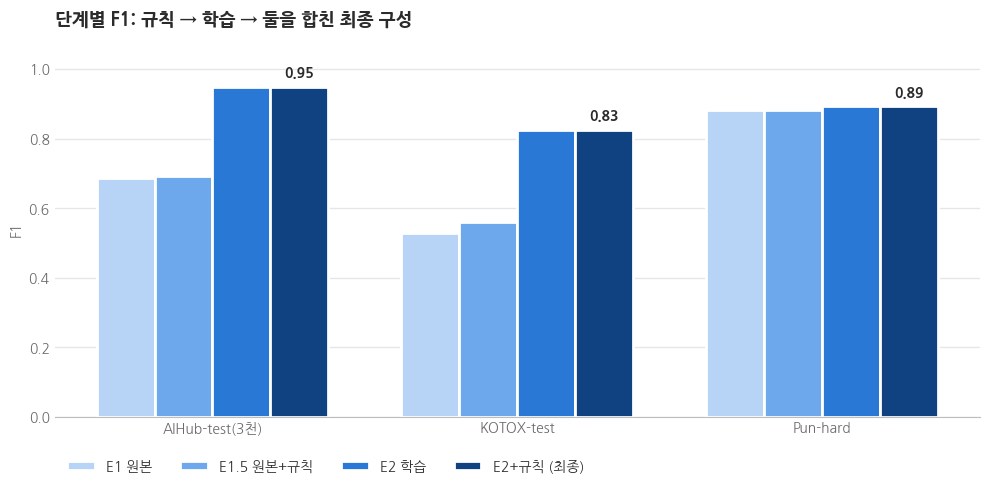

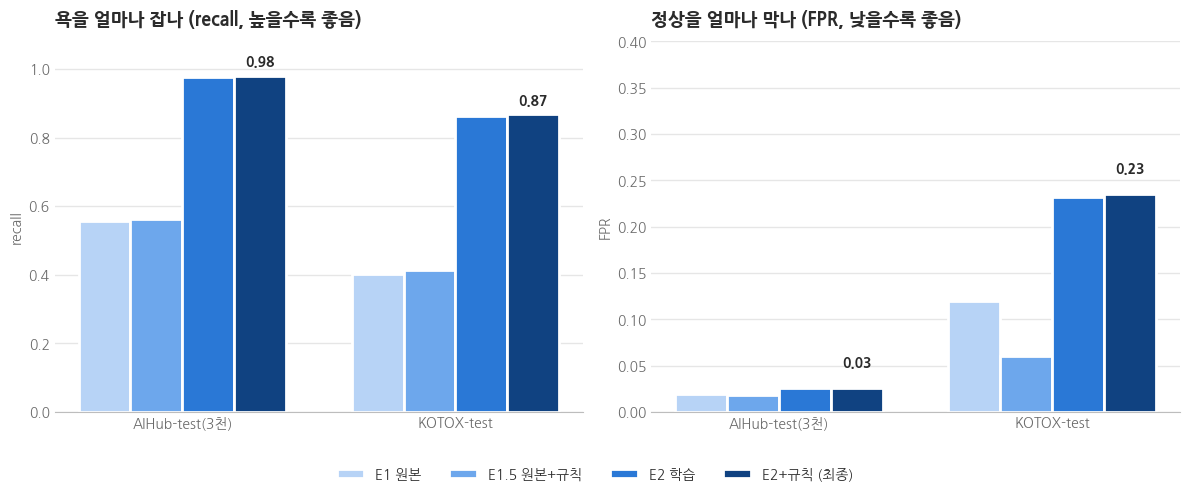

구성,E1 원본,E1.5 원본+규칙,E2 학습,E2+규칙 (최종)
세트,,,,
AIHub-test(3천),0.687,0.694,0.948,0.950
KOTOX-test,0.529,0.562,0.824,0.826
Pun-hard,0.883,0.883,0.893,0.893
프로브,0.852,0.964,0.912,1.000
함정 세트,0.000,0.000,0.000,0.000


저장: /content/drive/MyDrive/Nyung/data/processed/chart_f1.png | /content/drive/MyDrive/Nyung/data/processed/chart_recall_fpr.png


In [60]:
# ===== 최종 비교 그래프 =====
import matplotlib.pyplot as plt
import numpy as np

ft = pd.read_csv(f"{PROC}/final_comparison.csv")        # 앞 셀에서 저장한 최종 비교표
CFG = ["E1 원본", "E1.5 원본+규칙", "E2 학습", "E2+규칙 (최종)"]
# 단계가 진행될수록 진해지는 한 가지 색(파랑) 계열, 최종 구성이 가장 진함
COLORS = ["#b7d3f6", "#6da7ec", "#2a78d6", "#104281"]
INK, MUTED, GRID = "#2b2b2b", "#6b6b6b", "#e6e6e6"

def style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=12)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_ylim(0, 1.08)
    ax.yaxis.grid(True, color=GRID, linewidth=1); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#bdbdbd")
    ax.tick_params(colors=MUTED, length=0)

def grouped_bars(ax, sets, metric, label_last=True):
    x, w = np.arange(len(sets)), 0.19
    for i, cfg in enumerate(CFG):
        vals = [ft.query("세트 == @s and 구성 == @cfg")[metric].iloc[0] for s in sets]
        bars = ax.bar(x + (i - 1.5) * w, vals, w, color=COLORS[i], label=cfg,
                      edgecolor="white", linewidth=2)               # 막대 사이 2px 간격
        if label_last and i == len(CFG) - 1:                         # 최종 구성만 값 표시
            for b, v in zip(bars, vals):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}",
                        ha="center", va="bottom", fontsize=10, color=INK, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(sets, color=INK)

# --- 그래프 1: 세트별 F1 (메인) ---
main_sets = ["AIHub-test(3천)", "KOTOX-test", "Pun-hard"]
fig, ax = plt.subplots(figsize=(10, 5))
grouped_bars(ax, main_sets, "f1")
style(ax, "단계별 F1: 규칙 → 학습 → 둘을 합친 최종 구성", "F1")
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.08), labelcolor=INK)
plt.tight_layout(); plt.savefig(f"{PROC}/chart_f1.png", dpi=200, bbox_inches="tight"); plt.show()

# --- 그래프 2: 탐지(recall)와 오탐(FPR)의 맞바꿈 (두 칸으로 나눠 축 하나씩) ---
pair_sets = ["AIHub-test(3천)", "KOTOX-test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
grouped_bars(axes[0], pair_sets, "recall")
style(axes[0], "욕을 얼마나 잡나 (recall, 높을수록 좋음)", "recall")
grouped_bars(axes[1], pair_sets, "fpr")
style(axes[1], "정상을 얼마나 막나 (FPR, 낮을수록 좋음)", "FPR")
axes[1].set_ylim(0, 0.4)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.04), labelcolor=INK)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(f"{PROC}/chart_recall_fpr.png", dpi=200, bbox_inches="tight"); plt.show()

# --- 표로도 확인 (그래프의 숫자 그대로) ---
display(ft.pivot_table(index="세트", columns="구성", values="f1")[CFG].round(3))
print("저장:", f"{PROC}/chart_f1.png", "|", f"{PROC}/chart_recall_fpr.png")

## 12. E3: 학습 데이터 추가-출력층 증가: 욕설, 혐오, 위협
E2는 본체를 고정해서 정상 예문을 넣어도 거의 바뀌지 않았음 (E2-v2). E3는 본체는 그대로 두고 **출력층을 욕설·위협·혐오 3개**로 나눠 각각 따로 학습한다.

- 학습: E2 학습 데이터 + 정상 예문(`hard_neg.csv`) + 신체 위협 대조쌍(`threat_train`, `normal_train`) + AI Hub 강도 기반 혐오 라벨 + 혐오 정상 예문
- 평가: E1·E1.5·E2와 같은 시험지 + 신체 위협 평가쌍(`threat_eval`, `normal_eval`) + 우리 기준 벤치마크 300

| 단계 | 내용 |
|---|---|
| 위협 대조쌍 | 신체 위협 학습/평가 문장 저장 |
| 사전-1, 라벨-1, 라벨-2 | AI Hub 카테고리 분할, 라벨 점검 시트, 원본 kor_unsmile 기준선 |
| 라벨시트 기준선 · 오류분석 | 원본 모델의 혐오/욕설 오탐·미탐 |
| E3-0 ~ E3-3 | 혐오 정상 예문 → 데이터 구성·표현 추출 → 헤드 3개 학습 → benchmark_300 평가 |
| 벤치-1 ~ 벤치-4 | 우리 기준 벤치마크 300 만들기 → 합치기 → 평가 → 확신 높음만 재평가 |

In [61]:
# E3 추가 데이터: 신체 위협 대조쌍 (위협 = 1, 같은 신체 단어를 쓴 정상 = 0)
# 평가용 묶음(뼈, 손목, 발가락)은 학습용 위협 문장에 나오지 않는 단어 → 단어를 외웠는지, 뜻을 배웠는지 구분
threat_train = [
    "갈비뼈 순서 바꿔줄까?", "갈비뼈 하나씩 정리해줄까?",
    "코 위치 조금 옮겨줄까?",
    "무릎이 몇 도까지 접히는지 궁금하네.", "무릎 접히는 방향 바꿔줄까?",
    "목 좀 뻣뻣하게 만들어줄까?",
    "코뼈 단단한지 시험해볼까?",
    "너 신체 구조 한번 다시 정리해줄까?", "신체 구조를 처음부터 다시 설계해줄까?",
    "몸의 좌우 균형을 내가 맞춰줄까?",
]
normal_train = [
    "해부학 노트에 갈비뼈 순서 틀리게 적었던데 바꿔줄까?", "갈비뼈 그림 번호 순서가 거꾸로야",
    "생선 갈비뼈 하나씩 발라줄까?", "시험 범위에서 갈비뼈 부분 하나씩 정리해줄까?",
    "눈사람 코 위치 조금 옮겨줄까?", "캐릭터 그림에서 코 위치만 조금 옮기면 될 것 같아",
    "재활 치료 때 무릎이 몇 도까지 접히는지 쟀어", "수술 후에 무릎이 몇 도까지 접히는지가 중요하대",
    "인형 무릎 접히는 방향 알려줄까? 반대로 끼웠어", "로봇 다리 무릎 접히는 방향을 반대로 조립했네",
    "스쿼트할 때 무릎 방향 좀 잡아줄까?", "무릎 방향이 발끝이랑 같아야 안 다친대",
    "자고 일어났더니 목이 뻣뻣해", "목이 뻣뻣하면 스트레칭 좀 같이 해줄까?",
    "복싱할 땐 코뼈 다치지 않게 보호대 써", "코뼈 골절은 붓기 빠지고 다시 봐야 한대",
    "의사가 엑스레이로 코뼈 위치 확인해 줬어", "넘어졌는데 코뼈 괜찮은지 병원 가 보자",
    "생물 시험 범위 신체 구조 한번 다시 정리해줄까?", "인체 구조 그리는 법 알려줄까?",
    "로봇 신체 구조를 처음부터 다시 설계해줄까?", "게임 캐릭터 신체 구조를 처음부터 다시 설계했어",
    "필라테스 선생님이 몸의 좌우 균형을 맞춰 줬어", "자세 교정 운동으로 몸의 좌우 균형 맞춰 보자",
    "교정하면 이빨 배열 다시 맞춰준대", "치과에서 이빨 배열 사진 찍어 줬어",
    "운동 전에 발목 좀 돌려서 풀어", "발목 삐었으면 냉찜질부터 해",
]
threat_eval = [
    "뼈 배열이 마음에 안 드는데 내가 고쳐줄까?", "뼈마디 하나씩 점검해줄까?",
    "손목 각도 좀 바꿔줄까?",
    "발가락 하나 없어지고 싶어?",
]
normal_eval = [
    "공룡 화석 뼈 배열이 이상한데 다시 맞춰볼까?", "모형 해골 뼈 배열 틀린 거 내가 고쳐줄까?",
    "도수치료사가 뼈마디 하나씩 점검해 줬어", "비 오는 날엔 뼈마디가 쑤셔",
    "마우스 쓸 때 손목 각도 좀 바꿔줄까? 받침대 있어", "테니스 칠 때 손목 각도 좀 봐줄까?",
    "신발이 작아서 발가락 하나가 계속 아파", "축구하다가 발가락 하나 멍들었어",
]

def pairs(pos, neg):
    return pd.DataFrame({"text": pos + neg, "label": [1] * len(pos) + [0] * len(neg)})

threat_tr_df, threat_ev_df = pairs(threat_train, normal_train), pairs(threat_eval, normal_eval)
assert not set(threat_tr_df["text"]) & set(threat_ev_df["text"]), "학습과 평가에 같은 문장"
threat_tr_df.to_csv(f"{OUT}/threat_train.csv", index=False)
threat_ev_df.to_csv(f"{OUT}/threat_eval.csv", index=False)
print("학습:", threat_tr_df["label"].value_counts().to_dict(), "| 평가:", threat_ev_df["label"].value_counts().to_dict())

학습: {0: 28, 1: 10} | 평가: {0: 8, 1: 4}


In [62]:
# [사전-1] AI Hub 카테고리 데이터: 성혐오·종교·인종/지역 강도 열 붙이기 + train/valid/test 나누기 (준비 포함)
# 필요: 위쪽 공통 셀 (BASE, OUT, load_kotox, clean)
import hashlib

s2 = pd.read_csv(f"{BASE}/2. 유해 카테고리 분류/stage2_data.csv")        # (뒤의 시트 변수 s2 와 이름이 겹쳐 다시 불러옴)
CATS = list(s2.columns[1:])                       # 모욕, 욕설, ..., 정상
CAT3 = ["성혐오", "종교", "인종/지역"]             # 사전에 넣을 카테고리

cat = s2.assign(text=s2["문장"].map(clean)).drop(columns="문장")
cat = cat[cat["text"].str.len() >= 2]
cat = cat.groupby("text", as_index=False)[CATS].max()        # 같은 문장이 여러 번이면 강도는 큰 값

# 기존 분할(aihub_train/valid/test.csv)을 그대로 따름
# 기존 분할에 없던 문장(욕설 없이 다른 혐오만 있는 문장 등)은 문장 해시로 8:1:1 → 다시 돌려도 같은 결과
split_of = {}
for sp in ("train", "valid", "test"):
    for t in pd.read_csv(f"{OUT}/aihub_{sp}.csv")["text"]:
        split_of[t] = sp

def assign(t):
    if t in split_of:
        return split_of[t]
    h = int(hashlib.md5(t.encode()).hexdigest(), 16) % 10
    return "train" if h < 8 else ("valid" if h == 8 else "test")

cat["src"] = np.where(cat["text"].isin(split_of), "기존 분할", "새로 분할")
cat["split"] = cat["text"].map(assign)

# 새로 나눈 문장 중 다른 평가 세트(KOTOX test, UnSmile valid, 프로브)와 겹치는 문장은 제외
ev = set()
for name in ("valid_eval", "probe"):
    if name in globals():
        ev |= set(globals()[name]["text"])
ev |= set(load_kotox("total", "test")["text"])
drop = (cat["src"] == "새로 분할") & cat["text"].isin(ev)
cat = cat[~drop]
print(f"평가 세트와 겹쳐 제외: {drop.sum()}개 (valid_eval·프로브는 이 세션에 없으면 확인 못 함)")

# 분할별 문장 수
others = [c for c in CATS if c != "정상"]
is_clean = (cat["정상"] == 1) & (cat[others].sum(axis=1) == 0)
summary = pd.DataFrame({
    "전체": cat.groupby("split").size(),
    "정상만": cat[is_clean].groupby("split").size(),
    **{c: cat[cat[c] >= 1].groupby("split").size() for c in CAT3},
}).loc[["train", "valid", "test"]]
display(summary)

cat[["text", "split", "src"] + CATS].to_csv(f"{OUT}/aihub_cat_split.csv", index=False)
print("저장:", f"{OUT}/aihub_cat_split.csv")

평가 세트와 겹쳐 제외: 1개 (valid_eval·프로브는 이 세션에 없으면 확인 못 함)


,전체,정상만,성혐오,종교,인종/지역
split,,,,,
train,160103,79999,3731,954,14626
valid,19965,10000,449,111,1881
test,19895,10000,464,112,1860


저장: /content/drive/MyDrive/Nyung/data/processed/aihub_cat_split.csv


In [63]:
# [라벨-1] 기준선·라벨 점검용 시트 3개 만들기 (라벨러에게는 원래 카테고리를 숨김)
# 필요: [사전-1] 실행 상태 (cat, CATS, OUT, SHEET_DIR), load_kotox, normalize
# 주의: AI Hub 문장이 들어 있으므로 파일은 드라이브에만 두고 깃허브에 올리지 않음
SEED_ = SEED if "SEED" in globals() else 42

CORE  = ["성혐오", "종교", "인종/지역"]                  # 시트 ①: 각 60개 (강도 1·2·3을 20개씩)
OTHER = ["장애", "연령", "직업", "정치성향"]              # 시트 ②: 각 30개 (강도 1·2·3을 10개씩)

missing = [c for c in CORE + OTHER if c not in cat.columns]
assert not missing, f"카테고리 열 이름 확인 필요: {missing} / 실제 열: {list(cat.columns)}"

test = cat[cat["split"] == "test"].copy()               # 학습에 안 쓴 구간에서만 뽑음
used = set()

def pick(c, per_level):
    """카테고리 c에서 강도 1·2·3별로 per_level개씩. 모자라면 다른 강도에서 채움"""
    rows = []
    for lv in (1, 2, 3):
        pool = test[(test[c] == lv) & ~test["text"].isin(used)]
        take = pool.sample(min(per_level, len(pool)), random_state=SEED_)
        used.update(take["text"])
        rows.append(take.assign(카테고리=c, 강도=lv))
    got = pd.concat(rows)
    need = per_level * 3 - len(got)
    if need > 0:
        pool = test[(test[c] >= 1) & ~test["text"].isin(used)]
        more = pool.sample(min(need, len(pool)), random_state=SEED_)
        used.update(more["text"])
        got = pd.concat([got, more.assign(카테고리=c, 강도=more[c])])
    return got

def other_cats(r):
    return ", ".join(f"{k}{int(r[k])}" for k in CATS if k not in (r["카테고리"], "정상") and r[k] >= 1)

s1 = pd.concat([pick(c, 10) for c in CORE])
s2 = pd.concat([pick(c, 5) for c in OTHER])
for s in (s1, s2):
    s["기타카테고리"] = s.apply(other_cats, axis=1)

# 시트 ③: KOTOX test에서 label == 1 (혐오 또는 욕설) 100개 → 팀이 혐오인지 욕설인지 구분
kx_test = kx_total["test"] if "kx_total" in globals() else load_kotox("total", "test")
s3 = kx_test[kx_test["label"] == 1].sample(50, random_state=SEED_).copy()
s3["카테고리"], s3["강도"], s3["기타카테고리"] = "KOTOX label=1", "", ""
s3["보조_정규화"] = s3["text"].map(lambda t: normalize(str(t), "max"))     # 비틀어 쓴 문장 읽기 돕기

# 아이디 + 열쇠 파일 (원래 카테고리·강도는 여기에만 둠)
keys = []
for name, s in (("s1", s1), ("s2", s2), ("s3", s3)):
    s = s.reset_index(drop=True)
    s["id"] = [f"{name}_{i + 1:03d}" for i in range(len(s))]
    s["sheet"] = name
    keys.append(s[["id", "sheet", "text", "카테고리", "강도", "기타카테고리"]])
    # 라벨링용 파일: 순서를 섞고, 원래 라벨은 숨기고, 채울 열만 둠
    lab = s[["id", "text"] + (["보조_정규화"] if name == "s3" else [])].sample(frac=1, random_state=SEED_)
    for col in ("our_hate", "our_curse", "our_type", "memo"):
        lab[col] = ""
    lab.to_csv(f"{SHEET_DIR}/label_{name}.csv", index=False, encoding="utf-8-sig")
key = pd.concat(keys)
key.to_csv(f"{SHEET_DIR}/label_key.csv", index=False, encoding="utf-8-sig")

print("시트 ① 카테고리×강도:"); display(pd.crosstab(s1["카테고리"], s1["강도"]))
print("시트 ② 카테고리×강도:"); display(pd.crosstab(s2["카테고리"], s2["강도"]))
print(f"시트 ③: {len(s3)}개 | 저장 위치: {SHEET_DIR}")
print("""
[라벨링 안내] 열을 채워 주세요 (원래 카테고리는 보지 않고 문장만 보고 판단)
  our_hate : 성별·종교·인종/국적 같은 집단을 겨냥한 비하·차별·배척이면 1, 아니면 0
  our_curse: 욕설이 들어 있으면 1, 아니면 0 (한 문장에 둘 다 가능)
  our_type : our_hate가 1일 때 성 / 종교 / 인종 / 지역 / 기타 중 하나
  memo     : 애매하면 이유를 적기
""")
print("※ label_key.csv의 문장들은 시험지로만 쓰고 학습 데이터에서 제외할 것")

시트 ① 카테고리×강도:


강도,1,2,3
카테고리,,,
성혐오,10,10,10
인종/지역,10,10,10
종교,10,11,9


시트 ② 카테고리×강도:


강도,1,2,3
카테고리,,,
연령,5,5,5
장애,7,5,3
정치성향,5,5,5
직업,5,5,5


시트 ③: 50개 | 저장 위치: /content/drive/MyDrive/Nyung/data/processed/label_sheets

[라벨링 안내] 열을 채워 주세요 (원래 카테고리는 보지 않고 문장만 보고 판단)
  our_hate : 성별·종교·인종/국적 같은 집단을 겨냥한 비하·차별·배척이면 1, 아니면 0
  our_curse: 욕설이 들어 있으면 1, 아니면 0 (한 문장에 둘 다 가능)
  our_type : our_hate가 1일 때 성 / 종교 / 인종 / 지역 / 기타 중 하나
  memo     : 애매하면 이유를 적기

※ label_key.csv의 문장들은 시험지로만 쓰고 학습 데이터에서 제외할 것


In [64]:
# [라벨-2] 라벨 병합 → (a) AI Hub 라벨 점검 (b) 기준선(원본 kor_unsmile)
import os
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

FINAL = f"{SHEET_DIR}/labels_final.csv"      # 팀이 검수한 라벨(id,our_hate,our_curse,our_type) - 있으면 이걸 우선 사용

# ── 0. 라벨 준비 ───────────────────────────────────────────
def _ids(sheet, s): return [f"{sheet}_{int(n):03d}" for n in s.split()]

_HATE = [  # (시트, 유형, ids)
    ("s1", "성",   "005 010 011 013 014 016 017 018 020 021 022 023 024 025 027 028"),
    ("s1", "기타", "019 026 029"),
    ("s1", "지역", "009 061 072 076"),
    ("s1", "종교", "034 037 038 041 042 043 044 047 049 051 056 057 058 074 087"),
    ("s1", "인종", "040 052 062 063 066 069 070 071 073 075 078 079 081 083 084 086 088 089 090"),
    ("s2", "인종", "001 044 052 057"), ("s2", "성", "022"), ("s2", "지역", "032"),
    ("s3", "성",   "024 037"),
]
_CURSE = (_ids("s1", "014 024 058 071 080 083 086") + _ids("s2", "004 008 010 015 019 024 037 042 048 053")
          + _ids("s3", "006 009 018 019 020 042 046 049 050"))
_LOW = (_ids("s1", "002 003 008 018 021 022 033 035 039 048 050 054 066 070 072 076 080")
        + _ids("s2", "004 008 010 015 022 024 031 032 037 038 040 053")
        + _ids("s3", "001 002 003 004 005 007 009 011 013 014 015 016 017 020 021 023 025 026 027 028 031 033 035 036 038 041 043 044 045 050"))
HATE = {i: t for sh, t, s in _HATE for i in _ids(sh, s)}

key = pd.read_csv(f"{SHEET_DIR}/label_key.csv", encoding="utf-8-sig")
if os.path.exists(FINAL):
    lab = pd.read_csv(FINAL, encoding="utf-8-sig")
    print("라벨: labels_final.csv 사용 (팀 검수본)")
else:
    lab = pd.DataFrame({"id": key["id"]})
    lab["our_hate"]  = lab["id"].map(lambda i: int(i in HATE))
    lab["our_curse"] = lab["id"].map(lambda i: int(i in set(_CURSE)))
    lab["our_type"]  = lab["id"].map(HATE)
    lab["low_conf"]  = lab["id"].map(lambda i: int(i in set(_LOW)))
    lab.to_csv(f"{SHEET_DIR}/labels_claude_firstpass.csv", index=False, encoding="utf-8-sig")
    print("라벨: Claude 초벌 사용 → labels_claude_firstpass.csv 저장 (검수 후 labels_final.csv 로 저장하면 자동 반영)")
if "low_conf" not in lab.columns: lab["low_conf"] = 0

df = key.merge(lab[["id", "our_hate", "our_curse", "our_type", "low_conf"]], on="id", how="left")
assert df["our_hate"].notna().all(), f"라벨 없는 id: {df.loc[df['our_hate'].isna(), 'id'].tolist()[:10]}"
df["sh"] = df["id"].str[:2]
df["our_type"] = df["our_type"].fillna("-")
df["gold_core"] = ((df["our_hate"] == 1) & df["our_type"].isin(["성", "종교", "인종"])).astype(int)  # 성/종교/인종만
print("시트별 개수:", df["sh"].value_counts().sort_index().to_dict())

# ── (a) AI Hub 라벨 점검 (s1, s2) ───────────────────────────
MAP = {"성혐오": {"성"}, "종교": {"종교"}, "인종/지역": {"인종", "지역"}}
ah = df[df["sh"].isin(["s1", "s2"])].copy()
ah["match"] = [int(h == 1 and t in MAP.get(c, set())) for h, t, c in zip(ah["our_hate"], ah["our_type"], ah["카테고리"])]

print("\n[a-1] AI Hub 카테고리별: 우리 기준 혐오/욕설 비율 (핵심 3종은 '일치'=혐오이면서 유형도 같음)")
g = ah.groupby("카테고리").agg(n=("id", "size"), 혐오=("our_hate", "mean"), 욕설=("our_curse", "mean"), 일치=("match", "mean"))
print(g.round(2).to_string())

core = ah[ah["카테고리"].isin(MAP)]
print("\n[a-2] 핵심 3종 강도별 일치율")
print(core.pivot_table(index="카테고리", columns="강도", values="match", aggfunc="mean").round(2).to_string())
print("\n[a-3] 카테고리 × 우리 유형 (행: AI Hub 카테고리)")
print(pd.crosstab(ah["카테고리"], ah["our_type"]).to_string())
print(f"\n핵심 3종 전체 일치율 {core['match'].mean():.2f}  (확신 낮음 제외 {core[core['low_conf']==0]['match'].mean():.2f})")

dis = core[core["match"] == 0][["id", "카테고리", "강도", "our_hate", "our_type", "low_conf", "text"]]
dis.to_csv(f"{SHEET_DIR}/audit_disagree.csv", index=False, encoding="utf-8-sig")
print(f"불일치 {len(dis)}건 → audit_disagree.csv (팀 검수용, Drive 안에만 둘 것)")

# ── (b) 기준선: 원본 kor_unsmile ────────────────────────────
LAB10 = ["여성/가족", "남성", "성소수자", "인종/국적", "연령", "지역", "종교", "기타 혐오", "악플/욕설", "clean"]
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
MID = "smilegate-ai/kor_unsmile"
u_tok = AutoTokenizer.from_pretrained(MID)
u_mdl = AutoModelForSequenceClassification.from_pretrained(MID).eval()
u_dev = "cuda" if torch.cuda.is_available() else "cpu"; u_mdl.to(u_dev)
u_names = [u_mdl.config.id2label[i] for i in range(u_mdl.config.num_labels)]
print("모델 라벨:", u_names)
if not any(n.startswith("LABEL_") for n in u_names): LAB10 = u_names

@torch.no_grad()
def unsmile_predict(texts, bs=64):
    texts = [str(t) for t in texts]; out = []
    for i in range(0, len(texts), bs):
        enc = u_tok(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(u_dev)
        out.append(torch.sigmoid(u_mdl(**enc).logits).cpu().numpy())
    return np.vstack(out)

IX = {n: i for i, n in enumerate(LAB10)}
H_CORE = ["여성/가족", "남성", "인종/국적", "종교"]
TYPE2HEAD = {"성": ["여성/가족", "남성"], "종교": ["종교"], "인종": ["인종/국적"], "지역": ["지역"], "기타": ["성소수자", "기타 혐오"]}
def hscore(P, names): return P[:, [IX[n] for n in names]].max(1)

def report(tag, y, s, thr=0.5):
    y = np.asarray(y); p = (np.asarray(s) >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    auc = roc_auc_score(y, s) if 0 < y.sum() < len(y) else float("nan")
    print(f"  {tag:<14} n={len(y):<4} 정답+={int(y.sum()):<3} 예측+={int(p.sum()):<3} P={pr:.2f} R={rc:.2f} F1={f1:.2f} AUC={auc:.2f}")

variants = {"원문": df["text"]}
try:
    from normalize import normalize
    variants["정규화"] = df["text"].map(lambda t: normalize(str(t), "max"))
except Exception as e:
    print("normalize 불러오기 실패 → 정규화 비교 생략:", e)

preds = {}
for vn, texts in variants.items():
    P = unsmile_predict(texts.tolist()); preds[vn] = P
    print(f"\n[b-1] 라벨시트 기준선 · 입력={vn}  (혐오=성/종교/인종 헤드 max≥0.5, 욕설=악플/욕설≥0.5)")
    sc_h, sc_c = hscore(P, H_CORE), P[:, IX["악플/욕설"]]
    print(" 혐오(우리 gold = 성/종교/인종 혐오)")
    for sh in ["s1", "s2", "s3"]:
        m = (df["sh"] == sh).values; report(sh, df.loc[m, "gold_core"], sc_h[m])
    report("전체", df["gold_core"], sc_h)
    print(" 욕설(우리 gold = our_curse)")
    for sh in ["s1", "s2", "s3"]:
        m = (df["sh"] == sh).values; report(sh, df.loc[m, "our_curse"], sc_c[m])
    report("전체", df["our_curse"], sc_c)
    print(" 유형별 재현율 (우리가 해당 유형 혐오로 본 문장 중 모델 해당 헤드 ≥0.5)")
    for t, heads in TYPE2HEAD.items():
        m = ((df["our_hate"] == 1) & (df["our_type"] == t)).values
        if m.sum(): print(f"  {t:<4} n={int(m.sum()):<3} 재현율={(hscore(P, heads)[m] >= 0.5).mean():.2f}")

P = preds["원문"]
out = df[["id", "sh", "카테고리", "강도", "our_hate", "our_curse", "our_type", "low_conf"]].copy()
for n in LAB10: out["p_" + n] = P[:, IX[n]].round(3)
out.to_csv(f"{SHEET_DIR}/baseline_preds.csv", index=False, encoding="utf-8-sig")
print(f"\n예측 저장: {SHEET_DIR}/baseline_preds.csv")

# ── (b-2) UnSmile valid 기준선 (참고: 원본이 UnSmile train 으로 학습돼 낙관적) ──
try:
    from datasets import load_dataset
    va = load_dataset("smilegate-ai/kor_unsmile")["valid"].to_pandas()
    print("UnSmile 열:", list(va.columns))
    tcol = next(c for c in va.columns if va[c].dtype == object and va[c].astype(str).str.len().mean() > 5)  # 문장 열 자동 탐색
    print("문장 열:", tcol)
    Pv = unsmile_predict(va[tcol].tolist())
    if all(n in va.columns for n in H_CORE + ["악플/욕설"]):
        gh = va[H_CORE].max(axis=1).values
        gc = va["악플/욕설"].values
    else:   # 라벨이 labels 리스트 하나로 들어 있는 경우 (순서 = LAB10)
        L = np.vstack(va["labels"].values)
        gh = L[:, [IX[n] for n in H_CORE]].max(1); gc = L[:, IX["악플/욕설"]]
    print("\n[b-2] UnSmile valid (낙관적 상한, 우리 라벨시트와 직접 비교 불가)")
    report("혐오(성/종교/인종)", gh, hscore(Pv, H_CORE))
    report("욕설", gc, Pv[:, IX["악플/욕설"]])
except Exception as e:
    print("\nUnSmile valid 로드/평가 실패:", repr(e)[:300])


라벨: Claude 초벌 사용 → labels_claude_firstpass.csv 저장 (검수 후 labels_final.csv 로 저장하면 자동 반영)
시트별 개수: {'s1': 90, 's2': 60, 's3': 50}

[a-1] AI Hub 카테고리별: 우리 기준 혐오/욕설 비율 (핵심 3종은 '일치'=혐오이면서 유형도 같음)
        n    혐오    욕설    일치
카테고리                       
성혐오    30  0.67  0.07  0.53
연령     15  0.07  0.13  0.00
인종/지역  30  0.73  0.13  0.67
장애     15  0.07  0.27  0.00
정치성향   15  0.13  0.13  0.00
종교     30  0.50  0.03  0.43
직업     15  0.13  0.13  0.00

[a-2] 핵심 3종 강도별 일치율
강도     1.0   2.0   3.0
카테고리                  
성혐오    0.2  0.70  0.70
인종/지역  0.6  0.70  0.70
종교     0.3  0.55  0.44

[a-3] 카테고리 × 우리 유형 (행: AI Hub 카테고리)
our_type   -  기타   성  인종  종교  지역
카테고리                            
성혐오       10   3  16   0   0   1
연령        14   0   1   0   0   0
인종/지역      8   0   0  17   2   3
장애        14   0   0   1   0   0
정치성향      13   0   0   2   0   0
종교        15   0   0   2  13   0
직업        13   0   0   1   0   1

핵심 3종 전체 일치율 0.54  (확신 낮음 제외 0.58)
불일치 41건 → audit_disagree.csv (팀 검수용, Drive 안에만 둘 것)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

모델 라벨: ['여성/가족', '남성', '성소수자', '인종/국적', '연령', '지역', '종교', '기타 혐오', '악플/욕설', 'clean']

[b-1] 라벨시트 기준선 · 입력=원문  (혐오=성/종교/인종 헤드 max≥0.5, 욕설=악플/욕설≥0.5)
 혐오(우리 gold = 성/종교/인종 혐오)
  s1             n=90   정답+=50  예측+=69  P=0.67 R=0.92 F1=0.77 AUC=0.76
  s2             n=60   정답+=5   예측+=5   P=0.60 R=0.60 F1=0.60 AUC=0.97
  s3             n=50   정답+=2   예측+=3   P=0.67 R=1.00 F1=0.80 AUC=1.00
  전체             n=200  정답+=57  예측+=77  P=0.66 R=0.89 F1=0.76 AUC=0.92
 욕설(우리 gold = our_curse)
  s1             n=90   정답+=7   예측+=8   P=0.00 R=0.00 F1=0.00 AUC=0.39
  s2             n=60   정답+=10  예측+=30  P=0.20 R=0.60 F1=0.30 AUC=0.61
  s3             n=50   정답+=9   예측+=22  P=0.23 R=0.56 F1=0.32 AUC=0.79
  전체             n=200  정답+=26  예측+=60  P=0.18 R=0.42 F1=0.26 AUC=0.64
 유형별 재현율 (우리가 해당 유형 혐오로 본 문장 중 모델 해당 헤드 ≥0.5)
  성    n=19  재현율=0.89
  종교   n=15  재현율=0.87
  인종   n=23  재현율=0.74
  지역   n=5   재현율=0.60
  기타   n=3   재현율=0.67

[b-1] 라벨시트 기준선 · 입력=정규화  (혐오=성/종교/인종 헤드 max≥0.5, 욕설=악플/욕설≥0.5)
 혐오(우리 gold =

dataset_infos.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.16MB            

...

data/valid-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  290kB            

data/valid-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15005 [00:00<?, ? examples/s]

Generating valid split:   0%|          | 0/3737 [00:00<?, ? examples/s]

UnSmile 열: ['문장', '여성/가족', '남성', '성소수자', '인종/국적', '연령', '지역', '종교', '기타 혐오', '악플/욕설', 'clean', '개인지칭', 'labels']
문장 열: 문장

[b-2] UnSmile valid (낙관적 상한, 우리 라벨시트와 직접 비교 불가)
  혐오(성/종교/인종)    n=3737 정답+=1342 예측+=1258 P=0.91 R=0.85 F1=0.88 AUC=0.97
  욕설             n=3737 정답+=786 예측+=612 P=0.76 R=0.59 F1=0.67 AUC=0.91


### 라벨시트 기준선 (원본 kor_unsmile, 입력=원문, 임계값 0.5)

| 구분 | 시트 | n | 정답+ | 예측+ | P | R | F1 | AUC |
|---|---|---|---|---|---|---|---|---|
| 혐오 | s1 | 90 | 50 | 69 | 0.67 | 0.92 | 0.77 | 0.76 |
| 혐오 | s2 | 60 | 5 | 5 | 0.60 | 0.60 | 0.60 | 0.97 |
| 혐오 | s3 | 50 | 2 | 3 | 0.67 | 1.00 | 0.80 | 1.00 |
| 혐오 | **전체** | 200 | 57 | 77 | 0.66 | 0.89 | 0.76 | 0.92 |
| 욕설 | s1 | 90 | 7 | 8 | 0.00 | 0.00 | 0.00 | 0.39 |
| 욕설 | s2 | 60 | 10 | 30 | 0.20 | 0.60 | 0.30 | 0.61 |
| 욕설 | s3 | 50 | 9 | 22 | 0.23 | 0.56 | 0.32 | 0.79 |
| 욕설 | **전체** | 200 | 26 | 60 | 0.18 | 0.42 | 0.26 | 0.64 |

### 유형별 재현율 (우리가 해당 유형 혐오로 본 문장 중 모델이 해당 헤드 ≥0.5로 예측한 비율)

| 유형 | n | 원문 | 정규화 |
|---|---|---|---|
| 성 | 19 | 0.89 | 0.84 |
| 종교 | 15 | 0.87 | 0.87 |
| 인종 | 23 | 0.74 | 0.74 |
| 지역 | 5 | 0.60 | 0.60 |
| 기타(성소수자 등) | 3 | 0.67 | 0.67 |

### UnSmile valid vs 우리 라벨시트

| 구분 | 지표 | UnSmile valid (n=3,737) | 라벨시트 전체 (n=200) |
|---|---|---|---|
| 혐오 | P / R / F1 | 0.91 / 0.85 / 0.88 | 0.66 / 0.89 / 0.76 |
| 혐오 | AUC | 0.97 | 0.92 |
| 욕설 | P / R / F1 | 0.76 / 0.59 / 0.67 | 0.18 / 0.42 / 0.26 |
| 욕설 | AUC | 0.91 | 0.64 |

In [65]:
# [오류분석] 원본 kor_unsmile 의 혐오/욕설 오탐·미탐 목록 (라벨시트 200문장 기준)
import pandas as pd, numpy as np

SHEET_DIR = f"{OUT}/label_sheets"
b = pd.read_csv(f"{SHEET_DIR}/baseline_preds.csv", encoding="utf-8-sig")
key = pd.read_csv(f"{SHEET_DIR}/label_key.csv", encoding="utf-8-sig")[["id", "text"]]
b = b.merge(key, on="id", how="left")

H_CORE = ["여성/가족", "남성", "인종/국적", "종교"]
b["gold_core"] = ((b["our_hate"] == 1) & b["our_type"].isin(["성", "종교", "인종"])).astype(int)
b["h_score"] = b[["p_" + n for n in H_CORE]].max(axis=1)
b["h_head"] = b[["p_" + n for n in H_CORE]].idxmax(axis=1).str.replace("p_", "", regex=False)
b["pred_core"] = (b["h_score"] >= 0.5).astype(int)
b["c_score"] = b["p_악플/욕설"]; b["pred_curse"] = (b["c_score"] >= 0.5).astype(int)

def show(d, title, n=40):
    print(f"\n=== {title}: {len(d)}건 ===")
    for r in d.head(n).itertuples():
        print(f"[{r.id}] 모델={r.h_head}({r.h_score:.2f}) | 우리={r.our_type} | AI Hub={r.카테고리}/{r.강도} | {str(r.text)[:90]}")

cols = ["id", "sh", "카테고리", "강도", "our_hate", "our_type", "low_conf", "h_head", "h_score", "text"]
fp = b[(b["pred_core"] == 1) & (b["gold_core"] == 0)].sort_values("h_score", ascending=False)
fn = b[(b["pred_core"] == 0) & (b["gold_core"] == 1)].sort_values("h_score")

# 오탐 중 '우리도 혐오지만 범위 밖(지역/기타)'인 것은 따로 분리
fp_scope = fp[fp["our_hate"] == 1]; fp_true = fp[fp["our_hate"] == 0]
print(f"혐오 오탐 {len(fp)}건 = 진짜 오탐(우리 혐오 아님) {len(fp_true)} + 범위 밖 혐오(지역/기타) {len(fp_scope)}")
print(f"혐오 미탐 {len(fn)}건")

print("\n[오탐] AI Hub 카테고리별:", fp_true["카테고리"].value_counts().to_dict())
print("[오탐] 모델이 반응한 헤드:", fp_true["h_head"].value_counts().to_dict())
print("[오탐] 시트별:", fp_true["sh"].value_counts().to_dict())
print("[미탐] 우리 유형별:", fn["our_type"].value_counts().to_dict())

show(fp_true, "혐오 오탐 (우리=혐오 아님, 모델=혐오)")
show(fp_scope, "범위 밖 혐오 (우리=지역/기타 혐오, 모델=성/종교/인종 헤드 반응)")
show(fn, "혐오 미탐 (우리=혐오, 모델=정상)")

pd.concat([fp.assign(error="오탐")[cols + ["error"]], fn.assign(error="미탐")[cols + ["error"]]]) \
  .to_csv(f"{SHEET_DIR}/error_hate.csv", index=False, encoding="utf-8-sig")

cfp = b[(b["pred_curse"] == 1) & (b["our_curse"] == 0)]; cfn = b[(b["pred_curse"] == 0) & (b["our_curse"] == 1)]
pd.concat([cfp.assign(error="오탐"), cfn.assign(error="미탐")])[["id", "sh", "카테고리", "our_curse", "c_score", "text", "error"]] \
  .to_csv(f"{SHEET_DIR}/error_curse.csv", index=False, encoding="utf-8-sig")
print(f"\n욕설 오탐 {len(cfp)}건 / 미탐 {len(cfn)}건 → error_curse.csv")
print(f"저장: {SHEET_DIR}/error_hate.csv, error_curse.csv  (AI Hub 원문 포함 → Drive 밖으로 내보내지 말 것)")

혐오 오탐 26건 = 진짜 오탐(우리 혐오 아님) 25 + 범위 밖 혐오(지역/기타) 1
혐오 미탐 6건

[오탐] AI Hub 카테고리별: {'종교': 10, '성혐오': 8, '인종/지역': 4, '장애': 2, 'KOTOX label=1': 1}
[오탐] 모델이 반응한 헤드: {'여성/가족': 10, '인종/국적': 9, '종교': 6}
[오탐] 시트별: {'s1': 22, 's2': 2, 's3': 1}
[미탐] 우리 유형별: {'인종': 3, '성': 2, '종교': 1}

=== 혐오 오탐 (우리=혐오 아님, 모델=혐오): 25건 ===
[s1_036] 모델=종교(0.92) | 우리=- | AI Hub=종교/1.0 | 조국과 사제단 모두 사회악이다 종교를 방패 삼는 인간들 너희가 도대체 사랑교회와 뭔 차이가 있나 생각만 바대일뿐 하는짓 똑같고 아니 어찌보면 더한 집단이다 정치종
[s1_048] 모델=종교(0.92) | 우리=- | AI Hub=종교/2.0 | 저런 사악한 교회목사 부인 집사에게 속아넘어간 피해자도 문제가 있음 왜 교회를 가냐고 차라리 돌을 믿어라
[s1_068] 모델=인종/국적(0.92) | 우리=- | AI Hub=인종/지역/1.0 | 토착왜구 . 국힘. OO 의원. . . .통곡할듯. . 취소라니
[s1_032] 모델=종교(0.91) | 우리=- | AI Hub=종교/1.0 | 공무원들은 예배드리는 곳에는 득달같이 달려가 몇 명 예배 드리나 감시하러 다니고, 불특정 다수가 모인곳은 나몰라라!! 교회만 있는 코로나!! 정신나간 목사들아 이
[s1_080] 모델=인종/국적(0.91) | 우리=- | AI Hub=인종/지역/2.0 | 친일 극우 OOO 들 속터지게 됐다 . 절대로 상종 해서는 안될 극우 보수 들 . 얍쌉한 일본 극우 쉑키 들 . 히로시마에 핵의 쓴맛을 한번더 봐야 정신 차릴 거
[s1_035] 모델=종교(0.90) | 우리=- | AI Hub=종교/1.0 | 늑대과인데 땅파는게 당연한거야!!!무식한목사야!!!똑같 묶고 

In [66]:
# [E3-0] 혐오 헤드용 정상 예문 저장 (집단 단어가 나오지만 비하가 없는 문장 = 0)
hate_hn = [
    # ① 성평등·젠더 논쟁·정책 (비하어 없음)
    "여성가족부 예산 배분이 적절한지 토론하는 글을 읽었다", "성평등 정책이 실제로 효과가 있는지 통계를 찾아봤어",
    "페미니즘 관련 강연을 들었는데 생각할 거리가 많았다", "군 복무 보상 제도를 어떻게 바꿔야 할지 의견이 갈리는 것 같아",
    "양성평등 교육 자료를 학교에서 받아 왔어", "여성단체가 발표한 성명서 내용을 읽어 봤다",
    "남녀 임금 격차를 줄이는 방법에 대한 토론회가 열린대", "요즘 젠더 갈등 기사가 많아서 뉴스 보기가 조금 피곤하다",
    "성별 간 의견 차이를 줄이려면 대화가 필요하다고 생각해", "여성 할당제에 대해 찬반 의견이 팽팽하다",
    "육아휴직을 남성도 쓰기 쉬운 분위기가 됐으면 좋겠어", "여성 인권 단체가 지원금을 어떻게 쓰는지 공개했다",
    "이번 선거에서 젠더 이슈가 쟁점이 될 거라는 분석이 나왔다", "페미니즘이라는 단어의 뜻을 두고 사람마다 해석이 다른 것 같아",
    "여성 징병제 논의가 다시 나오고 있다", "성차별 신고 제도가 잘 작동하는지 점검해야 한다는 기사였다",
    "직장 내 성희롱 예방 교육을 받았다", "남성 육아 참여율이 올랐다는 통계가 나왔어",
    "여성 경비원과 아파트 주민 사이의 갈등을 다룬 다큐를 봤다", "성평등 지수가 작년보다 올랐다고 한다",
    "다양한 성별의 의견을 듣는 공청회가 열렸다", "학교에서 성교육을 어떻게 해야 하는지 고민이 많다",
    "젠더 문제를 다룬 토론 프로그램을 끝까지 시청했다", "여성 정치인 비율을 높이는 방안이 논의됐다",
    "여자 배구 대표팀이 오늘 경기에서 이겼다",
    # ② 종교 단체의 행동 비판·중립 언급
    "일부 교회가 방역 수칙을 지키지 않아 논란이 됐다", "대면 예배를 강행하는 것에 대해 의견이 분분하다",
    "목사의 설교가 정치적이라는 지적이 나왔다", "사제단이 발표한 시국 성명을 두고 논쟁이 일었다",
    "종교 단체의 정치 개입을 어디까지 허용할지 논의가 필요하다", "교회 헌금 사용 내역을 공개하라는 요구가 나왔다",
    "방역 당국이 종교 시설 점검을 강화한다고 밝혔다", "예배 인원 제한이 형평성에 맞는지 따져 보는 기사였다",
    "신도 수가 줄어서 교회가 문을 닫는 곳이 늘었대", "목사님이 직접 방역 봉사를 나서서 칭찬받았다",
    "성당에서 미사 시간이 바뀐다는 공지가 왔다", "절에서 템플스테이를 신청했어",
    "종교 시설 집단감염 사례를 분석한 보고서가 나왔다", "교회 방역 책임을 둘러싼 법원 판결이 나왔다",
    "종교인 과세 제도가 제대로 시행되는지 살펴봤다", "사이비 종교 피해 예방 교육을 받았다",
    "교인들이 주변 이웃을 돕는 봉사 활동을 했다", "이웃 교회에서 바자회를 열어서 구경하러 갔다",
    "종교 단체의 집회 허가 기준에 대한 논쟁이 있었다", "스님이 강연에서 마음 챙김에 대해 설명해 주셨다",
    "목사의 횡령 의혹을 수사 중이라는 보도가 나왔다", "성당 신부님이 지역 행사에서 축사를 했다",
    "종교 단체가 정부 정책에 반대 입장을 냈다", "예배 중 마스크 착용 여부를 점검했다",
    "교회 건축 비용 논란이 계속되고 있다",
    # ③ 정치 비판·시사 (멸칭 없음)
    "이번 정부의 외교 정책이 지나치게 일본에 유리하다는 비판이 나온다", "야당이 정부의 대북 정책을 강하게 비판했다",
    "여당과 야당이 예산안을 두고 충돌했다", "국회에서 법안 처리가 또 미뤄졌다",
    "정치인의 말 바꾸기에 실망했다는 시민이 많다", "대선 후보들의 공약을 비교해 봤다",
    "정권 교체 여론이 높다는 조사 결과가 나왔다", "의원 재산 신고 내역을 확인해 봤다",
    "정당 지지율이 일주일 사이 크게 바뀌었다", "정치 성향이 달라도 대화는 할 수 있어야 한다고 생각해",
    "청와대 대변인이 브리핑에서 입장을 밝혔다", "정부의 백신 수급 계획에 대한 비판 기사를 읽었다",
    "지역 의원이 주민 간담회를 열었다", "탄핵 이후 정치 지형이 어떻게 바뀌었는지 분석한 글이다",
    "선거 때마다 나오는 네거티브 공방이 피곤하다", "국정감사에서 장관이 답변을 피해서 논란이 됐다",
    "세금 인상에 반대하는 서명 운동이 시작됐다", "정당 대표가 사과 입장문을 발표했다",
    "보수와 진보가 복지 정책에서 입장이 갈린다", "시민단체가 정부 정책 감시 활동을 이어 가고 있다",
    "총리 후보자 청문회가 내일 열린다", "친일 청산 문제를 다룬 역사 강의를 들었다",
    "한일 관계 개선을 위한 협상이 진행 중이라고 한다", "이번 국방 예산 증액에 대해 찬반이 있다",
    "북한 관련 뉴스가 연일 나오고 있다",
    # ④ 국가·외국인·이주민 중립 언급
    "어제 한일전 배구 경기 정말 손에 땀을 쥐게 했다", "중국 출장 가서 협력 업체와 회의하고 왔어",
    "난민 수용 정책에 대한 찬반 토론을 했다", "이슬람 문화권의 라마단 기간에 대해 공부했어",
    "일본 여행 가서 온천에 다녀왔는데 정말 좋았다", "터키 아이스크림 파는 가게를 처음 봤어",
    "외국인 노동자 비자 제도가 바뀐다는 뉴스를 봤다", "유학생 친구가 한국 음식이 맛있다고 했다",
    "월드컵 예선에서 우리나라가 중국과 만난다", "일본 드라마를 보면서 일본어를 공부하고 있어",
    "아프가니스탄 상황을 다룬 다큐멘터리를 봤다", "파키스탄에서 온 친구가 고향 음식을 만들어 줬다",
    "베트남 쌀국수 맛집을 찾았다", "올림픽에서 각국 선수단이 입장하는 장면이 멋있었다",
    "중국어 학원에 등록했다", "이주민 지원 센터에서 한국어 수업을 한다",
    "미국과 한국의 금리 차이가 환율에 영향을 준다고 한다", "난민 지원 단체가 모금 활동을 시작했다",
    "국제 스포츠 경기에서 한국이 일본을 이겼다", "외국인 관광객이 다시 늘고 있다는 기사가 나왔다",
    "무슬림 친구와 같이 할랄 식당에 갔다", "아랍 지역 날씨는 한낮에 정말 덥다고 한다",
    "한중 정상회담 일정이 발표됐다", "다문화 가정 아이들을 위한 도서관이 문을 열었다",
    "인도 음식 카레를 직접 만들어 봤어",
]
assert len(hate_hn) == len(set(hate_hn))
pd.DataFrame({"text": hate_hn, "label": 0}).to_csv(f"{OUT}/hard_neg_hate_train.csv", index=False)
print("저장:", len(hate_hn), "문장 → hard_neg_hate_train.csv")

저장: 100 문장 → hard_neg_hate_train.csv


In [67]:
# [E3-1] 데이터 구성 → 문장 표현 추출 → 기준선(헤드 늘리기 전 현재 모델 점수)
import os, re, time, joblib
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support
from normalize import normalize

SEED, NORM, MAX_LEN = 42, "max", 128
USE_KOTOX = True      # 욕설 헤드에만 사용 (혐오·위협 라벨이 없어 두 헤드에서는 제외)
HATE_MIN  = 2         # 혐오 양성 = 성혐오/종교/인종·지역 강도 ≥ 2 (강도 1은 모호 → 제외)
CORE = ["성혐오", "종교", "인종/지역"]
nkey = lambda s: re.sub(r"[\s.,!?~]", "", str(s))

# ── 모델 (E2와 같은 UnSmile 본체, 고정) ──
if not globals().get("E3_FAKE"):
    import torch
    if "u_mdl" not in globals():
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        u_tok = AutoTokenizer.from_pretrained("smilegate-ai/kor_unsmile")
        u_mdl = AutoModelForSequenceClassification.from_pretrained("smilegate-ai/kor_unsmile").eval()
        u_dev = "cuda" if torch.cuda.is_available() else "cpu"; u_mdl.to(u_dev)
    LAB10 = [u_mdl.config.id2label[i] for i in range(u_mdl.config.num_labels)]
    if any(n.startswith("LABEL_") for n in LAB10):
        LAB10 = ["여성/가족", "남성", "성소수자", "인종/국적", "연령", "지역", "종교", "기타 혐오", "악플/욕설", "clean"]
    ORIG_W = u_mdl.classifier.weight.detach().cpu().numpy(); ORIG_B = u_mdl.classifier.bias.detach().cpu().numpy()

    @torch.inference_mode()
    def e3_embed(texts, bs=128):
        texts = [normalize(str(t), NORM) for t in texts]
        order = np.argsort([len(t) for t in texts]); out = np.zeros((len(texts), ORIG_W.shape[1]), dtype=np.float32)
        for i in range(0, len(texts), bs):
            idx = order[i:i + bs]
            enc = u_tok([texts[j] for j in idx], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(u_dev)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(u_dev == "cuda")):
                h = u_mdl.bert(**enc).pooler_output
            out[idx] = h.float().cpu().numpy()
        return out
IX = {n: i for i, n in enumerate(LAB10)}
orig = lambda X: 1 / (1 + np.exp(-np.clip(X @ ORIG_W.T + ORIG_B, -30, 30)))          # 원본 UnSmile 출력층 점수 (10개)
H_CORE = ["여성/가족", "남성", "인종/국적", "종교"]

# ── 데이터 ──
rd = lambda name: (pd.read_csv(f"{OUT}/{name}.csv")[["text", "label"]].dropna().astype({"text": str})
                   if os.path.exists(f"{OUT}/{name}.csv") else pd.DataFrame(columns=["text", "label"]))
def mk(d, src, split, w=1.0, curse=np.nan, threat=np.nan, hate=np.nan):
    """헤드별 라벨 (NaN = 이 소스에선 모름 → 그 헤드 학습에서 제외)"""
    o = pd.DataFrame({"text": d["text"].astype(str).values}); o["src"], o["split"], o["w"] = src, split, w
    for k, v in (("curse", curse), ("threat", threat), ("hate", hate)):
        o[k] = d["label"].astype(float).values if isinstance(v, str) and v == "label" else v
    return o

cat = pd.read_csv(f"{OUT}/aihub_cat_split.csv")
CATS = [c for c in cat.columns if c not in ("text", "split", "src")]
TH = next(c for c in CATS if "위협" in c)
OTHER = [c for c in CATS if c not in CORE + [TH]]
for c in CATS: cat[c] = pd.to_numeric(cat[c], errors="coerce").fillna(0)
cat["core_max"], cat["thr"] = cat[CORE].max(axis=1), cat[TH]
cm = pd.concat([rd(f"aihub_{s}") for s in ("train", "valid", "test")]).drop_duplicates("text").set_index("text")["label"]
cat["curse"] = cat["text"].map(cm)                                     # 욕설 라벨: 기존 AI Hub 욕설 라벨을 문장으로 매칭
print(f"욕설 라벨 매칭률 {cat['curse'].notna().mean():.0%} (낮으면 aihub_*.csv 와 문장 정제 방식이 다른 것)")

CAP = {"train": (5000, 6000, 12000), "valid": (800, 1000, 2000), "test": (1500, 2000, 3000)}   # (카테고리당, 범위 밖, 정상)
def aihub(split):
    d = cat[cat["split"] == split]; c, o, n = CAP[split]; parts = []
    for k in CORE:
        x = d[d[k] >= 1]; parts.append(x.sample(min(c, len(x)), random_state=SEED))
    parts.append(d[d["thr"] > 0])
    x = d[(d["core_max"] == 0) & (d["thr"] == 0) & (d[OTHER].max(axis=1) > 0)]; parts.append(x.sample(min(o, len(x)), random_state=SEED))
    x = d[d[CATS].max(axis=1) == 0]; parts.append(x.sample(min(n, len(x)), random_state=SEED))
    a = pd.concat(parts).drop_duplicates("text")
    hate = np.where(a["core_max"] >= HATE_MIN, 1.0, np.where(a["core_max"] >= 1, np.nan, 0.0))   # 강도 1은 모호 → NaN
    return mk(pd.DataFrame({"text": a["text"], "label": 0}), "AIHub", split, curse=a["curse"].values,
              threat=(a["thr"] > 0).astype(float).values, hate=hate)

def hand0(name, split, w): d = rd(name); return mk(d, "정상예문", split, w, curse=0.0, threat=0.0, hate=0.0)
tr = [aihub("train"), hand0("hard_neg", "train", 3), hand0("hard_neg_more_train", "train", 3),
      hand0("hard_neg_more2_train", "train", 3), hand0("hard_neg_hate_train", "train", 5)]
d = rd("threat_train"); tr.append(mk(d, "신체위협", "train", 3, curse=0.0, threat="label", hate=0.0))
d = rd("pun_train");    tr.append(mk(d, "말장난", "train", 3, curse="label"))
if USE_KOTOX: tr.append(mk(rd("kotox_train"), "KOTOX", "train", curse="label"))
va = [aihub("valid")] + ([mk(rd("kotox_valid"), "KOTOX", "valid", curse="label")] if USE_KOTOX else [])
te = [aihub("test"), hand0("hard_neg_more_eval", "test", 1), hand0("hard_neg_more2_eval", "test", 1)]
d = rd("threat_eval"); te.append(mk(d, "신체위협", "test", curse=0.0, threat="label", hate=0.0))
d = rd("pun_eval_hard"); te.append(mk(d, "말장난", "test", curse="label"))
if USE_KOTOX and "load_kotox" in globals():
    try: te.append(mk(load_kotox("total", "test")[["text", "label"]], "KOTOX", "test", curse="label"))
    except Exception as e: print("KOTOX test 생략:", repr(e)[:80])

sheet = pd.read_csv(f"{SHEET_DIR}/label_key.csv", encoding="utf-8-sig")
E3te = pd.concat(te, ignore_index=True).drop_duplicates("text").reset_index(drop=True)
block = {nkey(t) for t in E3te["text"]} | {nkey(t) for t in sheet["text"]}      # 평가 문장·라벨시트는 학습에서 제외
def fin(parts):
    d = pd.concat(parts, ignore_index=True).drop_duplicates("text")
    n0 = len(d); d = d[~d["text"].map(nkey).isin(block)].reset_index(drop=True)
    print(f"  (평가·라벨시트와 겹쳐 {n0 - len(d)}개 제외)"); return d
E3tr, E3va = fin(tr), fin(va)
for nm, d in (("train", E3tr), ("valid", E3va), ("test", E3te)):
    print(f"{nm}: {len(d)}문장 | 라벨 있는 수 " + " ".join(f"{k}={int(d[k].notna().sum())}(양성 {int((d[k]==1).sum())})" for k in ("curse", "threat", "hate")))

# ── 문장 표현 추출 (캐시: 다시 실행해도 새 문장만 계산) ──
cache = f"{OUT}/e3_emb_{NORM}.joblib"
allt = list(pd.unique(pd.concat([E3tr["text"], E3va["text"], E3te["text"], sheet["text"].astype(str)])))
store = joblib.load(cache) if os.path.exists(cache) else {"texts": [], "X": np.zeros((0, ORIG_W.shape[1]), np.float32)}
have = {t: i for i, t in enumerate(store["texts"])}
miss = [t for t in allt if t not in have]
if miss:
    t0 = time.time(); Xn = e3_embed(miss)
    store = {"texts": store["texts"] + miss, "X": np.vstack([store["X"], Xn])}; joblib.dump(store, cache)
    have = {t: i for i, t in enumerate(store["texts"])}
    print(f"문장 표현 {len(miss)}개 추출 {time.time() - t0:.0f}초 → 캐시 저장")
lk = lambda texts: store["X"][[have[t] for t in texts]]
E3Xtr, E3Xva, E3Xte, E3Xsh = lk(E3tr["text"]), lk(E3va["text"]), lk(E3te["text"]), lk(sheet["text"].astype(str))

# ── 기준선: 헤드를 늘리기 전 현재 모델 (평가 세트 = test) ──
def met(y, s, thr):
    y = np.asarray(y).astype(int); p = (np.asarray(s) >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    return dict(n=len(y), 양성=int(y.sum()), P=pr, R=rc, F1=f1, AUC=roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan)
O = orig(E3Xte)
E3base = {"혐오": O[:, [IX[n] for n in H_CORE]].max(1), "욕설": O[:, IX["악플/욕설"]], "위협": O[:, IX["악플/욕설"]]}   # 위협은 헤드가 없어 '악플/욕설' 점수로 대신 측정
e2p = [p for p in (f"{OUT}/e2_head_v2.joblib", f"{OUT}/e2_head.joblib") if os.path.exists(p)]
E2 = joblib.load(e2p[0]) if e2p else None
rows = []
for nm, col in (("혐오", "hate"), ("위협", "threat"), ("욕설", "curse")):
    m = E3te[col].notna().values
    rows.append(dict(헤드=nm, 기준="원본 UnSmile" + (" (악플/욕설로 대체)" if nm == "위협" else ""), **met(E3te.loc[m, col], E3base[nm][m], 0.5)))
    if E2 is not None and nm != "혐오":
        s2 = E2["head"].predict_proba(E3Xte)[:, 1]; E3base[nm + "_E2"] = s2
        rows.append(dict(헤드=nm, 기준="E2 현재 모델 (욕 점수)", **met(E3te.loc[m, col], s2[m], E2["thr"])))
print("\n[기준선] test 세트, 헤드를 늘리기 전 현재 모델")
print(pd.DataFrame(rows).round(3).to_string(index=False))

욕설 라벨 매칭률 65% (낮으면 aihub_*.csv 와 문장 정제 방식이 다른 것)
  (평가·라벨시트와 겹쳐 2개 제외)
  (평가·라벨시트와 겹쳐 0개 제외)
train: 38386문장 | 라벨 있는 수 curse=20039(양성 10549) threat=27278(양성 5334) hate=21995(양성 4759)
valid: 5140문장 | 라벨 있는 수 curse=2697(양성 1387) threat=3766(양성 625) hate=3013(양성 653)
test: 6829문장 | 라벨 있는 수 curse=3771(양성 1775) threat=5382(양성 612) hate=4286(양성 954)

[기준선] test 세트, 헤드를 늘리기 전 현재 모델
헤드                     기준    n   양성     P     R    F1   AUC
혐오             원본 UnSmile 4286  954 0.817 0.748 0.781 0.939
위협 원본 UnSmile (악플/욕설로 대체) 5382  612 0.240 0.536 0.332 0.722
위협        E2 현재 모델 (욕 점수) 5382  612 0.150 0.894 0.257 0.645
욕설             원본 UnSmile 3771 1775 0.912 0.369 0.525 0.707
욕설        E2 현재 모델 (욕 점수) 3771 1775 0.909 0.910 0.910 0.975


In [68]:
# [E3-2] 출력층 3개(욕설·위협·혐오) 학습 → 임계값(valid) → 평가(test·라벨시트) → 저장
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve
SHOW_DROPPED = 8      # 정제로 빠진 AI Hub 혐오 양성 문장을 몇 개 출력할지 (0이면 출력 안 함)

# ── 혐오 라벨 정제 (AI Hub만): 표현 벡터로 교차검증 → 뚜렷하게 어긋난 라벨만 제거 ──
hm = E3tr["hate"].notna().values
Xh, yh = E3Xtr[hm], E3tr.loc[hm, "hate"].astype(int).values
oof = cross_val_predict(LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced"), Xh, yh,
                        cv=StratifiedKFold(4, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
isah = E3tr.loc[hm, "src"].eq("AIHub").values
bad = isah & (((yh == 1) & (oof < 0.2)) | ((yh == 0) & (oof > 0.9)))
print(f"혐오 라벨 정제: 양성 {int((bad & (yh == 1)).sum())}개 · 음성 {int((bad & (yh == 0)).sum())}개 제거 (전체 {len(yh)}개 중)")
for t in E3tr.loc[hm].loc[bad & (yh == 1), "text"].head(SHOW_DROPPED): print("   제거된 양성:", t[:70])
hate_keep = np.ones(len(E3tr), bool); hate_keep[np.where(hm)[0][bad]] = False

# ── 헤드 학습 ──
HEADS = {"욕설": "curse", "위협": "threat", "혐오": "hate"}
E3heads = {}
for nm, col in HEADS.items():
    m = E3tr[col].notna().values & (hate_keep if col == "hate" else True)
    X, y, w = E3Xtr[m], E3tr.loc[m, col].astype(int).values, E3tr.loc[m, "w"].values
    mv = E3va[col].notna().values; Xv, yv = E3Xva[mv], E3va.loc[mv, col].astype(int).values
    best = None
    for C in (0.1, 1.0, 10.0):
        clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(X, y, sample_weight=w)
        pr, rc, th = precision_recall_curve(yv, clf.predict_proba(Xv)[:, 1])
        f1s = 2 * pr * rc / (pr + rc + 1e-9); k = int(np.argmax(f1s[:-1]))
        if best is None or f1s[k] > best[0]: best = (f1s[k], C, clf, float(th[k]))
    E3heads[nm] = (best[2], best[3])
    print(f"{nm}: 학습 {len(y)}개(양성 {int(y.sum())}) | C={best[1]} | valid F1 {best[0]:.3f} 임계값 {best[3]:.3f}")
joblib.dump({"heads": E3heads, "norm": NORM, "version": "E3"}, f"{OUT}/e3_heads.joblib")
print("저장:", f"{OUT}/e3_heads.joblib")

def e3_scores(X): return {nm: h.predict_proba(X)[:, 1] for nm, (h, _) in E3heads.items()}

# ── test 평가 (기준선과 같은 세트) ──
S = e3_scores(E3Xte); rows = []
for nm, col in HEADS.items():
    m = E3te[col].notna().values
    rows.append(dict(헤드=nm, 모델="E3 새 헤드", **met(E3te.loc[m, col], S[nm][m], E3heads[nm][1])))
print("\n[E3 평가] test 세트 (위 [기준선] 표와 비교)"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\n소스별 (AI Hub / 신체위협 / 말장난 / KOTOX / 정상예문)")
for nm, col in HEADS.items():
    for src, g in E3te.groupby("src"):
        m = g[col].notna().values
        if m.sum() and 0 < g.loc[m, col].sum() < m.sum():
            r = met(g.loc[m, col], S[nm][g.index[m]], E3heads[nm][1]); print(f"  {nm:<3} {src:<6} n={r['n']:<5} P={r['P']:.2f} R={r['R']:.2f} F1={r['F1']:.2f}")

# ── 우리 라벨시트 200문장 (혐오·욕설, 성/종교/인종만 혐오로 봄) ──
lp = next((p for p in (f"{SHEET_DIR}/labels_final.csv", f"{SHEET_DIR}/labels_claude_firstpass.csv") if os.path.exists(p)), None)
if lp:
    L = sheet[["id", "text"]].merge(pd.read_csv(lp, encoding="utf-8-sig")[["id", "our_hate", "our_curse", "our_type"]], on="id")
    L["gold_h"] = ((L["our_hate"] == 1) & L["our_type"].isin(["성", "종교", "인종"])).astype(int)
    So, Sn = orig(E3Xsh), e3_scores(E3Xsh); o_h = So[:, [IX[n] for n in H_CORE]].max(1)
    print(f"\n[라벨시트 200] 라벨: {os.path.basename(lp)}")
    for nm, y, s_old, s_new in (("혐오", L["gold_h"], o_h, Sn["혐오"]), ("욕설", L["our_curse"], So[:, IX["악플/욕설"]], Sn["욕설"])):
        print(f"  {nm}  원본 {({k: round(v, 2) for k, v in met(y, s_old, 0.5).items() if k in ('P', 'R', 'F1', 'AUC')})}")
        print(f"  {nm}  E3   {({k: round(v, 2) for k, v in met(y, s_new, E3heads[nm][1]).items() if k in ('P', 'R', 'F1', 'AUC')})}")
    neg = (L["gold_h"] == 0).values
    print(f"  혐오 아님 {int(neg.sum())}개 중 오탐: 원본 {int((o_h[neg] >= .5).sum())}개 → E3 {int((Sn['혐오'][neg] >= E3heads['혐오'][1]).sum())}개")

혐오 라벨 정제: 양성 272개 · 음성 414개 제거 (전체 21995개 중)
   제거된 양성: ㅋㅋ아니 OO이 쟤들보다 형량이 두배나 높은 이유가 뭐냐ㅋㅋ 한명도 안죽여서? 한명도 자살 안해서? 얼탱이 없네 그놈의 봊인지
   제거된 양성: 이번 OO 성추행사건은 비서가 그전에행동이 구설수다~~ 비서가 어깨에 손을 얹고 하는행동이 이해가 안된다비서측 변호사 또한 그
   제거된 양성: OO이랑 사진 자랑스럽니?가문의 챙피란다.특히 뚱땡이 OO이 천박스런 여자.OO이랑 딱어울리는 뚱땡이.OO아 너 인기 이제 끝
   제거된 양성: ??잡 제시. OO 천박한 싸구려엉덩이 깐 OO 사진 유포 하니까초딩들 몸사진유포 성매매 OO. 천박한싸구려 엉덩이 깐 OO 
   제거된 양성: 대깨들신낫구나 지들때는 숨죽이고 있더니 민젓당도 사퇴해라
   제거된 양성: 민노총 헛짓 할 때는 토종벌꿀 처 먹은 듯 주둥이 딱 붙이고 있더만 OO 공연한다고 하니 대깨문 문빠종자들이 왠 똥밟은 소리 
   제거된 양성: 저네는 여자만 보면 눈이 뻘개가 다니면서 지 딸은 마누라는 명예를 지켜라 무식이 아니라 미개한것
   제거된 양성: 질의 힘이라고 하면 매장 당할텐데 남근의 힘은 괜찮나보네ㅋ OO 혹시 게이야? ㄷㄷ
욕설: 학습 20039개(양성 10549) | C=10.0 | valid F1 0.908 임계값 0.371
위협: 학습 27278개(양성 5334) | C=10.0 | valid F1 0.631 임계값 0.745
혐오: 학습 21309개(양성 4487) | C=1.0 | valid F1 0.838 임계값 0.800
저장: /content/drive/MyDrive/Nyung/data/processed/e3_heads.joblib

[E3 평가] test 세트 (위 [기준선] 표와 비교)
헤드      모델    n   양성     P     R    F1   AUC
욕설 E3 새 헤드 3771 1775 0.898 0.919 0.909 0.973
위협 E3 새 헤드 5382

In [69]:
# [E3-B] 학습 전 기준선: benchmark_300.csv (is_swear 이진 + category), 헤드 학습 없이 현재 모델로만 측정
# 필요: [E3-1] 실행 상태
T300 = f"{OUT}/benchmark_300.csv"
NORMAL = "일상 대화(정상)"

b3 = pd.read_csv(T300, encoding="utf-8-sig").dropna(subset=["text"]).reset_index(drop=True)
y3 = b3["is_swear"].map(lambda v: str(v).strip().lower() in ("true", "1", "1.0", "t", "yes")).astype(int).values
cat3 = b3["category"].astype(str).values
POS_CATS = [c for c in pd.unique(cat3) if c != NORMAL]
X3 = e3_embed(b3["text"].astype(str)); O3 = orig(X3)

def row300(name, s, thr):
    s = np.asarray(s); p = s >= thr
    r = met(y3, s, thr)
    d = {"모델": name, "P": r["P"], "R": r["R"], "F1": r["F1"], "AUC": r["AUC"], "정상 오탐률": p[cat3 == NORMAL].mean()}
    for c in POS_CATS: d["탐지율·" + c] = p[cat3 == c].mean()
    return d

cands = [("원본 UnSmile: 악플/욕설", O3[:, IX["악플/욕설"]], 0.5),
         ("원본 UnSmile: 정상 아님(1-clean)", 1 - O3[:, IX["clean"]], 0.5)]
if E2 is not None: cands.append(("E2 현재 모델", E2["head"].predict_proba(X3)[:, 1], E2["thr"]))
bench300 = pd.DataFrame([row300(*c) for c in cands])
print(f"[학습 전 기준선] benchmark_300 (n={len(b3)}, 욕={int(y3.sum())}, 정상={int((y3 == 0).sum())})")
print(bench300.round(3).to_string(index=False))

[학습 전 기준선] benchmark_300 (n=300, 욕=200, 정상=100)
                        모델     P     R    F1   AUC  정상 오탐률  탐지율·우회 욕설(영타/자모/숫자)  탐지율·일반 욕설  탐지율·돌려까기/신체협박/외계어
         원본 UnSmile: 악플/욕설 0.978 0.885 0.929 0.979    0.04                0.987       0.96              0.733
원본 UnSmile: 정상 아님(1-clean) 0.978 0.905 0.940 0.981    0.04                0.973       1.00              0.773
                  E2 현재 모델 0.988 0.810 0.890 0.960    0.02                0.880       0.96              0.640


In [70]:
# [E3-3] 학습 후: benchmark_300 평가 (학습 전 기준선과 같은 표) + 속도
# 필요: [E3-1], [E3-B], [E3-2] 실행 상태
S3 = e3_scores(X3)
R3 = {nm: S3[nm] / E3heads[nm][1] for nm in HEADS}                    # 헤드별 '임계값 대비 비율' (1 이상 = 발동)
nc = (1 - O3[:, IX["clean"]]) / 0.5                                    # 원본 UnSmile '정상 아님' 점수 (임계값 0.5 → 1.0)
mx = lambda *a: np.max(a, axis=0)
new = [row300("E3 욕설 헤드", S3["욕설"], E3heads["욕설"][1]),
       row300("E3 욕설+위협", mx(R3["욕설"], R3["위협"]), 1.0),
       row300("E3 욕설+위협+혐오", mx(R3["욕설"], R3["위협"], R3["혐오"]), 1.0),
       row300("결합: 원본(1-clean) OR E3 위협", mx(nc, R3["위협"]), 1.0),
       row300("결합: 원본(1-clean) OR E3 위협 OR 혐오", mx(nc, R3["위협"], R3["혐오"]), 1.0)]
res = pd.concat([bench300, pd.DataFrame(new)], ignore_index=True)
print("[학습 전/후 비교] benchmark_300"); print(res.round(3).to_string(index=False))

print("\n헤드별 발동률 (카테고리별, 혐오는 정답 라벨이 없어 참고용)")
print(pd.DataFrame({nm: pd.Series(S3[nm] >= E3heads[nm][1]).groupby(cat3).mean() for nm in HEADS}).round(2).to_string())

pred = mx(R3["욕설"], R3["위협"], R3["혐오"]) >= 1.0
out3 = b3.assign(**{f"점수_{nm}": np.round(S3[nm], 3) for nm in HEADS}, 예측=pred.astype(int), 정답=y3)
out3.to_csv(f"{SHEET_DIR}/e3_pred_benchmark300.csv", index=False, encoding="utf-8-sig")
print("\n(욕설+위협+혐오 기준) 정상인데 욕으로 잡은 문장:", int(((y3 == 0) & pred).sum()), "개, 놓친 욕:", int(((y3 == 1) & ~pred).sum()), "개 → e3_pred_benchmark300.csv")
for t in out3[(out3["정답"] == 0) & (out3["예측"] == 1)]["text"].head(15): print("  오탐:", t[:60])

import time as _t                                               # 속도: 한 문장 (정규화 + 본체 + 헤드 3개)
s = "테스트 문장입니다"; t0 = _t.time()
for _ in range(20): e3_scores(e3_embed([s]))
print(f"한 문장 처리 약 {(_t.time() - t0) / 20 * 1000:.0f}ms (헤드 3개)")

[학습 전/후 비교] benchmark_300
                            모델     P     R    F1   AUC  정상 오탐률  탐지율·우회 욕설(영타/자모/숫자)  탐지율·일반 욕설  탐지율·돌려까기/신체협박/외계어
             원본 UnSmile: 악플/욕설 0.978 0.885 0.929 0.979    0.04                0.987       0.96              0.733
    원본 UnSmile: 정상 아님(1-clean) 0.978 0.905 0.940 0.981    0.04                0.973       1.00              0.773
                      E2 현재 모델 0.988 0.810 0.890 0.960    0.02                0.880       0.96              0.640
                      E3 욕설 헤드 0.955 0.855 0.902 0.963    0.08                0.867       0.98              0.760
                      E3 욕설+위협 0.957 0.895 0.925 0.965    0.08                0.867       1.00              0.853
                   E3 욕설+위협+혐오 0.957 0.895 0.925 0.965    0.08                0.867       1.00              0.853
      결합: 원본(1-clean) OR E3 위협 0.979 0.940 0.959 0.984    0.04                0.973       1.00              0.867
결합: 원본(1-clean) OR E3 위협 OR 혐오 0.979 0.940 0.959 0.984    0.04

In [71]:
# [벤치-1] 우리 기준 벤치마크 300문장: 미사용 데이터 샘플링 + 블라인드 라벨링 시트
# 필요: [E3-1] 실행 상태 (cat, E3tr, E3va, sheet, nkey, SHEET_DIR)
SEED_B = 7
N_B = {"정상": 50, "범위밖": 50, "혐오": 70, "위협": 50, "욕설": 40}      # AI Hub 260 + 팀 작성 40 = 300
B300 = "/content/drive/MyDrive/Nyung/benchmark_300.csv"
TEAM = f"{SHEET_DIR}/bench_team_written.csv"                            # 팀이 쓴 우회 욕설·신체 협박 (text 열)

# 제외: 학습·valid 문장, 라벨시트 200, 기존 benchmark_300 (평가용 test split 에서만 뽑음)
excl = {nkey(t) for t in E3tr["text"]} | {nkey(t) for t in E3va["text"]} | {nkey(t) for t in sheet["text"]}
if os.path.exists(B300): excl |= {nkey(t) for t in pd.read_csv(B300, encoding="utf-8-sig")["text"].dropna()}
pool = cat[cat["split"] == "test"].copy()
pool["k"] = pool["text"].map(nkey)
pool = pool[~pool["k"].isin(excl)].drop_duplicates("k")
pool = pool[pool["text"].str.len().between(8, 200)]
pool["카테고리"] = np.where(pool[CATS].max(axis=1) == 0, "정상", pool[CATS].idxmax(axis=1))
pool["강도"] = pool[CATS].max(axis=1)

allzero = pool[CATS].max(axis=1) == 0
oth = (pool["core_max"] == 0) & (pool["thr"] == 0) & (pool[OTHER].max(axis=1) > 0)
used, parts = set(), []
def draw(tag, d, n):
    d = d[~d["k"].isin(used)]; s = d.sample(min(n, len(d)), random_state=SEED_B); used.update(s["k"])
    if len(s) < n: print(f"  후보 부족: {tag} {len(s)}/{n}")
    parts.append(pd.DataFrame({"text": s["text"].values, "source": f"AIHub:{tag}", "카테고리": s["카테고리"].values,
                               "강도": s["강도"].values, "AIHub욕설라벨": s["curse"].values}))
for c, n in zip(CORE, (25, 20, 25)): draw(f"혐오-{c}", pool[pool[c] >= 2], n)          # 혐오 70 (성 25 · 종교 20 · 인종/지역 25)
draw("위협", pool[pool["thr"] > 0], N_B["위협"])
draw("욕설", pool[(pool["curse"] == 1) & (pool["core_max"] == 0) & (pool["thr"] == 0)], N_B["욕설"])
draw("범위밖", pool[oth], N_B["범위밖"])                                                   # 정치성향·직업·연령·장애: 집단 단어가 나오는 정상 후보
draw("정상", pool[allzero], N_B["정상"])

if os.path.exists(TEAM):
    tw = pd.read_csv(TEAM, encoding="utf-8-sig")["text"].dropna().astype(str)
    tw = tw[~tw.map(nkey).isin(excl | used)].drop_duplicates()
    parts.append(pd.DataFrame({"text": tw.values, "source": "팀작성", "카테고리": "팀작성", "강도": np.nan, "AIHub욕설라벨": np.nan}))
    print(f"팀 작성 문장 {len(tw)}개 포함")
else:
    print(f"※ 팀 작성 문장 없음 → {TEAM} (text 열, 우회 욕설 20 + 신체 협박 20 권장) 저장 후 다시 실행하면 합쳐집니다")

bk = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=SEED_B).reset_index(drop=True)
bk.insert(0, "id", [f"b_{i + 1:03d}" for i in range(len(bk))])
bk[["id", "text"]].assign(our_curse="", our_threat="", our_hate="", our_type="", memo="") \
  .to_csv(f"{SHEET_DIR}/bench_sheet.csv", index=False, encoding="utf-8-sig")        # 라벨러에게 줄 시트 (카테고리 숨김)
bk.to_csv(f"{SHEET_DIR}/bench_key.csv", index=False, encoding="utf-8-sig")           # 정답 아님: 출처 기록 (라벨 끝나기 전엔 보지 말 것)
print(f"\n벤치마크 {len(bk)}문장 저장 → bench_sheet.csv (라벨러용), bench_key.csv (출처)")
print(bk["source"].value_counts().to_string())
print("""
[라벨링 안내] 열을 채워 주세요 (출처·카테고리는 보지 않고 문장만 보고 판단, 헤드마다 따로 0/1)
  our_curse : 욕설 단어가 있으면 1. 모욕(쓰레기·찐따·바보·미친·또라이 등)은 0.
              존나·ㅈㄴ·졸라: 뒤에 부정적 표현이나 다른 욕이 붙으면 1, '존맛·개꿀' 같은 긍정 강조면 0 (문맥으로 판단)
  our_threat: 신체·생명에 해를 가하겠다는 의사나 선동이면 1 (대상 불문. '때립시다'도 1)
  our_hate  : 성별·종교·인종/국적·지역·성소수자 같은 집단을 겨냥한 비하·차별·배척이면 1. 집단 비판이 아니라 행동·정책 비판이면 0
  our_type  : our_hate 가 1일 때 성 / 종교 / 인종 / 지역 / 성소수자 중 하나
  memo      : 애매하면 이유를 적기""")

※ 팀 작성 문장 없음 → /content/drive/MyDrive/Nyung/data/processed/label_sheets/bench_team_written.csv (text 열, 우회 욕설 20 + 신체 협박 20 권장) 저장 후 다시 실행하면 합쳐집니다

벤치마크 260문장 저장 → bench_sheet.csv (라벨러용), bench_key.csv (출처)
source
AIHub:위협          50
AIHub:범위밖         50
AIHub:정상          50
AIHub:욕설          40
AIHub:혐오-성혐오      25
AIHub:혐오-인종/지역    25
AIHub:혐오-종교       20

[라벨링 안내] 열을 채워 주세요 (출처·카테고리는 보지 않고 문장만 보고 판단, 헤드마다 따로 0/1)
  our_curse : 욕설 단어가 있으면 1. 모욕(쓰레기·찐따·바보·미친·또라이 등)은 0.
              존나·ㅈㄴ·졸라: 뒤에 부정적 표현이나 다른 욕이 붙으면 1, '존맛·개꿀' 같은 긍정 강조면 0 (문맥으로 판단)
  our_threat: 신체·생명에 해를 가하겠다는 의사나 선동이면 1 (대상 불문. '때립시다'도 1)
  our_hate  : 성별·종교·인종/국적·지역·성소수자 같은 집단을 겨냥한 비하·차별·배척이면 1. 집단 비판이 아니라 행동·정책 비판이면 0
  our_type  : our_hate 가 1일 때 성 / 종교 / 인종 / 지역 / 성소수자 중 하나
  memo      : 애매하면 이유를 적기


In [72]:
# [벤치-2] 300문장 합치기: bench_labels_300.csv(정리본) + AI Hub 260 문장(bench_sheet) → bench_final_300.csv
import os, pandas as pd, numpy as np
lp = next(p for p in (f"{OUT}/bench_labels_300.csv", f"{SHEET_DIR}/bench_labels_300.csv") if os.path.exists(p))
L = pd.read_csv(lp, encoding="utf-8-sig", dtype={"our_type": str}).dropna(axis=1, how="all")
for c in ("text", "구분", "유형(팀)", "확신", "memo", "our_type"):
    if c not in L.columns: L[c] = ""
sh = pd.read_csv(f"{SHEET_DIR}/bench_sheet.csv", encoding="utf-8-sig")[["id", "text"]].rename(columns={"text": "text_aihub"})
ky = pd.read_csv(f"{SHEET_DIR}/bench_key.csv", encoding="utf-8-sig")[["id", "source", "카테고리"]]
B = L.merge(sh, on="id", how="left").merge(ky, on="id", how="left")
B["text"] = B["text"].fillna("").where(B["text"].fillna("") != "", B["text_aihub"])          # 팀 작성 문장은 라벨 파일의 text, 나머지는 bench_sheet
B["source"] = B["source"].fillna("팀작성"); B["카테고리"] = B["카테고리"].fillna(B["구분"])
B["grp"] = np.where(B["source"] == "팀작성", "팀작성:" + B["구분"].astype(str), B["source"])
assert len(B) == 300 and B["text"].notna().all() and (B["text"].astype(str).str.len() > 0).all(), "300문장이 아니거나 문장이 비어 있는 id가 있음"
assert B[["our_curse", "our_threat", "our_hate"]].isin([0, 1]).all().all(), "라벨은 0/1만 가능"
B["our_type"] = B["our_type"].fillna("").astype(str)
miss = B[(B["our_hate"] == 1) & (B["our_type"] == "")]
if len(miss): print("※ 혐오 1인데 our_type 이 빈 id:", " ".join(miss["id"]))
B = B[["id", "text", "source", "grp", "카테고리", "our_curse", "our_threat", "our_hate", "our_type", "확신", "memo"]]
B.to_csv(f"{SHEET_DIR}/bench_final_300.csv", index=False, encoding="utf-8-sig")
print(f"라벨 파일: {lp}\n저장: bench_final_300.csv ({len(B)}문장)")
print(f"욕설 {B['our_curse'].sum()} · 위협 {B['our_threat'].sum()} · 혐오 {B['our_hate'].sum()} · 셋 다 0: {int(((B[['our_curse','our_threat','our_hate']].sum(axis=1)) == 0).sum())}")
print(B["grp"].value_counts().to_string())

라벨 파일: /content/drive/MyDrive/Nyung/data/processed/bench_labels_300.csv
저장: bench_final_300.csv (300문장)
욕설 60 · 위협 58 · 혐오 55 · 셋 다 0: 153
grp
AIHub:위협          50
AIHub:정상          50
AIHub:범위밖         50
AIHub:욕설          40
AIHub:혐오-성혐오      25
AIHub:혐오-인종/지역    25
AIHub:혐오-종교       20
팀작성:신체협박          20
팀작성:우회욕설          20


In [73]:
# [벤치-3] 새 벤치마크 300 평가 (우리 기준 라벨, 욕설·위협·혐오 3개 헤드) — 원본 / E2 / E3 / 결합
B = pd.read_csv(f"{SHEET_DIR}/bench_final_300.csv", encoding="utf-8-sig")
XB = e3_embed(B["text"].astype(str)); OB = orig(XB)
SB = e3_scores(XB); RB = {nm: SB[nm] / E3heads[nm][1] for nm in SB}          # 임계값 대비 비율 (1 이상 = 발동)
nc = (1 - OB[:, IX["clean"]]) / 0.5                                          # 원본 '정상 아님' (임계값 0.5 → 1.0)
mx = lambda *a: np.max(a, axis=0)
H_ALL = [n for n in IX if n not in ("악플/욕설", "clean")]
o_hc, o_ha = OB[:, [IX[n] for n in H_CORE]].max(1), OB[:, [IX[n] for n in H_ALL]].max(1)
o_cu = OB[:, IX["악플/욕설"]]
s2 = E2["head"].predict_proba(XB)[:, 1] if E2 is not None else None

yc, yt, yh = (B[c].values.astype(int) for c in ("our_curse", "our_threat", "our_hate"))
core = B["our_type"].fillna("").map(lambda s: any(t in ("성", "종교", "인종") for t in s.split("/"))).values & (yh == 1)   # 원본 모델이 보는 범위(성·종교·인종)
yb = ((yc + yt + yh) > 0).astype(int)                                        # 차단 정답: 셋 중 하나라도 1

rng = np.random.default_rng(0); IDX = rng.integers(0, len(B), (1000, len(B)))
def f1ci(y, p):
    yy, pp = y[IDX], p[IDX]; tp = (yy * pp).sum(1); fp = ((1 - yy) * pp).sum(1); fn = (yy * (1 - pp)).sum(1)
    f = 2 * tp / (2 * tp + fp + fn + 1e-9); return np.percentile(f, 2.5), np.percentile(f, 97.5)
def rowb(name, s, thr, y):
    s = np.asarray(s); p = (s >= thr).astype(int); r = met(y, s, thr); lo, hi = f1ci(np.asarray(y).astype(int), p)
    return {"모델": name, "양성": r["양성"], "P": r["P"], "R": r["R"], "F1": r["F1"], "F1 95%CI": f"{lo:.2f}~{hi:.2f}", "AUC": r["AUC"]}

print(f"[헤드별] 새 벤치마크 n={len(B)} (라벨: bench_labels_300.csv, Claude 초벌 · 팀 검수 전)")
tabs = {"욕설": [("원본 악플/욕설", o_cu, .5), ("원본 정상 아님(1-clean)", 1 - OB[:, IX['clean']], .5)]
                + ([("E2", s2, E2["thr"])] if s2 is not None else []) + [("E3 욕설 헤드", SB["욕설"], E3heads["욕설"][1])],
        "위협": [("원본 악플/욕설 (헤드 없어 대체)", o_cu, .5), ("E3 위협 헤드", SB["위협"], E3heads["위협"][1])],
        "혐오(성·종교·인종만 정답)": [("원본 혐오 4개 max", o_hc, .5), ("E3 혐오 헤드", SB["혐오"], E3heads["혐오"][1])],
        "혐오(전체 정답)": [("원본 혐오 8개 max", o_ha, .5), ("E3 혐오 헤드", SB["혐오"], E3heads["혐오"][1])]}
gold = {"욕설": yc, "위협": yt, "혐오(성·종교·인종만 정답)": core.astype(int), "혐오(전체 정답)": yh}
for k, lst in tabs.items():
    print(f"\n● {k}"); print(pd.DataFrame([rowb(n, s, t, gold[k]) for n, s, t in lst]).round(3).to_string(index=False))

cfg = [("원본 1-clean", nc, 1.0), ("원본 악플/욕설", o_cu, .5)] + ([("E2", s2, E2["thr"])] if s2 is not None else []) + [
       ("E3 욕설+위협", mx(RB["욕설"], RB["위협"]), 1.0), ("E3 욕설+위협+혐오", mx(RB["욕설"], RB["위협"], RB["혐오"]), 1.0),
       ("결합: 원본 OR E3 위협", mx(nc, RB["위협"]), 1.0), ("결합: 원본 OR E3 위협 OR 혐오", mx(nc, RB["위협"], RB["혐오"]), 1.0)]
print("\n● 최종 차단 판정 (정답 = 욕설·위협·혐오 중 하나라도 1)")
rows = []
for n, s, t in cfg:
    r = rowb(n, s, t, yb); r["정상 오탐률"] = (np.asarray(s)[yb == 0] >= t).mean(); rows.append(r)
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\n● 그룹별 차단율 (정답 열 = 실제로 차단해야 하는 비율)")
G = pd.DataFrame({"n": B.groupby("grp").size(), "정답": pd.Series(yb).groupby(B["grp"]).mean()})
for n, s, t in cfg: G[n] = pd.Series(np.asarray(s) >= t).groupby(B["grp"]).mean()
print(G.round(2).to_string())

best = "결합: 원본 OR E3 위협"; sb = dict((n, (s, t)) for n, s, t in cfg)[best]; pr = sb[0] >= sb[1]
print(f"\n[{best}] 놓친 {int(((yb == 1) & ~pr).sum())}개 · 잘못 잡은 {int(((yb == 0) & pr).sum())}개 (문장은 e3_pred_bench300.csv 에서 확인)")
print("  놓침 id:", " ".join(B.loc[(yb == 1) & ~pr, "id"].head(40)))
print("  오탐 id:", " ".join(B.loc[(yb == 0) & pr, "id"].head(40)))
B.assign(**{f"점수_{nm}": np.round(SB[nm], 3) for nm in SB}, 점수_원본악플=np.round(o_cu, 3), 점수_원본정상아님=np.round(1 - OB[:, IX["clean"]], 3),
         **{f"판정_{n}": (np.asarray(s) >= t).astype(int) for n, s, t in cfg}, 차단정답=yb) \
 .to_csv(f"{SHEET_DIR}/e3_pred_bench300.csv", index=False, encoding="utf-8-sig")
print("저장: e3_pred_bench300.csv")

[헤드별] 새 벤치마크 n=300 (라벨: bench_labels_300.csv, Claude 초벌 · 팀 검수 전)

● 욕설
               모델  양성     P     R    F1  F1 95%CI   AUC
         원본 악플/욕설  60 0.318 0.700 0.438 0.34~0.52 0.740
원본 정상 아님(1-clean)  60 0.241 0.967 0.385 0.31~0.45 0.667
               E2  60 0.258 0.967 0.407 0.33~0.47 0.641
         E3 욕설 헤드  60 0.249 0.983 0.397 0.32~0.46 0.616

● 위협
                 모델  양성     P     R    F1  F1 95%CI   AUC
원본 악플/욕설 (헤드 없어 대체)  58 0.250 0.569 0.347 0.26~0.43 0.638
           E3 위협 헤드  58 0.586 0.707 0.641 0.53~0.73 0.886

● 혐오(성·종교·인종만 정답)
          모델  양성     P     R    F1  F1 95%CI   AUC
원본 혐오 4개 max  49 0.703 0.918 0.796 0.71~0.87 0.953
    E3 혐오 헤드  49 0.692 0.918 0.789 0.71~0.86 0.968

● 혐오(전체 정답)
          모델  양성     P     R    F1  F1 95%CI   AUC
원본 혐오 8개 max  55 0.671 0.927 0.779 0.70~0.85 0.956
    E3 혐오 헤드  55 0.754 0.891 0.817 0.74~0.88 0.972

● 최종 차단 판정 (정답 = 욕설·위협·혐오 중 하나라도 1)
                   모델  양성     P     R    F1  F1 95%CI   AUC  정상 오탐률
           원본 1-clean 147

## 13. 데모 UI (Gradio, 팀 공유 링크)

In [74]:
!pip install -q "gradio>=4.44,<6"

In [75]:
# ===== 욕 감지 데모 UI (Gradio): 판정 화면 + 채팅 데모 + 관리자 기록 =====
# 필요한 셀: 모듈 불러오기 → 규칙 셀(SLANG, ALLOW, rule_hit, fuzzy_hit) → judge 셀 → E2 셀들
import time, threading
from datetime import datetime
import gradio as gr
gr.close_all()                                      # 이전에 띄운 UI가 있으면 닫기


# --- 사용할 판정 구성: E2(head-only v1) + 규칙, 느슨한 비교 끔 ---
if "head_v1" in globals():                          # 보강 실험(v2)을 했다면 v1으로 되돌림
    head, THR_E2 = head_v1, THR_v1
def score_texts(texts, norm="max", *args):          # 판정에 E2 점수 사용
    return score_e2(texts, norm)
USE_FUZZY = False
if "_fuzzy_orig" not in globals():
    _fuzzy_orig = fuzzy_hit
def fuzzy_hit(text, norm="max"):
    return _fuzzy_orig(text, norm) if USE_FUZZY else []


ADMIN_PW = "nyung1234"

BLOCK_T, REVIEW_T = 0.7, 0.4                       # 서비스 기준: 0.7 이상 차단, 0.4~0.7 검토

# 채팅 페널티 단계: 누적 차단 횟수 → (채팅 금지 초, 안내 문구)
PENALTY = {1: (0,   "⚠️ 경고 1회: 욕설이 감지되어 메시지가 가려졌습니다."),
           2: (0,   "⚠️ 경고 2회: 한 번 더 감지되면 채팅이 잠시 금지됩니다."),
           3: (30,  "⛔ 3회 감지: 30초 동안 채팅이 금지됩니다."),
           4: (60,  "⛔ 4회 감지: 1분 동안 채팅이 금지됩니다.")}
PENALTY_MAX = (300, "⛔ 5회 이상 감지: 5분 동안 채팅이 금지됩니다.")

LOG = []                       # 모든 판정 기록 (관리자 화면에서 확인)
USERS = {}                     # 닉네임별 {"strikes": 누적 차단 수, "muted_until": 금지 해제 시각}
LOCK = threading.Lock()        # 여러 사람이 동시에 써도 기록이 꼬이지 않게
BADGE = {"차단": ("🚫 차단", "#d93025"), "검토": ("⚠️ 검토", "#e37400"), "통과": ("✅ 통과", "#188038")}


# ---------- 판정 로직 (화면과 분리) ----------
def analyze(text):
    """judge 결과 + 판정 이유 + 처리 시간(ms, 관리자 기록에만 남김)"""
    t0 = time.perf_counter()
    r = judge([text]).iloc[0]
    ms = (time.perf_counter() - t0) * 1000
    reasons = []
    if r["rule"]:                 reasons.append("은어 사전에 걸림")
    if r["fuzzy"]:                reasons.append(f"비슷한 욕과 겹침({r['fuzzy']})")
    if r["model"] >= BLOCK_T:     reasons.append(f"모델 점수 높음({r['model']:.2f})")
    elif r["model"] >= REVIEW_T:  reasons.append(f"모델 점수 애매함({r['model']:.2f})")
    if any(a in text.replace(" ", "") for a in ALLOW):
        reasons.append("예외 단어 포함 → 그 단어를 빼고 채점")
    return r, reasons, ms


def add_log(source, user, text, r, reasons, ms, strikes=None, penalty=""):
    with LOCK:
        LOG.append({"시각": datetime.now().strftime("%H:%M:%S"), "화면": source, "닉네임": user,
                    "입력": text, "정규화": r["normalized"], "모델 점수": float(r["model"]),
                    "은어 사전": bool(r["rule"]), "비슷한 욕": r["fuzzy"], "판정": r["final"],
                    "이유": ", ".join(reasons), "누적 차단": strikes, "페널티": penalty,
                    "처리 시간(ms)": round(ms, 1)})


def badge_html(final):
    label, color = BADGE[final]
    return (f"<div style='font-size:28px;font-weight:700;color:white;background:{color};"
            f"padding:12px 20px;border-radius:10px;display:inline-block'>{label}</div>")


# ---------- 탭 1: 판정 화면 ----------
def check_text(text):
    text = (text or "").strip()
    if not text:
        return "", 0.0, "", "", recent_checks(), ""
    r, reasons, ms = analyze(text)
    add_log("판정", "-", text, r, reasons, ms)
    return (badge_html(r["final"]), round(float(r["model"]), 3), r["normalized"],
            " / ".join(reasons) if reasons else "특이 사항 없음", recent_checks(), "")


def recent_checks(n=20):
    rows = [x for x in LOG if x["화면"] == "판정"][-n:][::-1]
    cols = ["시각", "입력", "정규화", "모델 점수", "판정", "이유"]
    return pd.DataFrame(rows, columns=cols) if rows else pd.DataFrame(columns=cols)


# ---------- 탭 2: 채팅 데모 ----------
def chat_send(user, msg, history):
    user = (user or "").strip() or "익명"
    msg = (msg or "").strip()
    history = history or []
    if not msg:
        return history, ""

    with LOCK:
        st = USERS.setdefault(user, {"strikes": 0, "muted_until": 0.0})
    left = st["muted_until"] - time.time()
    if left > 0:                                              # 채팅 금지 중
        history.append({"role": "assistant", "content": f"⏳ {user}님은 {int(left) + 1}초 동안 채팅할 수 없습니다."})
        return history, ""

    r, reasons, ms = analyze(msg)
    penalty = ""
    if r["final"] == "차단":
        with LOCK:
            st["strikes"] += 1
            sec, penalty = PENALTY.get(st["strikes"], PENALTY_MAX)
            if sec:
                st["muted_until"] = time.time() + sec
        history.append({"role": "user", "content": f"**{user}**: 🚫 (부적절한 표현이 가려졌습니다)"})
        history.append({"role": "assistant", "content": penalty})
    elif r["final"] == "검토":
        history.append({"role": "user", "content": f"**{user}**: {msg}  \n_⚠️ 검토 대상으로 표시됨_"})
    else:
        history.append({"role": "user", "content": f"**{user}**: {msg}"})

    add_log("채팅", user, msg, r, reasons, ms, strikes=st["strikes"], penalty=penalty)
    return history, ""


def reset_user(user):
    user = (user or "").strip() or "익명"
    with LOCK:
        USERS.pop(user, None)
    return [{"role": "assistant", "content": f"🔄 {user}님의 경고와 채팅 금지를 초기화했습니다."}]


# ---------- 탭 3: 관리자 기록 ----------
def admin_view(pw=""):
    if pw != ADMIN_PW:
        return "🔒 비밀번호가 맞지 않습니다.", pd.DataFrame(), pd.DataFrame(), None
    df = pd.DataFrame(LOG)
    if df.empty:
        return "아직 기록이 없습니다.", pd.DataFrame(), pd.DataFrame(), None
    vc = df["판정"].value_counts()
    summary = (f"### 전체 {len(df)}건\n"
               f"🚫 차단 **{vc.get('차단', 0)}** · ⚠️ 검토 **{vc.get('검토', 0)}** · ✅ 통과 **{vc.get('통과', 0)}**  \n"
               f"평균 모델 점수 **{df['모델 점수'].mean():.2f}** · "
               f"규칙으로만 잡은 건수 **{int((df['은어 사전'] & (df['모델 점수'] < BLOCK_T)).sum())}**  \n"
               f"⏱️ 처리 시간 평균 **{df['처리 시간(ms)'].mean():.1f}ms** · "
               f"p50 **{df['처리 시간(ms)'].quantile(.5):.1f}ms** · p95 **{df['처리 시간(ms)'].quantile(.95):.1f}ms** "
               f"(판정 함수 기준, 네트워크 왕복 제외)")
    now = time.time()
    users = pd.DataFrame([{"닉네임": u, "누적 차단": s["strikes"],
                           "채팅 금지 남은 시간(초)": max(0, int(s["muted_until"] - now))}
                          for u, s in USERS.items()])
    path = "/content/nyung_log.csv"
    df.to_csv(path, index=False, encoding="utf-8-sig")       # 엑셀에서 한글이 깨지지 않게
    return summary, df.iloc[::-1], users, path


def clear_logs(pw=""):
    if pw != ADMIN_PW:
        return "🔒 비밀번호가 맞지 않습니다.", pd.DataFrame(), pd.DataFrame(), None
    with LOCK:
        LOG.clear(); USERS.clear()
    return admin_view(pw)


# ---------- 화면 구성 ----------
with gr.Blocks(title="Nyung 욕 감지 데모") as app:
    gr.Markdown("# Nyung: 한국어 우회 욕설 감지 데모\n정규화 → UnSmile 본체 + 학습한 출력층(E2) → 은어 사전·예외 단어 → 차단 / 검토 / 통과")

    with gr.Tab("🔍 판정"):
        with gr.Row():
            inp = gr.Textbox(label="문장 입력", placeholder="판정할 문장을 입력하고 Enter", scale=4)
            btn = gr.Button("판정", variant="primary", scale=1)
        with gr.Row():
            out_badge = gr.HTML()
            out_score = gr.Number(label="모델 점수 (0~1)")
        out_norm = gr.Textbox(label="정규화 결과")
        out_reason = gr.Textbox(label="판정 이유")
        out_recent = gr.Dataframe(label="최근 판정 기록", interactive=False)
        outs = [out_badge, out_score, out_norm, out_reason, out_recent, inp]
        btn.click(check_text, inp, outs)
        inp.submit(check_text, inp, outs)

    with gr.Tab("💬 채팅 데모"):
        gr.Markdown("욕설이 감지되면 메시지가 가려지고, 반복되면 단계적으로 채팅이 금지됩니다. "
                    "(1·2회 경고 → 3회 30초 → 4회 1분 → 5회 이상 5분)")
        nick = gr.Textbox(label="닉네임", value="익명", max_lines=1)
        chat = gr.Chatbot(type="messages", height=420, label="채팅방")
        with gr.Row():
            msg = gr.Textbox(placeholder="메시지를 입력하고 Enter", show_label=False, scale=4)
            send = gr.Button("보내기", variant="primary", scale=1)
        reset = gr.Button("내 경고 초기화")
        send.click(chat_send, [nick, msg, chat], [chat, msg])
        msg.submit(chat_send, [nick, msg, chat], [chat, msg])
        reset.click(reset_user, nick, chat)

    with gr.Tab("📊 관리자 기록"):
        a_pw = gr.Textbox(label="관리자 비밀번호", type="password", max_lines=1)
        with gr.Row():
            refresh = gr.Button("새로고침", variant="primary")
            clear = gr.Button("기록 전체 삭제")
        a_summary = gr.Markdown()
        a_users = gr.Dataframe(label="사용자별 누적 차단", interactive=False)
        a_log = gr.Dataframe(label="전체 기록 (최신순)", interactive=False, wrap=True)
        a_file = gr.File(label="기록 CSV 내려받기")
        a_outs = [a_summary, a_log, a_users, a_file]
        refresh.click(admin_view, a_pw, a_outs)
        clear.click(clear_logs, a_pw, a_outs)

app.launch(share=True, debug=False)

/tmp/ipykernel_2363/3246605128.py:181: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chat = gr.Chatbot(type="messages", height=420, label="채팅방")


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d214ae5165615e589.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
